<a href="https://colab.research.google.com/github/LuxTenebriis/Mrk71_CMD/blob/main/Mrk71_CMD__(Sophia's_code).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

This notebook contains code to produce Mrk 71 statistics/data tables and plots (CMDs, color-color diagrams).

# **Setup**

In [ ]:
import sys
import numpy as np
import pandas as pd
import os
import matplotlib.pyplot as plt

In [ ]:
# Connect to Google Drive
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# Install for saving interactive figures as PNG images
%pip install -q -U "plotly>=6.1.1" kaleido
# Install packages for uncertainty calculations and dust-extinction corrections
%pip install -q uncertainties uncertainties-pandas extinction dust_extinction

In [ ]:
module_path = '/content/drive/MyDrive/★ Research/Unresolved Binaries/Data/Mrk71_Data'
sys.path.insert(0, module_path)

# Custom extinction functions
from mrk71_extinction import apply_reddening

In [ ]:
# Making CMDs/interactive plots
from plotly.subplots import make_subplots
import plotly.graph_objects as go

# Temporarily disabled because of compatibility issues
# from hoki.load import unpickle

# Uncertainty calculations from uncertainties import ufloat
from uncertainties_pandas import UncertaintyArray, UncertaintyDtype

In [ ]:
# # Extinction functions compatible with old dataset (only run if using old files)
# Only difference is how columns are named. Older datasets had diff conventions

# import extinction

## MW COMPONENT ##
# def reddening(r = 2.7, ebv = 0.08, law = 'ccm89',printbool=False):
#     # Calzetti (2000) and Cardelli, Clayton & Mathis (1989) extinction functions
#     # Calculating Milky Way component

#     wave = np.array([1500.,1650.,3360.,4380.,5470.,8140.]) # Wavelengths to calculate reddening for

#     a_v = r * ebv

#     if(law == 'ccm89'):
#         ext_val = extinction.ccm89(wave, a_v, r) # input: wavelength, A_V, R_V
#     if(law == 'calzetti00'):
#         ext_val = extinction.calzetti00(wave, a_v, r) # input: wavelength, A_V, R_V

#     fuv1_ext = ext_val[0]
#     fuv2_ext = ext_val[1]
#     u_ext = ext_val[2]
#     b_ext = ext_val[3]
#     v_ext = ext_val[4]
#     i_ext = ext_val[5]

#     if printbool:
#         print('fuv1_ext: ',fuv1_ext)
#         print('fuv2_ext: ',fuv2_ext)
#         print('u_ext: ',u_ext)
#         print('b_ext: ',b_ext)
#         print('v_ext: ',v_ext)
#         print('i_ext: ',i_ext)

#     return [fuv1_ext,fuv2_ext,u_ext,b_ext,v_ext,i_ext]

# from dust_extinction.averages import G03_SMCBar
# import warnings
# import astropy.units as u


## MRK 71 COMPONENT ##
# def gordon(r_v = 2.7, ebv = 0.1,printbool=False):
#     warnings.filterwarnings("ignore", category=UserWarning)
#     wave=np.array([1500, 1650, 3360, 4380, 5470, 8140])
#     ext_model = G03_SMCBar() # Define extinction model

#     wls_microns = wave * u.AA.to(u.um) # Convert to microns and calculate wavenumbers (x in 1/micron)
#     wavenumbers = 1 / wls_microns  # x = 1 / lambda in microns

#     ax_av = ext_model(wavenumbers) # Calculate A(lambda)/A(V)

#     A_V = r_v * ebv  # extinction in the V-band in magnitudes
#     a_lambda = ax_av * A_V # Calculate A(lambda)

#     fuv1_ext = a_lambda[0]
#     fuv2_ext = a_lambda[1]
#     u_ext = a_lambda[2]
#     b_ext = a_lambda[3]
#     v_ext = a_lambda[4]
#     i_ext = a_lambda[5]

#     if printbool:
#         print('fuv1_ext: ',fuv1_ext)
#         print('fuv2_ext: ',fuv2_ext)
#         print('u_ext: ',u_ext)
#         print('b_ext: ',b_ext)
#         print('v_ext: ',v_ext)
#         print('i_ext: ',i_ext)

#     return [fuv1_ext,fuv2_ext,u_ext,b_ext,v_ext,i_ext]

# def apply_reddening(catalog, gordon_ebv = 0.05, cardelli_ebv = 0.03):
#     # Catalog must have '_orig' columns to designate original, uncorrected mags
#     [fuv150_ext_mrk,fuv165_ext_mrk,u_ext_mrk,b_ext_mrk,v_ext_mrk,i_ext_mrk] = gordon(ebv=gordon_ebv)
#     [fuv150_ext_mw,fuv165_ext_mw,u_ext_mw,b_ext_mw,v_ext_mw,i_ext_mw] = reddening(ebv=cardelli_ebv)

#     catalog['F150LP'] = catalog['FUV150'] - fuv150_ext_mw - fuv150_ext_mrk
#     catalog['F165LP'] = catalog['FUV165'] - fuv165_ext_mw - fuv165_ext_mrk
#     catalog['F336W'] = catalog['U'] - u_ext_mw - u_ext_mrk
#     catalog['F438W'] = catalog['B'] - b_ext_mw - b_ext_mrk
#     catalog['F547M'] = catalog['V'] - v_ext_mw - v_ext_mrk
#     catalog['F814W'] = catalog['I'] - i_ext_mw - i_ext_mrk

#     return catalog

In [48]:
## Functions related to calculating stats for stellar populations

def poisson(val):
    if val < 0:
        return np.nan
    return np.sqrt(val)

def poisson_adivb(val1,val2):
    # val1 = expectation value 1 or A (indep var)
    # val2 = expectation value 2 or B (indep var)
    # fcn = value of function calc'ed at A and B

    err1 = poisson(val1)
    err2 = poisson(val2)

    fcn = np.abs(val1 / val2)

    sigma = fcn * np.sqrt((err1/val1)**2 + (err2/val2)**2)

    return sigma

def get_star_groups(catalog, export_files = False, file_ext = '',path='',columns=['x','y'],ds9_offset=True, u_cutoff=23.):

    # The coordinates were 1 pixel more --> to fix
    # Work on a copy so repeated calls do not shift the original coordinates.

   #if ds9_offset:
    #    for index in catalog.index:
    #        catalog.loc[index,columns[0]] = catalog.loc[index,columns[0]] + 1
    #        catalog.loc[index,columns[1]] = catalog.loc[index,columns[1]] + 1

    ## RSG Groups ##
    rsgs = catalog.loc[((catalog['F438W']-catalog['F547M']) >= 1.0) &
        (catalog['F547M'] <= 24.)][columns]
    rsgs_ubright = catalog.loc[((catalog['F438W']-catalog['F547M']) >= 1.0) &
        (catalog['F547M'] <= 24.) & (catalog['F336W'] <= u_cutoff)][columns]
    rsgs_ufaint = catalog.loc[((catalog['F438W']-catalog['F547M']) >= 1.0) &
        (catalog['F547M'] <= 24.) & (catalog['F336W'] > u_cutoff)][columns]
    rsgs_nou = catalog.loc[((catalog['F438W']-catalog['F547M']) >= 1.0) &
        (catalog['F547M'] <= 24.) & (catalog['F336W'].isna())][columns]

    ## Y/R Groups ##
    yr = catalog.loc[((catalog['F547M']-catalog['F814W']) >= 0.25)][columns]
    yr_ufaint = catalog.loc[((catalog['F547M']-catalog['F814W']) >= 0.25) &
        (catalog['F336W'] > u_cutoff)][columns]
    yr_ubright = catalog.loc[((catalog['F547M']-catalog['F814W']) >= 0.25) &
        (catalog['F336W'] <= u_cutoff)][columns]
    yr_nou = catalog.loc[((catalog['F547M']-catalog['F814W']) >= 0.25) &
        (catalog['F336W'].isna())][columns]
    yr_nou_fuv = catalog.loc[((catalog['F547M']-catalog['F814W']) >= 0.25) &
        (catalog['F336W'].isna())
        & (~catalog['F150LP'].isna() | ~catalog['F165LP'].isna())][columns]

    ## MS Groups ##
    ms = catalog.loc[~(catalog.index.isin(rsgs.index) |
                       catalog.index.isin(yr.index))][columns]
    ms_ubright = catalog.loc[(catalog['F336W'] <= u_cutoff) &
        ~(catalog.index.isin(rsgs.index) | catalog.index.isin(yr.index))][columns]
    ms_ufaint = catalog.loc[(catalog['F336W'] > u_cutoff) &
        ~(catalog.index.isin(rsgs.index) | catalog.index.isin(yr.index))][columns]

    ## Export to files ##
    if path == '':
        path = os.getcwd()

    if export_files:
        if path != os.getcwd():
            os.chdir(path)

        rsgs.to_csv(f'{file_ext}_RSG.txt',index=False,sep=' ')
        rsgs_ubright.to_csv(f'{file_ext}_UBriRSG.txt',index=False,sep=' ')
        rsgs_ufaint.to_csv(f'{file_ext}_UFntRSG.txt',index=False,sep=' ')
        rsgs_nou.to_csv(f'{file_ext}_NoURSG.txt',index=False,sep=' ')

        yr.to_csv(f'{file_ext}_YR.txt',index=False,sep=' ')
        yr_ubright.to_csv(f'{file_ext}_UBriYR.txt',index=False,sep=' ')
        yr_ufaint.to_csv(f'{file_ext}_UFntYR.txt',index=False,sep=' ')
        yr_nou.to_csv(f'{file_ext}_NoUYR.txt',index=False,sep=' ')
        yr_nou_fuv.to_csv(f'{file_ext}_NoUwithFUV_YR.txt',index=False,sep=' ')

        ms.to_csv(f'{file_ext}_MS.txt',index=False,sep=' ')
        ms_ubright.to_csv(f'{file_ext}_UBriMS.txt',index=False,sep=' ')
        ms_ufaint.to_csv(f'{file_ext}_UFntMS.txt',index=False,sep=' ')


    return [[rsgs,rsgs_ubright,rsgs_ufaint,rsgs_nou],
            [yr,yr_ufaint,yr_ubright,yr_nou,yr_nou_fuv],
            [ms,ms_ubright,ms_ufaint]]

def set_star_groups(catalog, custom_groups):
    # "Groups" should be an array matching the output of get star groups:
    # [
    #     [rsgs, rsgs_ubright, rsgs_ufaint, rsgs_nou],
    #     [yr, yr_ufaint, yr_ubright, yr_nou, yr_nou_fuv],
    #     [ms, ms_ubright, ms_ufaint]
    # ]

    [[rsgs,rsgs_ubright,rsgs_ufaint,rsgs_nou],
     [yr,yr_ufaint,yr_ubright,yr_nou,yr_nou_fuv],
     [ms,ms_ubright,ms_ufaint]] = custom_groups

    for index in catalog.index:
        if index in rsgs.index:
            catalog.loc[index, 'Group'] = 'RSG'

            if index in rsgs_ubright.index:
                catalog.loc[index, 'Label'] = 'RSG, U < 23'
            elif index in rsgs_ufaint.index:
                catalog.loc[index, 'Label'] = 'RSG, U > 23'
            elif index in rsgs_nou.index:
                catalog.loc[index, 'Label'] = 'RSG, no U'
            else:
                catalog.loc[index, 'Label'] = 'RSG'
                print(f'Unlabeled RSG at index {index}')

        elif index in yr.index:
            catalog.loc[index, 'Group'] = 'Y/R'

            if index in yr_ubright.index:
                catalog.loc[index, 'Label'] = 'Y/R, U < 23'
            elif index in yr_ufaint.index:
                catalog.loc[index, 'Label'] = 'Y/R, U > 23'
            elif index in yr_nou.index:
                catalog.loc[index, 'Label'] = 'Y/R, no U'
            elif index in yr_nou_fuv.index:
                catalog.loc[index, 'Label'] = 'Y/R, no U with FUV'
                print(f'No U with FUV Y/R at index {index}')
            else:
                catalog.loc[index, 'Label'] = 'Y/R'
                print(f'Unlabeled Y/R at index {index}')

        elif index in ms.index:
            catalog.loc[index, 'Group'] = 'MS'

            if index in ms_ubright.index:
                catalog.loc[index, 'Label'] = 'MS, U < 23'
            elif index in ms_ufaint.index:
                catalog.loc[index, 'Label'] = 'MS, U > 23'
            else:
                catalog.loc[index, 'Label'] = 'MS'

        else:
            print(f'Star not in Y/R or MS at index {index}')

    return catalog

# Basic stats, returns dict
def get_stellar_pop_stats_new(catalog,corr_fac=1):
    [[rsgs,rsgs_ubright,rsgs_ufaint,rsgs_nou],
     [yr,yr_ufaint,yr_ubright,yr_nou,yr_nou_fuv],
     [ms,ms_ubright,ms_ufaint]] = get_star_groups(catalog, export_files = False)

    vals = {'Total' : int(len(catalog))*corr_fac,

            'MS' : (len(catalog) - len(yr))*corr_fac,
            'MS, U < 23' : len(ms_ubright)*corr_fac,

            'All RSG': len(rsgs)*corr_fac,
            'RSG, U < 23' : len(rsgs_ubright)*corr_fac,
            'RSG, U > 23' : len(rsgs_ufaint)*corr_fac,
            'RSG, no U' : len(rsgs_nou)*corr_fac,

            'All Y/R' : len(yr)*corr_fac,
            'Y/R, U < 23' : len(yr_ubright)*corr_fac,
            'Y/R, U > 23' : len(yr_ufaint)*corr_fac,
            'Y/R, no U' : len(yr_nou)*corr_fac,
            'Y/R, no U, with FUV' : len(yr_nou_fuv)*corr_fac,

            'MS (% of total)' : round((len(catalog) - len(yr)) / len(catalog) * 100,2),

            'All RSG (% of total)' : round(len(rsgs) / len(catalog) * 100,2),
            'RSG, U < 23 (% of total)' : round(len(rsgs_ubright) / len(catalog) * 100,2),
            'RSG, U > 23 (% of total)' : round(len(rsgs_ufaint) / len(catalog) * 100,2),
            'RSG, no U (% of total)' : round(len(rsgs_nou) / len(catalog) * 100,2),

            'All Y/R (% of total)' : round(len(yr) / len(catalog) * 100,2),
            'Y/R, U < 23 (% of total)' : round(len(yr_ubright) / len(catalog) * 100,2),
            'Y/R, U > 23 (% of total)' : round(len(yr_ufaint) / len(catalog) * 100,2),
            'Y/R, no U (% of total)' : round(len(yr_nou) / len(catalog) * 100,2),
            'Y/R, no U, with FUV (% of total)' : round(len(yr_nou_fuv) / len(catalog) * 100,2)
           }

    return vals

# Errors for stats
def get_stellar_pop_stats_errs_new(catalog,corr_fac=1):
    stats_dict = get_stellar_pop_stats_new(catalog,1)
    round_dec = 1
    errs = dict()
    total_stars = stats_dict['Total']

    for row, (key, val) in enumerate(stats_dict.items()):
        if row < 12:
            errs[key] = round(poisson(val)*corr_fac,round_dec)
        else:
            errs[key] = round(poisson_adivb(val,total_stars)*100,round_dec)

    return errs

# Make stats into a pandas series (column)
def get_stellar_pop_column_new(catalog,name='col',corr_fac=1):
    vals = get_stellar_pop_stats_new(catalog,corr_fac)
    column = pd.Series(vals,name=name)
    return column

# Make stats errors into pandas series (column)
def get_stellar_pop_err_column_new(catalog,name='err_col',corr_fac=1):
    errs = get_stellar_pop_stats_errs_new(catalog,corr_fac)
    column = pd.Series(errs,name=name)
    return column

# Combine stats with errors into pandas series using +/- notation
def get_stellar_pops_witherrs_column_new(catalog,name='Region',corr_fac=1):
    vals_col = get_stellar_pop_column_new(catalog,name=name,corr_fac=corr_fac)
    errs_col = get_stellar_pop_err_column_new(catalog,name=name,corr_fac=corr_fac)

    ufloats = [ufloat(value,errs_col.iloc[ix]) for ix, value in enumerate(vals_col)]
    uarr = UncertaintyArray(ufloats)

    column = pd.Series(uarr,name=name,index=vals_col.index)

    return column

# Make entire table of stats for all 3 regions and include area correction factors given by Sally
def get_all_stellar_pop_stats_witherrs_new(catalogs,names=['KnotA','KnotB','RegII'],mode='newcol',factors=[]):
    cols = []
    if factors == []:
        knota_fac = [1.047,1.522,1,1] # [factor for <50px, factor for 50-125px, factor for >125px, factor for total]
        knotb_fac = [1,1.174,1,1]
        regii_fac = [1,1.033,1,1]
        factors = [knota_fac,knotb_fac,regii_fac]

    # Older version where I separated stats and errs in diff cols
    if mode == 'newcol':
        for ix, catalog in enumerate(catalogs):
            cols.append(get_stellar_pop_column_new(catalog,name=names[ix]))
        for ix, catalog in enumerate(catalogs):
            cols.append(get_stellar_pop_err_column_new(catalog,name=f'{names[ix]}_Err'))

    # The mode I actually used for final numbers. Use caution with Total/All column because of corr factors
    elif mode == 'radial':
        for ix, catalog in enumerate(catalogs):
            groups = [catalog.loc[catalog['distance']<50.],
                  catalog.loc[(catalog['distance']>=50.) &
                      (catalog['distance']<=125.)],
                  catalog.loc[catalog['distance']>125.],
                  catalog]
            col_names = ['< 50 px','50 - 125 px','> 125 px','All']
            for iy, group in enumerate(groups):
                factor = factors[ix][iy]
                cols.append(get_stellar_pops_witherrs_column_new(group,name=f'{names[ix]} {col_names[iy]}',corr_fac=factor))

    else:
        for ix, catalog in enumerate(catalogs):
            cols.append(get_stellar_pops_witherrs_column_new(catalog,name=names[ix]))

    df = pd.concat(cols, axis=1)

    return df

In [49]:
# SOPHIAS PATHS DO NOT RUN Set paths where files are stored
#knota_photom_path = '/home/stroshynski/Documents/FANG/Mrk71/Photometry/KnotA/Photometry'
#knotb_photom_path = '/home/stroshynski/Documents/FANG/Mrk71/Photometry/KnotB/Photometry'
#regii_photom_path = '/home/stroshynski/Documents/FANG/Mrk71/Photometry/RegionII/Photometry'
#allreg_photom_path = '/home/stroshynski/Documents/FANG/Mrk71/Photometry/AllRegions'

#coords_path = allreg_photom_path + '/Coords'

#pyfile_path = '/home/stroshynski/Documents/FANG/Mrk71/Photometry/pyFiles'

#isoch_path = '/home/stroshynski/Documents/FANG/Mrk71/Isochrones'
#basel_path = isoch_path + '/Basel'
#tindo_path = isoch_path + '/TIndo'

#hoki_path = '/home/stroshynski/Documents/FANG/Mrk71/BPASS Backup'

#stellar_edits_path = '/home/stroshynski/Documents/FANG/Mrk71/Photometry/AllRegions/EditedStarLists'

In [50]:
# Lux's paths where files are stored
main_path = '/content/drive/MyDrive/★ Research/Unresolved Binaries/Data/Mrk71_Data'
photom_path = main_path + '/Input files'

allreg_photom_path = photom_path
knota_photom_path = photom_path
knotb_photom_path = photom_path
regii_photom_path = photom_path

# Not supplied
# coords_path = allreg_photom_path + '/Coords'
# pyfile_path = '/content/drive/MyDrive/★ Research/Unresolved Binaries/Data/Mrk71_Data/pyFiles'

isoch_path = main_path + '/isocs_TlustyIndoUS_2024_Nov_03'
# basel_path = isoch_path + '/Basel'
tindo_path = isoch_path

# Not supplied
# hoki_path = '/content/drive/MyDrive/★ Research/Unresolved Binaries/Data/Mrk71_Data/BPASS Backup'

stellar_edits_path = main_path + '/Stellar_edits_orig'
catalog_edits_path = main_path + '/Catalog_Edits'

final_path = '/content/drive/MyDrive/★ Research/Unresolved Binaries/Outputs/CMDs'

# **Load and process data**

In [51]:
# Load photometry (in Vega mags)
os.chdir(allreg_photom_path)

# PSF photometry results
knota_catalog = pd.read_csv('knota_allregionparams_060326_medcoord_catalog_vega.csv')
knotb_catalog = pd.read_csv('knotb_allregionparams_060326_medcoord_catalog_vega.csv')
regii_catalog = pd.read_csv('regii_allregionparams_060326_medcoord_catalog_vega.csv')

# Aperture photometry results on select stars
knota_apstars = pd.read_csv('knota_apphot_withmags_errs_catalog_vega.csv',index_col = 0)
knotb_apstars = pd.read_csv('knotb_apphot_withmags_errs_catalog_vega.csv',index_col = 0)
regii_apstars = pd.read_csv('regii_apphot_withmags_errs_catalog_vega.csv',index_col = 0)


## OLD DATA SET WITH FAINTER STARS INCLUDED ##
# os.chdir(knota_photom_path)
# knota_catalog = pd.read_csv('knotaallregionparams_042826_updatedphotutils_allregtest_witherrs_catalog_vega.csv')

# os.chdir(knotb_photom_path)
# knotb_catalog = pd.read_csv('knotb_allregionparams_042826_updatedphotutils_allregtest_centerrun3_witherrs_catalog_vega.csv')

# os.chdir(regii_photom_path)
# regii_catalog = pd.read_csv('regiiallregionparams_042826_updatedphotutils_allregtest_witherrs_catalog_vega.csv')

In [53]:
# Apply correction for extinction (deredden stars)
knota_catalog = apply_reddening(knota_catalog)
knotb_catalog = apply_reddening(knotb_catalog)
regii_catalog = apply_reddening(regii_catalog)

# Add distances from center points (in pixels)
knota_catalog['distance'] = np.sqrt((knota_catalog['x'] - 40)**2 + (knota_catalog['y'] - 130)**2) # Knot A
knotb_catalog['distance'] = np.sqrt((knotb_catalog['x'] - 115)**2 + (knotb_catalog['y'] - 118)**2) # Knot B
regii_catalog['distance'] = np.sqrt((regii_catalog['x'] - 257)**2 + (regii_catalog['y'] - 114)**2) # Reg II

bands = ['F150LP','F165LP','F336W','F438W','F547M','F814W']
for catalog in [knota_catalog,knotb_catalog,regii_catalog]:
    # Make any infinite values NaN
    catalog.replace([np.inf, -np.inf], np.nan, inplace=True)
    # catalog.dropna(thresh=2,subset=bands, inplace=True)

In [54]:
display(knota_catalog)
display(knotb_catalog)
display(regii_catalog)

,x,y,F150LP_id,F150LP_group_id,F150LP_group_size,F150LP_iter_detected,F150LP_local_bkg,F150LP_x_init,F150LP_y_init,F150LP_flux_init,...,F814W_flags,F814W_mags,F814W_mags_err,F150LP,F165LP,F336W,F438W,F547M,F814W,distance
0,96.731871,6.116012,1.0,1.0,1.0,1.0,0.001235,96.740640,6.125983,0.158529,...,NaN,NaN,NaN,22.310004,NaN,NaN,NaN,NaN,NaN,136.256184
1,145.290363,6.827725,2.0,2.0,1.0,1.0,0.002387,145.428616,6.805774,0.823418,...,0.0,23.653638,0.141568,20.186137,20.378016,21.587946,23.037126,23.387957,23.533259,162.041568
2,200.842933,8.292932,3.0,3.0,1.0,1.0,0.000879,200.965504,8.359868,0.282403,...,NaN,NaN,NaN,21.104940,21.318756,22.949136,NaN,NaN,NaN,201.700420
3,128.490631,9.871814,4.0,4.0,1.0,1.0,0.002204,128.543173,9.929732,1.158686,...,0.0,23.648621,0.062775,19.802680,19.988631,21.411010,22.926493,23.454827,23.528242,149.202456
4,9.838184,12.950760,5.0,5.0,1.0,1.0,0.001648,9.851169,13.003721,1.038519,...,0.0,23.311857,0.043813,19.678734,19.871419,21.330420,22.717905,23.161960,23.191479,120.872907
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
520,62.659075,337.037371,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.0,24.470279,0.021888,NaN,NaN,NaN,NaN,NaN,24.349900,208.273634
521,52.902103,356.674146,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.0,24.033985,0.037768,NaN,NaN,NaN,NaN,NaN,23.913606,227.041037
522,24.231723,358.355117,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.0,24.432279,0.044046,NaN,NaN,NaN,NaN,NaN,24.311900,228.898881
523,29.939689,362.587293,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.0,24.585936,0.108290,NaN,NaN,NaN,NaN,NaN,24.465558,232.804765


,x,y,F150LP_id,F150LP_group_id,F150LP_group_size,F150LP_iter_detected,F150LP_local_bkg,F150LP_x_init,F150LP_y_init,F150LP_flux_init,...,F814W_flags,F814W_mags,F814W_mags_err,F150LP,F165LP,F336W,F438W,F547M,F814W,distance
0,26.106776,-0.372725,1.0,1.0,1.0,1.0,0.000892,26.213505,0.234033,0.125133,...,NaN,NaN,NaN,21.523411,NaN,NaN,NaN,NaN,NaN,148.034142
1,19.042194,4.171795,2.0,2.0,1.0,1.0,0.000864,19.073411,4.154216,0.140235,...,NaN,NaN,NaN,22.374968,NaN,NaN,NaN,NaN,NaN,148.878343
2,161.659809,12.163526,3.0,3.0,1.0,1.0,0.002755,161.643786,12.201365,0.313775,...,NaN,NaN,NaN,22.325870,NaN,NaN,NaN,NaN,NaN,115.665453
3,194.117911,12.670699,4.0,4.0,1.0,1.0,0.003007,194.140643,12.694455,0.688678,...,0.0,24.162549,0.079023,20.290284,20.499369,21.830235,23.383008,23.859477,24.042170,131.734223
4,115.647224,21.818368,5.0,5.0,1.0,1.0,0.002911,115.680485,21.689165,0.534720,...,0.0,24.421689,0.055172,21.191041,21.300031,22.543729,24.104521,24.732393,24.301310,96.183810
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
411,129.154843,324.147399,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.0,24.294108,0.033494,NaN,NaN,NaN,NaN,NaN,24.173729,206.632789
412,144.853955,338.602583,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.0,24.175324,0.070855,NaN,NaN,NaN,NaN,NaN,24.054945,222.613472
413,98.316560,340.471867,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.0,24.233190,0.033552,NaN,NaN,NaN,NaN,NaN,24.112811,223.096546
414,43.854527,346.807807,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.0,23.615588,0.029535,NaN,NaN,NaN,NaN,NaN,23.495209,239.613628


,x,y,F150LP_id,F150LP_group_id,F150LP_group_size,F150LP_iter_detected,F150LP_local_bkg,F150LP_x_init,F150LP_y_init,F150LP_flux_init,...,F814W_flags,F814W_mags,F814W_mags_err,F150LP,F165LP,F336W,F438W,F547M,F814W,distance
0,314.745522,4.102459,1.0,1.0,1.0,1.0,0.000570,314.762996,4.098288,0.414053,...,0.0,22.883791,0.028511,20.567927,20.700528,21.514333,23.047564,23.137185,22.763412,124.145136
1,225.553483,8.667123,2.0,2.0,1.0,1.0,0.000688,225.351343,8.672979,0.148387,...,NaN,NaN,NaN,22.157717,NaN,23.212895,24.273935,NaN,NaN,109.926787
2,166.852828,14.278843,3.0,3.0,1.0,1.0,0.000844,166.917921,14.372062,0.200656,...,NaN,NaN,NaN,22.110479,NaN,NaN,NaN,NaN,NaN,134.427757
3,286.451060,18.014136,4.0,4.0,1.0,1.0,0.000812,286.544482,18.033129,0.403470,...,NaN,NaN,NaN,20.705548,20.903250,22.186027,24.110358,24.351038,NaN,100.402445
4,369.385934,28.596330,5.0,5.0,1.0,1.0,0.000560,369.443757,28.547782,0.136141,...,NaN,NaN,NaN,22.118871,NaN,NaN,NaN,NaN,NaN,141.153764
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
855,47.734562,242.858668,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.0,24.477158,0.063248,NaN,NaN,NaN,NaN,NaN,24.356779,245.757156
856,12.175263,244.874048,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.0,24.624660,0.136486,NaN,NaN,NaN,NaN,NaN,24.504281,277.609741
857,258.856879,353.885750,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.0,24.312743,0.068299,NaN,NaN,NaN,NaN,NaN,24.192364,239.892936
858,20.855058,359.747220,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.0,23.814696,0.086363,NaN,NaN,NaN,NaN,NaN,23.694318,340.816857


In [55]:
# Standardize apphot column names so they match PSF names
for catalog in [knota_apstars,knotb_apstars,regii_apstars]:
    catalog['F150LP_mags'] = catalog['F150LP_apermags']
    catalog['F165LP_mags'] = catalog['F165LP_apermags']
    catalog['F336W_mags'] = catalog['F336W_apermags']
    catalog['F438W_mags'] = catalog['F438W_apermags']
    catalog['F547M_mags'] = catalog['F547M_apermags']
    catalog['F814W_mags'] = catalog['F814W_apermags']

    catalog['F150LP_mags_err'] = catalog['F150LP_apermags_err']
    catalog['F165LP_mags_err'] = catalog['F165LP_apermags_err']
    catalog['F336W_mags_err'] = catalog['F336W_apermags_err']
    catalog['F438W_mags_err'] = catalog['F438W_apermags_err']
    catalog['F547M_mags_err'] = catalog['F547M_apermags_err']
    catalog['F814W_mags_err'] = catalog['F814W_apermags_err']

# Correct for extinction on apphot
knota_apstars = apply_reddening(knota_apstars)
knotb_apstars = apply_reddening(knotb_apstars)
regii_apstars = apply_reddening(regii_apstars)

In [56]:
# Define sample
err_thres = 0.5 # Maximum allowable error in mags
xy_pix_tolerance = 1. # PSF fitted coords must be within 1 pix of each other to be same star

fuv_cutoff = 22. # Mag cutoff for FUV bands (F150LP and F165LP)
v_cutoff = 25. # Mag cutoff for V band (F547M)

b_completeness = 24.5 # Sample selection cutoff for B band (F438W)
i_completeness = 25. # Sample selection cutoff for I band (F814W)

# Sample selection based on B and I bands
knota_catalog_filtered = knota_catalog.loc[(knota_catalog['F438W'] <= b_completeness) | (knota_catalog['F814W'] <= i_completeness)].copy()
knotb_catalog_filtered = knotb_catalog.loc[(knotb_catalog['F438W'] <= b_completeness) | (knotb_catalog['F814W'] <= i_completeness)].copy()
regii_catalog_filtered = regii_catalog.loc[(regii_catalog['F438W'] <= b_completeness) | (regii_catalog['F814W'] <= i_completeness)].copy()

# Filter based on other criteria (errors, other band cutoffs, etc.)
for catalogx in [knota_catalog_filtered,knotb_catalog_filtered,regii_catalog_filtered]:
    for index in catalogx.index:
        ## Filter out stars with coordinates too far off
        if ((np.abs(catalogx.loc[index, 'x'] - catalogx.loc[index, 'F150LP_x_fit']) >= xy_pix_tolerance) |
            (np.abs(catalogx.loc[index, 'y'] - catalogx.loc[index, 'F150LP_y_fit']) >= xy_pix_tolerance)):
            catalogx.loc[index, 'F150LP'] = np.nan
            catalogx.loc[index, 'F150LP_mags_err'] = np.nan
            catalogx.loc[index, 'F150LP_x_fit'] = np.nan
            catalogx.loc[index, 'F150LP_y_fit'] = np.nan

        if ((np.abs(catalogx.loc[index, 'x'] - catalogx.loc[index, 'F165LP_x_fit']) >= xy_pix_tolerance) |
            (np.abs(catalogx.loc[index, 'y'] - catalogx.loc[index, 'F165LP_y_fit']) >= xy_pix_tolerance)):
            catalogx.loc[index, 'F165LP'] = np.nan
            catalogx.loc[index, 'F165LP_mags_err'] = np.nan
            catalogx.loc[index, 'F165LP_x_fit'] = np.nan
            catalogx.loc[index, 'F165LP_y_fit'] = np.nan

        if ((np.abs(catalogx.loc[index, 'x'] - catalogx.loc[index, 'F336W_x_fit']) >= xy_pix_tolerance) |
            (np.abs(catalogx.loc[index, 'y'] - catalogx.loc[index, 'F336W_y_fit']) >= xy_pix_tolerance)):
            catalogx.loc[index, 'F336W'] = np.nan
            catalogx.loc[index, 'F336W_mags_err'] = np.nan
            catalogx.loc[index, 'F336W_x_fit'] = np.nan
            catalogx.loc[index, 'F336W_y_fit'] = np.nan

        if ((np.abs(catalogx.loc[index, 'x'] - catalogx.loc[index, 'F438W_x_fit']) >= xy_pix_tolerance) |
            (np.abs(catalogx.loc[index, 'y'] - catalogx.loc[index, 'F438W_y_fit']) >= xy_pix_tolerance)):
            catalogx.loc[index, 'F438W'] = np.nan
            catalogx.loc[index, 'F438W'] = np.nan
            catalogx.loc[index, 'F438W_mags_err'] = np.nan
            catalogx.loc[index, 'F438W_x_fit'] = np.nan
            catalogx.loc[index, 'F438W_y_fit'] = np.nan

        if ((np.abs(catalogx.loc[index, 'x'] - catalogx.loc[index, 'F547M_x_fit']) >= xy_pix_tolerance) |
            (np.abs(catalogx.loc[index, 'y'] - catalogx.loc[index, 'F547M_y_fit']) >= xy_pix_tolerance)):
            catalogx.loc[index, 'F547M'] = np.nan
            catalogx.loc[index, 'F547M_mags_err'] = np.nan
            catalogx.loc[index, 'F547M_x_fit'] = np.nan
            catalogx.loc[index, 'F547M_y_fit'] = np.nan

        if ((np.abs(catalogx.loc[index, 'x'] - catalogx.loc[index, 'F814W_x_fit']) >= xy_pix_tolerance) |
            (np.abs(catalogx.loc[index, 'y'] - catalogx.loc[index, 'F814W_y_fit']) >= xy_pix_tolerance)):
            catalogx.loc[index, 'F814W'] = np.nan
            catalogx.loc[index, 'F814W'] = np.nan
            catalogx.loc[index, 'F814W_mags_err'] = np.nan
            catalogx.loc[index, 'F814W_x_fit'] = np.nan
            catalogx.loc[index, 'F814W_y_fit'] = np.nan

        ## Filter out stars with errors above 0.5 magnitudes
        if ((catalogx.loc[index, 'F150LP_mags_err'] >= err_thres) |
            (catalogx.loc[index, 'F150LP_flags'] != 0) |
            (catalogx.loc[index, 'F150LP'] >= fuv_cutoff)):

            catalogx.loc[index, 'F150LP'] = np.nan
            catalogx.loc[index, 'F150LP_mags_err'] = np.nan
            catalogx.loc[index, 'F150LP_x_fit'] = np.nan
            catalogx.loc[index, 'F150LP_y_fit'] = np.nan

        if ((catalogx.loc[index, 'F165LP_mags_err'] >= err_thres) |
            (catalogx.loc[index, 'F165LP_flags'] != 0) |
            (catalogx.loc[index, 'F165LP'] >= fuv_cutoff)):

            catalogx.loc[index, 'F165LP'] = np.nan
            catalogx.loc[index, 'F165LP_mags_err'] = np.nan
            catalogx.loc[index, 'F165LP_x_fit'] = np.nan
            catalogx.loc[index, 'F165LP_y_fit'] = np.nan

        if ((catalogx.loc[index, 'F336W_mags_err'] >= err_thres) |
            (catalogx.loc[index, 'F336W_flags'] != 0)):

            catalogx.loc[index, 'F336W'] = np.nan
            catalogx.loc[index, 'F336W_mags_err'] = np.nan
            catalogx.loc[index, 'F336W_x_fit'] = np.nan
            catalogx.loc[index, 'F336W_y_fit'] = np.nan

        if ((catalogx.loc[index, 'F438W_mags_err'] >= err_thres) |
            (catalogx.loc[index, 'F438W_flags'] != 0)):

            catalogx.loc[index, 'F438W'] = np.nan
            catalogx.loc[index, 'F438W_mags_err'] = np.nan
            catalogx.loc[index, 'F438W_x_fit'] = np.nan
            catalogx.loc[index, 'F438W_y_fit'] = np.nan

        if ((catalogx.loc[index, 'F547M_mags_err'] >= err_thres) |
            (catalogx.loc[index, 'F547M_flags'] != 0) |
            (catalogx.loc[index, 'F547M'] >= v_cutoff)):

            catalogx.loc[index, 'F547M'] = np.nan
            catalogx.loc[index, 'F547M_mags_err'] = np.nan
            catalogx.loc[index, 'F547M_x_fit'] = np.nan
            catalogx.loc[index, 'F547M_y_fit'] = np.nan

        if ((catalogx.loc[index, 'F814W_mags_err'] >= err_thres) |
            (catalogx.loc[index, 'F814W_flags'] != 0)):

            catalogx.loc[index, 'F814W'] = np.nan
            catalogx.loc[index, 'F814W_mags_err'] = np.nan
            catalogx.loc[index, 'F814W_x_fit'] = np.nan
            catalogx.loc[index, 'F814W_y_fit'] = np.nan


    df_x = catalogx[['F150LP_x_fit','F165LP_x_fit','F336W_x_fit','F438W_x_fit','F547M_x_fit','F814W_x_fit']]
    df_y = catalogx[['F150LP_y_fit','F165LP_y_fit','F336W_y_fit','F438W_y_fit','F547M_y_fit','F814W_y_fit']]

    # Define average star coord from PSF fitted coords in each band
    catalogx['x_fit_avg'] = df_x.mean(axis=1)
    catalogx['y_fit_avg'] = df_y.mean(axis=1)

    # Define median star coord from PSF fitted coords in each band
    catalogx['x_fit_med'] = df_x.median(axis=1)
    catalogx['y_fit_med'] = df_y.median(axis=1)

    # catalogx = catalogx.dropna(thresh=2,subset=bands)

display(knota_catalog_filtered)
display(knotb_catalog_filtered)
display(regii_catalog_filtered)

,x,y,F150LP_id,F150LP_group_id,F150LP_group_size,F150LP_iter_detected,F150LP_local_bkg,F150LP_x_init,F150LP_y_init,F150LP_flux_init,...,F165LP,F336W,F438W,F547M,F814W,distance,x_fit_avg,y_fit_avg,x_fit_med,y_fit_med
1,145.290363,6.827725,2.0,2.0,1.0,1.0,0.002387,145.428616,6.805774,0.823418,...,20.378016,21.587946,23.037126,23.387957,23.533259,162.041568,145.276106,6.805473,145.290363,6.827725
3,128.490631,9.871814,4.0,4.0,1.0,1.0,0.002204,128.543173,9.929732,1.158686,...,19.988631,21.411010,22.926493,23.454827,23.528242,149.202456,128.492061,9.876277,128.490631,9.871814
4,9.838184,12.950760,5.0,5.0,1.0,1.0,0.001648,9.851169,13.003721,1.038519,...,19.871419,21.330420,22.717905,23.161960,23.191479,120.872907,9.829104,12.935902,9.838184,12.950760
5,153.570031,13.077751,6.0,6.0,1.0,1.0,0.002066,153.649150,13.047962,1.809360,...,19.401226,20.728806,22.495611,22.842227,22.604675,162.999890,153.560456,13.065750,153.570031,13.077751
6,103.116329,22.267629,7.0,7.0,1.0,1.0,0.001895,103.123789,22.285003,0.598807,...,20.576212,22.185950,23.735528,24.281234,24.086686,124.859660,103.080185,22.282118,103.116329,22.267629
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
520,62.659075,337.037371,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,24.349900,208.273634,62.659075,337.037371,62.659075,337.037371
521,52.902103,356.674146,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,23.913606,227.041037,52.902103,356.674146,52.902103,356.674146
522,24.231723,358.355117,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,24.311900,228.898881,24.231723,358.355117,24.231723,358.355117
523,29.939689,362.587293,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,24.465558,232.804765,29.939689,362.587293,29.939689,362.587293


,x,y,F150LP_id,F150LP_group_id,F150LP_group_size,F150LP_iter_detected,F150LP_local_bkg,F150LP_x_init,F150LP_y_init,F150LP_flux_init,...,F165LP,F336W,F438W,F547M,F814W,distance,x_fit_avg,y_fit_avg,x_fit_med,y_fit_med
3,194.117911,12.670699,4.0,4.0,1.0,1.0,0.003007,194.140643,12.694455,0.688678,...,20.499369,21.830235,23.383008,23.859477,24.042170,131.734223,194.117491,12.641882,194.117911,12.670699
4,115.647224,21.818368,5.0,5.0,1.0,1.0,0.002911,115.680485,21.689165,0.534720,...,21.300031,22.543729,24.104521,24.732393,24.301310,96.183810,115.681247,21.803957,115.647224,21.818368
5,176.849282,22.100124,6.0,6.0,1.0,1.0,0.003302,176.618678,22.078966,0.460361,...,NaN,22.978745,24.076416,24.602559,NaN,114.114503,176.866730,22.119101,176.849282,22.100124
6,167.796366,29.237551,7.0,7.0,1.0,1.0,0.004884,167.695823,29.367427,0.490311,...,NaN,22.716406,23.916670,24.216669,24.085958,103.277435,167.814597,29.242805,167.796366,29.237551
7,-0.557785,30.591082,8.0,8.0,1.0,1.0,0.001022,0.251493,30.661028,0.282855,...,NaN,NaN,NaN,NaN,NaN,144.892790,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
411,129.154843,324.147399,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,24.173729,206.632789,129.154843,324.147399,129.154843,324.147399
412,144.853955,338.602583,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,24.054945,222.613472,144.853955,338.602583,144.853955,338.602583
413,98.316560,340.471867,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,24.112811,223.096546,98.316560,340.471867,98.316560,340.471867
414,43.854527,346.807807,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,23.495209,239.613628,43.854527,346.807807,43.854527,346.807807


,x,y,F150LP_id,F150LP_group_id,F150LP_group_size,F150LP_iter_detected,F150LP_local_bkg,F150LP_x_init,F150LP_y_init,F150LP_flux_init,...,F165LP,F336W,F438W,F547M,F814W,distance,x_fit_avg,y_fit_avg,x_fit_med,y_fit_med
0,314.745522,4.102459,1.0,1.0,1.0,1.0,0.000570,314.762996,4.098288,0.414053,...,20.700528,21.514333,23.047564,23.137185,22.763412,124.145136,314.751508,4.128672,314.745522,4.102459
1,225.553483,8.667123,2.0,2.0,1.0,1.0,0.000688,225.351343,8.672979,0.148387,...,NaN,23.212895,24.273935,NaN,NaN,109.926787,225.628139,8.572717,225.628139,8.572717
3,286.451060,18.014136,4.0,4.0,1.0,1.0,0.000812,286.544482,18.033129,0.403470,...,20.903250,22.186027,24.110358,24.351038,NaN,100.402445,286.459104,17.917600,286.451060,18.014136
7,90.917524,35.996897,8.0,8.0,1.0,1.0,-0.000480,90.163488,35.947516,0.447908,...,NaN,22.442062,23.516677,24.186405,24.159970,183.488073,90.771913,36.010258,90.917524,35.996897
9,256.636888,38.554972,10.0,10.0,1.0,1.0,0.001420,256.650871,38.558558,0.494141,...,21.210398,22.492195,24.057688,24.088809,24.408564,75.445901,256.641659,38.530344,256.636888,38.554972
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
855,47.734562,242.858668,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,24.356779,245.757156,47.734562,242.858668,47.734562,242.858668
856,12.175263,244.874048,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,24.504281,277.609741,12.175263,244.874048,12.175263,244.874048
857,258.856879,353.885750,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,24.192364,239.892936,258.856879,353.885750,258.856879,353.885750
858,20.855058,359.747220,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,23.694318,340.816857,20.855058,359.747220,20.855058,359.747220


In [36]:
### TEST ###

# err_thres = 0.5
# xy_pix_tolerance = 1.

# fuv_cutoff = 22.
# v_cutoff = 25.

# b_completeness = 24.5
# i_completeness = 25.

# bands = ['F150LP','F165LP','F336W','F438W','F547M','F814W'] # Used to define "at least 2" bands or else drop row/star

# # Sample selection
# knota_catalog_filtered = knota_catalog.loc[(knota_catalog['F438W'] <= b_completeness) | (knota_catalog['F814W'] <= i_completeness)].copy()
# knotb_catalog_filtered = knotb_catalog.loc[(knotb_catalog['F438W'] <= b_completeness) | (knotb_catalog['F814W'] <= i_completeness)].copy()
# regii_catalog_filtered = regii_catalog.loc[(regii_catalog['F438W'] <= b_completeness) | (regii_catalog['F814W'] <= i_completeness)].copy()

# for catalogx in [knota_catalog_filtered,knotb_catalog_filtered,regii_catalog_filtered]:

#     for index in catalogx.index:
#         ## Filter out stars with coordinates too far off
#         # if ((np.abs(catalogx.loc[index, 'x'] - catalogx.loc[index, 'F150LP_x_init']) >= xy_pix_tolerance) |
#         #     (np.abs(catalogx.loc[index, 'y'] - catalogx.loc[index, 'F150LP_y_init']) >= xy_pix_tolerance)):
#         #     catalogx.loc[index, 'F150LP'] = np.nan
#         #     catalogx.loc[index, 'F150LP'] = np.nan

#         # if ((np.abs(catalogx.loc[index, 'x'] - catalogx.loc[index, 'F165LP_x_init']) >= xy_pix_tolerance) |
#         #     (np.abs(catalogx.loc[index, 'y'] - catalogx.loc[index, 'F165LP_y_init']) >= xy_pix_tolerance)):
#         #     catalogx.loc[index, 'F165LP'] = np.nan
#         #     catalogx.loc[index, 'F165LP'] = np.nan

#         # if ((np.abs(catalogx.loc[index, 'x'] - catalogx.loc[index, 'F336W_x_init']) >= xy_pix_tolerance) |
#         #     (np.abs(catalogx.loc[index, 'y'] - catalogx.loc[index, 'F336W_y_init']) >= xy_pix_tolerance)):
#         #     catalogx.loc[index, 'F336W'] = np.nan

#         # if ((np.abs(catalogx.loc[index, 'x'] - catalogx.loc[index, 'F438W_x_init']) >= xy_pix_tolerance) |
#         #     (np.abs(catalogx.loc[index, 'y'] - catalogx.loc[index, 'F438W_y_init']) >= xy_pix_tolerance)):
#         #     catalogx.loc[index, 'F438W'] = np.nan

#         # if ((np.abs(catalogx.loc[index, 'x'] - catalogx.loc[index, 'F547M_x_init']) >= xy_pix_tolerance) |
#         #     (np.abs(catalogx.loc[index, 'y'] - catalogx.loc[index, 'F547M_y_init']) >= xy_pix_tolerance)):
#         #     catalogx.loc[index, 'F547M'] = np.nan

#         # if ((np.abs(catalogx.loc[index, 'x'] - catalogx.loc[index, 'F814W_x_init']) >= xy_pix_tolerance) |
#         #     (np.abs(catalogx.loc[index, 'y'] - catalogx.loc[index, 'F814W_y_init']) >= xy_pix_tolerance)):
#         #     catalogx.loc[index, 'F814W'] = np.nan

#         ## Filter out stars with errors above 0.5 magnitudes
#         # if (catalogx.loc[index, 'F150LP_mags_err'] >= err_thres):
#         #     catalogx.loc[index, 'F150LP'] = np.nan
#         #     catalogx.loc[index, 'F150LP'] = np.nan
#         #     catalogx.loc[index, 'F150LP_x_init'] = np.nan
#         #     catalogx.loc[index, 'F150LP_y_init'] = np.nan

#         # if (catalogx.loc[index, 'F165LP_mags_err'] >= err_thres):
#         #     catalogx.loc[index, 'F165LP'] = np.nan
#         #     catalogx.loc[index, 'F165LP'] = np.nan
#         #     catalogx.loc[index, 'F165LP_x_init'] = np.nan
#         #     catalogx.loc[index, 'F165LP_y_init'] = np.nan

#         # if (catalogx.loc[index, 'F336W_mags_err'] >= err_thres):
#         #     catalogx.loc[index, 'F336W'] = np.nan
#         #     catalogx.loc[index, 'F336W_x_init'] = np.nan
#         #     catalogx.loc[index, 'F336W_y_init'] = np.nan

#         # if (catalogx.loc[index, 'F438W_mags_err'] >= err_thres):
#         #     catalogx.loc[index, 'F438W'] = np.nan
#         #     catalogx.loc[index, 'F438W_x_init'] = np.nan
#         #     catalogx.loc[index, 'F438W_y_init'] = np.nan

#         # if (catalogx.loc[index, 'F547M_mags_err'] >= err_thres):
#         #     catalogx.loc[index, 'F547M'] = np.nan
#         #     catalogx.loc[index, 'F547M_x_init'] = np.nan
#         #     catalogx.loc[index, 'F547M_y_init'] = np.nan

#         # if (catalogx.loc[index, 'F814W_mags_err'] >= err_thres):
#         #     catalogx.loc[index, 'F814W'] = np.nan
#         #     catalogx.loc[index, 'F814W_x_init'] = np.nan
#         #     catalogx.loc[index, 'F814W_y_init'] = np.nan

#         # ## Filter out flagged stars
#         # if (catalogx.loc[index, 'F150LP_flags'] != 0):
#         #     catalogx.loc[index, 'F150LP'] == np.nan
#         #     catalogx.loc[index, 'F150LP_x_init'] = np.nan
#         #     catalogx.loc[index, 'F150LP_y_init'] = np.nan

#         # if (catalogx.loc[index, 'F165LP_flags'] != 0):
#         #     catalogx.loc[index, 'F165LP'] == np.nan
#         #     catalogx.loc[index, 'F165LP_x_init'] = np.nan
#         #     catalogx.loc[index, 'F165LP_y_init'] = np.nan

#         # if (catalogx.loc[index, 'F336W_flags'] != 0):
#         #     catalogx.loc[index, 'F336W'] == np.nan
#         #     catalogx.loc[index, 'F336W_x_init'] = np.nan
#         #     catalogx.loc[index, 'F336W_y_init'] = np.nan

#         # if (catalogx.loc[index, 'F438W_flags'] != 0):
#         #     catalogx.loc[index, 'F438W'] == np.nan
#         #     catalogx.loc[index, 'F438W_x_init'] = np.nan
#         #     catalogx.loc[index, 'F438W_y_init'] = np.nan

#         # if (catalogx.loc[index, 'F547M_flags'] != 0):
#         #     catalogx.loc[index, 'F547M'] == np.nan
#         #     catalogx.loc[index, 'F547M_x_init'] = np.nan
#         #     catalogx.loc[index, 'F547M_y_init'] = np.nan

#         # if (catalogx.loc[index, 'F814W_flags'] != 0):
#         #     catalogx.loc[index, 'F814W'] == np.nan
#         #     catalogx.loc[index, 'F814W_x_init'] = np.nan
#         #     catalogx.loc[index, 'F814W_y_init'] = np.nan

#         # Implement magnitude cutoffs
#         if (catalogx.loc[index, 'F150LP'] >= fuv_cutoff):
#             catalogx.loc[index, 'F150LP'] = np.nan
#             catalogx.loc[index, 'F150LP'] = np.nan
#             catalogx.loc[index, 'F150LP_orig'] = np.nan

#         if (catalogx.loc[index, 'F165LP'] >= fuv_cutoff):
#             catalogx.loc[index, 'F165LP'] = np.nan
#             catalogx.loc[index, 'F165LP'] = np.nan
#             catalogx.loc[index, 'F165LP_orig'] = np.nan

#         if (catalogx.loc[index, 'F547M'] >= v_cutoff):
#             catalogx.loc[index, 'F547M'] = np.nan
#             catalogx.loc[index, 'F547M_orig'] = np.nan

#     # df_x = catalogx[['F150LP_x_init','F165LP_x_init','F336W_x_init','F438W_x_init','F547M_x_init','F814W_x_init']]
#     # df_y = catalogx[['F150LP_y_init','F165LP_y_init','F336W_y_init','F438W_y_init','F547M_y_init','F814W_y_init']]

#     catalogx['x_fit_avg'] = catalogx['x'] #df_x.mean(axis=1)
#     catalogx['y_fit_avg'] = catalogx['y'] #df_y.mean(axis=1)

#     catalogx['x_fit_med'] = catalogx['x'] #df_x.median(axis=1)
#     catalogx['y_fit_med'] = catalogx['y'] #df_y.median(axis=1)

#     catalogx = catalogx.dropna(thresh=2,subset=bands)

# display(knota_catalog_filtered)
# display(knotb_catalog_filtered)
# display(regii_catalog_filtered)

In [37]:
# Replace missing photometry in filtered catalogs with aperture photometry
all_apstars = [knota_apstars,knotb_apstars,regii_apstars]
all_catalogs = [knota_catalog_filtered,knotb_catalog_filtered,
                regii_catalog_filtered]

for ix, apstars in enumerate(all_apstars):
    catalogx = all_catalogs[ix]
    shared_index = catalogx.index.intersection(apstars.index)

    col_map = {
        'F150LP': 'F150LP',
        'F165LP': 'F165LP',
        'F336W': 'F336W',
        'F438W': 'F438W',
        'F547M': 'F547M',
        'F814W': 'F814W',
    }

    for cat_col, ap_col in col_map.items():
        missing = catalogx.loc[shared_index, cat_col].isna()
        catalogx.loc[shared_index[missing], cat_col] = apstars.loc[shared_index[missing], ap_col]

In [38]:
# Label sub populations
for catalog in [knota_catalog,knotb_catalog,regii_catalog,
                knota_catalog_filtered,knotb_catalog_filtered,
                regii_catalog_filtered]:

    # catalog.dropna(thresh=2,subset=bands,inplace=True)

    [[rsgs,rsgs_ubright,rsgs_ufaint,rsgs_nou],
     [yr,yr_ufaint,yr_ubright,yr_nou,yr_nou_fuv],
     [ms,ms_ubright,ms_ufaint]] = get_star_groups(catalog, export_files = False)

    for index in catalog.index:
        catalog.loc[index, 'bordercolor'] = 'white'
        if (index in yr.index):
            catalog.loc[index, 'Group'] = 'Y/R'
        # Red stars
            # U-bright (binary candidates)
            if (index in yr_ubright.index):
                catalog.loc[index, 'color'] = 'magenta'
                catalog.loc[index, 'Label'] = 'Y/R, U < 23'
                catalog.loc[index, 'marker'] = 'triangle-up'
                catalog.loc[index, 'size'] = 10.

            # U-faint (single stars)
            elif (index in yr_ufaint.index):
                catalog.loc[index, 'color'] = 'orange'
                catalog.loc[index, 'Label'] = 'Y/R, U > 23'
                catalog.loc[index, 'marker'] = 'triangle-up'
                catalog.loc[index, 'size'] = 10.

            # No U detection
            else:
                catalog.loc[index, 'color'] = 'green'
                catalog.loc[index, 'Label'] = 'Y/R, no U'
                catalog.loc[index, 'marker'] = 'triangle-up'
                catalog.loc[index, 'size'] = 10.

        # Non-red stars (MS)
        else:
            catalog.loc[index, 'Group'] = 'MS'
            catalog.loc[index, 'color'] = 'blue'
            catalog.loc[index, 'Label'] = 'MS'
            catalog.loc[index, 'marker'] = 'circle'
            catalog.loc[index, 'size'] = 7.


        # Label RSGs according to Massey 2007 B-V >= 1.0 and V <= 24.0 (around Mv = -4)
        if (index in rsgs.index):
            catalog.loc[index, 'marker'] = 'square'
            catalog.loc[index, 'size'] = 8.
            catalog.loc[index, 'Label'] = 'RSG'
            catalog.loc[index, 'Group'] = 'RSG'

            if (index in rsgs_ubright.index):
                catalog.loc[index, 'Label'] = 'RSG, U < 23'
                catalog.loc[index, 'color'] = 'magenta'
            elif (index in rsgs_ufaint.index):
                catalog.loc[index, 'Label'] = 'RSG, U > 23'
                catalog.loc[index, 'color'] = 'orange'
            else:
                catalog.loc[index, 'Label'] = 'RSG, no U'
                catalog.loc[index, 'color'] = 'green'

for catalog in [knota_catalog,knotb_catalog,regii_catalog]:
    for index in catalog.index:
        catalog.loc[index, 'color'] = 'darkgray'

In [39]:
# Test
# # Import hand-edited star group lists

# if os.getcwd() != stellar_edits_path:
#     os.chdir(stellar_edits_path)

# col_names = ['x_fit_med','y_fit_med']

# knota_ubriyr_del = pd.read_csv('KnotA_UBriYR_del.txt',names=col_names,sep=None,engine='python')
# knota_ufntyr_del = pd.read_csv('KnotA_UFntYR_del.txt',names=col_names,sep=None,engine='python')
# knota_ubriyr_rev = pd.read_csv('KnotA_UBriYR_rev.txt',names=col_names,sep=None,engine='python',header=0)
# knota_ufntyr_rev = pd.read_csv('KnotA_UFntYR_rev.txt',names=col_names,sep=None,engine='python',header=0)

# knotb_ufntyr_del = pd.read_csv('KnotB_UFntYR_del.txt',names=col_names,sep=None,engine='python')
# knotb_ufntyr_rev = pd.read_csv('KnotB_UFntYR_rev.txt',names=col_names,sep=None,engine='python',header=0)

# regii_ubriyr_del = pd.read_csv('RegII_UBriYR_del.txt',names=col_names,sep=None,engine='python')
# regii_ubriyr_rev = pd.read_csv('RegII_UBriYR.txt',names=col_names,sep=None,engine='python',header=0)
# regii_ufntyr_del = pd.read_csv('RegII_UBriYR_del.txt',names=col_names,sep=None,engine='python')
# regii_ufntyr_rev = pd.read_csv('RegII_UFntYR.txt',names=col_names,sep=None,engine='python',header=0)
# regii_ufntrsg_del = pd.read_csv('RegII_UFntRSG_del.txt',names=col_names,sep=None,engine='python')
# regii_ufntrsg_rev = pd.read_csv('RegII_UFntRSG.txt',names=col_names,sep=None,engine='python',header=0)

# **Edit selected stars**

In [41]:
with open(stellar_edits_path + '/RegII_UFntRSG_del.txt') as file:
    print(file.read())

209.2245580200252 40.69526606396683
173.43349100814294 192.30402882620757

Note 209 41 also appears in the UFntYR list.




In [42]:
# Import hand-edited star group lists

if os.getcwd() != stellar_edits_path:
    os.chdir(stellar_edits_path)

col_names = ['x_fit_med','y_fit_med']

knota_ubriyr_del = pd.read_csv('KnotA_UBriYR_del.txt',names=col_names,sep=None,engine='python')
knota_ufntyr_del = pd.read_csv('KnotA_UFntYR_del.txt',names=col_names,sep=None,engine='python')
knota_ubriyr_rev = pd.read_csv('KnotA_UBriYR_rev.txt',names=col_names,sep=None,engine='python',header=0)
knota_ufntyr_rev = pd.read_csv('KnotA_UFntYR_rev.txt',names=col_names,sep=None,engine='python',header=0)

knotb_ufntyr_del = pd.read_csv('KnotB_UFntYR_del.txt',names=col_names,sep=None,engine='python')
knotb_ufntyr_rev = pd.read_csv('KnotB_UFntYR_rev.txt',names=col_names,sep=None,engine='python',header=0)

regii_ubriyr_del = pd.read_csv('RegII_UBriYR_del.txt',names=col_names,sep=None,engine='python')
regii_ubriyr_rev = pd.read_csv('RegII_UBriYR.txt',names=col_names,sep=None,engine='python',header=0)
regii_ufntyr_del = pd.read_csv('RegII_UFntYR_del.txt',names=col_names,sep=None,engine='python')
regii_ufntyr_rev = pd.read_csv('RegII_UFntYR.txt',names=col_names,sep=None,engine='python',header=0)

#this was wrong --> regii_ufntrsg_del = pd.read_csv('RegII_UFntRSG_del.txt',names=col_names,sep=None,engine='python')
# Read only the two coordinate rows.
# The remaining line is an explanatory note, not star data.
# Original file remains unchanged.

regii_ufntrsg_del = pd.read_csv(
    os.path.join(stellar_edits_path, 'RegII_UFntRSG_del.txt'),
    names=col_names,
    sep=r'\s+',
    header=None,
    nrows=2
)
regii_ufntrsg_rev = pd.read_csv('RegII_UFntRSG.txt',names=col_names,sep=None,engine='python',header=0)

# In UBriYR for Knot A:
# 27, 76  was deleted b/c it has no I detection, but it DOES have U

# NoUYR for Knot A:
# 4, 133 DOES have U, so it needs to be added to the U detections


# UBriYR for Reg II:
# 169, 207 the position is matched best for U, but the I detection
# goes to a slightly different position, so best to create a second
# star at the new position.  Can clooge by hand.


[[knota_rsgs,
  knota_rsgs_ubright,
  knota_rsgs_ufaint,
  knota_rsgs_nou],

 [knota_yr,
  knota_yr_ufaint,
  knota_yr_ubright,
  knota_yr_nou,
  knota_yr_nou_fuv],

 [knota_ms,
  knota_ms_ubright,
  knota_ms_ufaint]] = get_star_groups(knota_catalog_filtered, export_files = False,columns=knota_catalog_filtered.columns)#col_names)

[[knotb_rsgs,
  knotb_rsgs_ubright,
  knotb_rsgs_ufaint,
  knotb_rsgs_nou],

 [knotb_yr,
  knotb_yr_ufaint,
  knotb_yr_ubright,
  knotb_yr_nou,
  knotb_yr_nou_fuv],

 [knotb_ms,
  knotb_ms_ubright,
  knotb_ms_ufaint]] = get_star_groups(knotb_catalog_filtered, export_files = False,columns=knotb_catalog_filtered.columns)#col_names)

[[regii_rsgs,
  regii_rsgs_ubright,
  regii_rsgs_ufaint,
  regii_rsgs_nou],

 [regii_yr,
  regii_yr_ufaint,
  regii_yr_ubright,
  regii_yr_nou,
  regii_yr_nou_fuv],

 [regii_ms,
  regii_ms_ubright,
  regii_ms_ufaint]] = get_star_groups(regii_catalog_filtered, export_files = False,columns=regii_catalog_filtered.columns)#col_names)

In [43]:
# Functions related to substituting apphot for PSF phot
# Helpers for matching edit-list coordinates and moving stars between groups.
# These functions do not replace photometric measurements.

from scipy.spatial import cKDTree

def match_by_position(group_df, edit_df, tol=1.0,cols=['x','y']):
    """
    Match stars in edit_df to stars in group_df using x/y position.

    Parameters
    ----------
    group_df : pandas.DataFrame
        Original stellar group with all columns.
    edit_df : pandas.DataFrame
        IRAF-edited file containing only x_fit_med and y_fit_med.
    tol : float
        Maximum allowed separation (pixels).

    Returns
    -------
    matched_rows : pandas.DataFrame
        Rows from group_df corresponding to edit_df.
    distances : ndarray
        Matching distances.
    """

    tree = cKDTree(group_df[cols].values)

    dist, ind = tree.query(
        edit_df[cols].values,
        distance_upper_bound=tol
    )

    good = np.isfinite(dist)

    if np.sum(~good):
        print(f"{np.sum(~good)} stars were not matched within {tol} pixels.")

    matched = group_df.iloc[ind[good]].copy()
    matched["match_dist"] = dist[good]

    return matched, dist

def move_rows(source_df, dest_df, rows_to_move):
    """
    Move rows from one dataframe to another using the dataframe index.
    """

    source_new = source_df.drop(rows_to_move.index)

    dest_new = pd.concat(
        [dest_df, rows_to_move.drop(columns="match_dist", errors="ignore")],
        ignore_index=False
    )

    return source_new, dest_new

def check_duplicate_matches(matched):
    dup = matched.index.duplicated(keep=False)

    if dup.any():
        print("Duplicate matches found:")
        print(matched.loc[dup][["x_fit_med","y_fit_med","match_dist"]])

In [44]:
display(knota_yr_ubright)
display(knota_ubriyr_del)
display(knota_ubriyr_rev)
display(knota_ufntyr_del)
display(knota_ufntyr_rev)

,x,y,F150LP_id,F150LP_group_id,F150LP_group_size,F150LP_iter_detected,F150LP_local_bkg,F150LP_x_init,F150LP_y_init,F150LP_flux_init,...,x_fit_avg,y_fit_avg,x_fit_med,y_fit_med,bordercolor,Group,color,Label,marker,size
30,27.078745,76.109533,31.0,31.0,1.0,1.0,0.007008,26.237076,75.231990,1.650022,...,26.083220,75.113035,26.078745,75.109533,white,Y/R,magenta,"Y/R, U < 23",triangle-up,10.0
34,58.036884,81.209077,35.0,35.0,1.0,1.0,0.004234,57.121137,80.453281,1.609383,...,57.052305,80.220113,57.036884,80.209077,white,Y/R,magenta,"Y/R, U < 23",triangle-up,10.0
41,136.237050,88.539997,42.0,42.0,1.0,1.0,0.014322,134.970209,87.450999,2.433844,...,135.232769,87.532985,135.237050,87.539997,white,Y/R,magenta,"Y/R, U < 23",triangle-up,10.0
43,28.542402,90.146528,44.0,44.0,2.0,1.0,0.035416,27.444162,89.714676,3.130143,...,27.529584,89.257543,27.542402,89.146528,white,Y/R,magenta,"Y/R, U < 23",triangle-up,10.0
45,77.038766,91.877715,46.0,46.0,1.0,1.0,0.020059,76.094367,90.946995,1.669054,...,75.998761,90.889370,76.038766,90.877715,white,Y/R,magenta,"Y/R, U < 23",triangle-up,10.0
46,107.700572,92.036196,47.0,47.0,1.0,1.0,0.012123,106.679797,91.131204,2.468930,...,106.703282,91.049753,106.700572,91.036196,white,Y/R,magenta,"Y/R, U < 23",triangle-up,10.0
59,34.723128,102.787662,203.0,201.0,1.0,2.0,0.037226,34.980976,103.553621,5.499361,...,33.703281,101.427513,33.667297,101.476371,white,Y/R,magenta,"Y/R, U < 23",triangle-up,10.0
67,43.389495,108.990986,68.0,67.0,1.0,1.0,0.050024,42.301902,108.188805,5.780804,...,42.353141,108.094773,42.374874,108.133624,white,Y/R,magenta,"Y/R, U < 23",triangle-up,10.0
68,120.888007,108.823983,69.0,68.0,1.0,1.0,0.011011,119.947540,107.851370,1.145610,...,119.892447,107.776013,119.888007,107.823983,white,Y/R,magenta,"Y/R, U < 23",triangle-up,10.0
78,43.323583,119.619791,79.0,78.0,1.0,1.0,0.055567,42.753584,118.669802,7.635322,...,42.479897,118.645300,42.331845,118.587900,white,Y/R,magenta,"Y/R, U < 23",triangle-up,10.0


,x_fit_med,y_fit_med
0,27.078745,76.109533
1,17.927944,93.138198


,x_fit_med,y_fit_med
0,58.036884,81.209077
1,136.237050,88.539997
2,28.542402,90.146528
3,77.038766,91.877715
4,107.700572,92.036196
5,34.778958,102.572762
6,120.888007,108.823983
7,79.643631,119.910095
8,100.549248,121.383734
9,37.053787,123.468940


,x_fit_med,y_fit_med
0,39.279729,5.086417
1,36.812981,30.662091
2,29.835438,162.083589
3,65.756068,161.480818


,x_fit_med,y_fit_med
0,191.201607,40.311849
1,222.694565,23.214960
2,160.812524,320.407487
3,150.389333,8.968769


In [46]:
## Remove stars from incorrect groups

match_tol = 2.0

knota_ubriyr_deleted, _ = match_by_position(
    knota_yr_ubright,
    knota_ubriyr_del,
    tol=match_tol,cols=col_names
)

knota_ubriyr_revised, _ = match_by_position(
    knota_yr_ubright,
    knota_ubriyr_rev,
    tol=match_tol,cols=col_names
)

knota_ufntyr_deleted, _ = match_by_position(
    knota_yr_ufaint,
    knota_ufntyr_del,
    tol=match_tol,cols=col_names
)

knota_ufntyr_revised, _ = match_by_position(
    knota_yr_ufaint,
    knota_ufntyr_rev,
    tol=match_tol,cols=col_names
)

#####

knotb_ufntyr_deleted, _ = match_by_position(
    knotb_yr_ufaint,
    knotb_ufntyr_del,
    tol=match_tol,cols=col_names
)

knotb_ufntyr_revised, _ = match_by_position(
    knotb_yr_ufaint,
    knotb_ufntyr_rev,
    tol=match_tol,cols=col_names
)

#####

regii_ubriyr_deleted, _ = match_by_position(
    regii_yr_ubright,
    regii_ubriyr_del,
    tol=match_tol,cols=col_names
)

regii_ubriyr_revised, _ = match_by_position(
    regii_yr_ubright,
    regii_ubriyr_rev,
    tol=match_tol,cols=col_names
)

regii_ufntyr_deleted, _ = match_by_position(
    regii_yr_ufaint,
    regii_ufntyr_del,
    tol=match_tol,cols=col_names
)

regii_ufntyr_revised, _ = match_by_position(
    regii_yr_ufaint,
    regii_ufntyr_rev,
    tol=match_tol,cols=col_names
)

regii_ufntrsg_deleted, _ = match_by_position(
    regii_rsgs_ufaint,
    regii_ufntrsg_del,
    tol=match_tol,cols=col_names
)

regii_ufntrsg_revised, _ = match_by_position(
    regii_rsgs_ufaint,
    regii_ufntrsg_rev,
    tol=match_tol,cols=col_names
)

In [47]:
with pd.option_context("display.max_rows", knota_catalog.loc[93].shape[0]):
    display(knota_catalog.loc[93])

,93
x,-0.405185
y,131.608304
F150LP_id,94.0
F150LP_group_id,93.0
F150LP_group_size,1.0
F150LP_iter_detected,1.0
F150LP_local_bkg,0.026251
F150LP_x_init,0.360523
F150LP_y_init,131.716233
F150LP_flux_init,5.023707


In [ ]:
## Add stars to correct lists

# stars deleted from the UBright list should now become no U:
knota_yr_ubright, knota_yr_nou = move_rows(
    knota_yr_ubright,
    knota_yr_nou,
    knota_ubriyr_deleted
)

# revised file becomes the new U bright list
knota_yr_ubright = knota_ubriyr_revised.drop(
    columns="match_dist",
    errors="ignore"
)

# stars deleted from the UBright list should now become no U:
knota_yr_ufaint, knota_yr_nou = move_rows(
    knota_yr_ufaint,
    knota_yr_nou,
    knota_ufntyr_deleted
)

# revised file becomes the new U bright list
knota_yr_ufaint = knota_ufntyr_revised.drop(
    columns="match_dist",
    errors="ignore"
)

########

# stars deleted from the faint list should now become no U:
knotb_yr_ufaint, knotb_yr_nou = move_rows(
    knotb_yr_ufaint,
    knotb_yr_nou,
    knotb_ufntyr_deleted
)

# revised file becomes the new U bright list
knotb_yr_ufaint = knotb_ufntyr_revised.drop(
    columns="match_dist",
    errors="ignore"
)


########

# stars deleted from the UBright list should now become no U:
regii_yr_ubright, regii_yr_nou = move_rows(
    regii_yr_ubright,
    regii_yr_nou,
    regii_ubriyr_deleted
)

# revised file becomes the new U bright list
regii_yr_ubright = regii_ubriyr_revised.drop(
    columns="match_dist",
    errors="ignore"
)
# stars deleted from the UBright list should now become no U:
regii_yr_ufaint, regii_yr_nou = move_rows(
    regii_yr_ufaint,
    regii_yr_nou,
    regii_ufntyr_deleted
)

# revised file becomes the new U bright list
regii_yr_ufaint = regii_ufntyr_revised.drop(
    columns="match_dist",
    errors="ignore"
)

# stars deleted from the UBright list should now become no U:
regii_rsgs_ufaint, regii_rsgs_nou = move_rows(
    regii_rsgs_ufaint,
    regii_rsgs_nou,
    regii_ufntrsg_deleted
)

# revised file becomes the new U bright list
regii_rsgs_ufaint = regii_ufntrsg_revised.drop(
    columns="match_dist",
    errors="ignore"
)

In [ ]:
### Make sure there aren't duplicates in the new catalogs

check_duplicate_matches(knota_ubriyr_revised)
check_duplicate_matches(knota_ufntyr_revised)

check_duplicate_matches(knotb_ufntyr_revised)

check_duplicate_matches(regii_ubriyr_revised)
check_duplicate_matches(regii_ufntyr_revised)
check_duplicate_matches(regii_ufntrsg_revised)

In [ ]:
knota_changed_groups = [[knota_rsgs,
                         knota_rsgs_ubright,
                         knota_rsgs_ufaint,
                         knota_rsgs_nou],

                        [knota_yr,
                         knota_ufntyr_revised,
                         knota_ubriyr_revised,
                         knota_yr_nou,
                         knota_yr_nou_fuv],

                        [knota_ms,
                         knota_ms_ubright,
                         knota_ms_ufaint]]

knota_catalog_filtered = set_star_groups(knota_catalog_filtered, knota_changed_groups)

######

knotb_changed_groups = [[knotb_rsgs,
                         knotb_rsgs_ubright,
                         knotb_rsgs_ufaint,
                         knotb_rsgs_nou],

                        [knotb_yr,
                         knotb_ufntyr_revised,
                         knotb_yr_ubright,
                         knotb_yr_nou,
                         knotb_yr_nou_fuv],

                        [knotb_ms,
                         knotb_ms_ubright,
                         knotb_ms_ufaint]]

knotb_catalog_filtered = set_star_groups(knotb_catalog_filtered, knotb_changed_groups)


#######

regii_changed_groups = [[regii_rsgs,
                         regii_rsgs_ubright,
                         regii_ufntrsg_revised,
                         regii_rsgs_nou],

                        [regii_yr,
                         regii_ufntyr_revised,
                         regii_ubriyr_revised,
                         regii_yr_nou,
                         regii_yr_nou_fuv],

                        [regii_ms,
                         regii_ms_ubright,
                         regii_ms_ufaint]]

regii_catalog_filtered = set_star_groups(regii_catalog_filtered, regii_changed_groups)

Unlabeled Y/R at index 67
Unlabeled Y/R at index 78
Unlabeled Y/R at index 109
Unlabeled Y/R at index 251
Unlabeled Y/R at index 18
Unlabeled Y/R at index 241
Unlabeled Y/R at index 422
Unlabeled Y/R at index 423
Unlabeled Y/R at index 458
Unlabeled Y/R at index 490
Unlabeled RSG at index 540
Unlabeled Y/R at index 603


In [ ]:
[[knota_rsgs,
  knota_rsgs_ubright,
  knota_rsgs_ufaint,
  knota_rsgs_nou],

 [knota_yr,
  knota_yr_ufaint,
  knota_yr_ubright,
  knota_yr_nou,
  knota_yr_nou_fuv],

 [knota_ms,
  knota_ms_ubright,
  knota_ms_ufaint]] = get_star_groups(knota_catalog_filtered, export_files = False,columns=knota_catalog_filtered.columns)

[[knotb_rsgs,
  knotb_rsgs_ubright,
  knotb_rsgs_ufaint,
  knotb_rsgs_nou],

 [knotb_yr,
  knotb_yr_ufaint,
  knotb_yr_ubright,
  knotb_yr_nou,
  knotb_yr_nou_fuv],

 [knotb_ms,
  knotb_ms_ubright,
  knotb_ms_ufaint]] = get_star_groups(knotb_catalog_filtered, export_files = False,columns=knotb_catalog_filtered.columns)

[[regii_rsgs,
  regii_rsgs_ubright,
  regii_rsgs_ufaint,
  regii_rsgs_nou],

 [regii_yr,
  regii_yr_ufaint,
  regii_yr_ubright,
  regii_yr_nou,
  regii_yr_nou_fuv],

 [regii_ms,
  regii_ms_ubright,
  regii_ms_ufaint]] = get_star_groups(regii_catalog_filtered, export_files = False,columns=regii_catalog_filtered.columns)

# **Stats**

In [ ]:
bands = ['F150LP','F165LP','F336W','F438W','F547M','F814W']

for name, catalog in [
    ('Knot A', knota_catalog_filtered),
    ('Knot B', knotb_catalog_filtered),
    ('Region II', regii_catalog_filtered)
]:
    print("\n" + name)
    print("Selected sources:", len(catalog))
    print("Valid measurements per filter:")
    print(catalog[bands].notna().sum())
    display(catalog[bands + ['distance', 'Group', 'Label']].head())


Knot A
Selected sources: 354
Valid measurements per filter:
F150LP    176
F165LP    165
F336W     237
F438W     274
F547M     241
F814W     311
dtype: int64


,F150LP,F165LP,F336W,F438W,F547M,F814W,distance,Group,Label
1,20.186137,20.378016,21.587946,23.037126,23.387957,23.533259,162.041568,MS,"MS, U < 23"
3,19.802680,19.988631,21.411010,22.926493,23.454827,23.528242,149.202456,MS,"MS, U < 23"
4,19.678734,19.871419,21.330420,22.717905,23.161960,23.191479,120.872907,MS,"MS, U < 23"
5,19.158379,19.401226,20.728806,22.495611,22.842227,22.604675,162.999890,MS,"MS, U < 23"
6,20.342243,20.576212,22.185950,23.735528,24.281234,24.086686,124.859660,MS,"MS, U < 23"



Knot B
Selected sources: 302
Valid measurements per filter:
F150LP    161
F165LP    156
F336W     232
F438W     240
F547M     229
F814W     263
dtype: int64


,F150LP,F165LP,F336W,F438W,F547M,F814W,distance,Group,Label
3,20.290284,20.499369,21.830235,23.383008,23.859477,24.042170,131.734223,MS,"MS, U < 23"
4,21.191041,21.300031,22.543729,24.104521,24.732393,24.301310,96.183810,Y/R,"Y/R, U < 23"
5,21.623675,NaN,22.978745,24.076416,24.602559,NaN,114.114503,MS,"MS, U < 23"
6,21.989575,NaN,22.716406,23.916670,24.216669,24.085958,103.277435,MS,"MS, U < 23"
7,NaN,NaN,NaN,NaN,NaN,NaN,144.892790,MS,MS



Region II
Selected sources: 514
Valid measurements per filter:
F150LP    253
F165LP    228
F336W     350
F438W     428
F547M     384
F814W     430
dtype: int64


,F150LP,F165LP,F336W,F438W,F547M,F814W,distance,Group,Label
0,20.567927,20.700528,21.514333,23.047564,23.137185,22.763412,124.145136,Y/R,"Y/R, U < 23"
1,NaN,NaN,23.212895,24.273935,NaN,NaN,109.926787,MS,"MS, U > 23"
3,20.705548,20.903250,22.186027,24.110358,24.351038,NaN,100.402445,MS,"MS, U < 23"
7,20.400205,NaN,22.442062,23.516677,24.186405,24.159970,183.488073,MS,"MS, U < 23"
9,21.107504,21.210398,22.492195,24.057688,24.088809,24.408564,75.445901,MS,"MS, U < 23"


In [ ]:
display(knota_rsgs.loc[~(knota_rsgs['F547M'] - knota_rsgs['F814W'] > 0.25)][['x_fit_med','y_fit_med','F150LP','F165LP','F336W','F438W','F547M','F814W']])
# display(knotb_rsgs.loc[~(knotb_rsgs['F547M'] - knotb_rsgs['F814W'] > 0.25)][['F150LP','F165LP','F336W','F438W','F547M','F814W']])
display(regii_rsgs.loc[~(regii_rsgs['F547M'] - regii_rsgs['F814W'] > 0.25)][['x_fit_med','y_fit_med','F150LP','F165LP','F336W','F438W','F547M','F814W']])

,x_fit_med,y_fit_med,F150LP,F165LP,F336W,F438W,F547M,F814W
53,133.063551,95.727626,17.944978,18.218172,20.004366,23.430184,21.361388,22.266465
249,47.512013,27.485281,NaN,NaN,24.654426,22.886600,20.964308,NaN


,x_fit_med,y_fit_med,F150LP,F165LP,F336W,F438W,F547M,F814W
26,168.041108,75.361124,21.566366,NaN,23.008598,23.134425,21.721519,NaN
691,87.748683,165.447838,NaN,NaN,NaN,22.254807,20.697488,NaN


In [ ]:
knota_blue_ms = knota_catalog_filtered.loc[
    ((knota_catalog_filtered['F336W'] - knota_catalog_filtered['F438W']) < -1.75) |
    ((knota_catalog_filtered['F438W'] - knota_catalog_filtered['F547M']) < -1.)]

knotb_blue_ms = knotb_catalog_filtered.loc[
    ((knotb_catalog_filtered['F336W'] - knotb_catalog_filtered['F438W']) < -1.75) |
    ((knotb_catalog_filtered['F438W'] - knotb_catalog_filtered['F547M']) < -1.)]

regii_blue_ms = regii_catalog_filtered.loc[
    ((regii_catalog_filtered['F336W'] - regii_catalog_filtered['F438W']) < -1.75) |
    ((regii_catalog_filtered['F438W'] - regii_catalog_filtered['F547M']) < -1.)]

In [ ]:
# Blue MS

display(knota_blue_ms[['x_fit_med','y_fit_med',
                       'F150LP','F165LP','F336W',
                       'F438W','F547M','F814W',
                       'distance']]
       )

display(knotb_blue_ms[['x_fit_med','y_fit_med',
                       'F150LP','F165LP','F336W',
                       'F438W','F547M','F814W',
                       'distance']]
       )

display(regii_blue_ms[['x_fit_med','y_fit_med',
                       'F150LP','F165LP','F336W',
                       'F438W','F547M','F814W',
                       'distance']]
       )

,x_fit_med,y_fit_med,F150LP,F165LP,F336W,F438W,F547M,F814W,distance
5,153.570031,13.077751,19.158379,19.401226,20.728806,22.495611,22.842227,22.604675,162.999890
22,114.396084,62.996711,19.642758,19.804510,21.463122,23.257876,23.729366,23.892352,100.121017
26,76.790606,70.509637,21.817064,NaN,23.413705,25.359422,NaN,24.716377,69.887396
53,133.063551,95.727626,17.944978,18.218172,20.004366,23.430184,21.361388,22.266465,99.180240
111,8.314086,149.302146,20.940083,20.939132,22.061909,23.837212,23.919791,24.173818,37.102156
114,162.416942,150.796121,19.894405,20.097419,21.831893,23.590595,23.983153,24.131501,124.170795
147,177.933624,196.249616,20.710500,20.926621,22.498537,24.511148,24.534879,24.700738,153.018614
187,67.854771,87.737293,21.237026,21.421809,22.140468,23.538418,24.761552,23.553884,50.616446
193,136.690397,95.419385,20.268160,20.173870,20.610419,21.060543,22.126779,22.057732,102.688129
236,115.355500,208.984604,19.984252,20.103134,21.768695,23.760450,24.039325,24.111236,109.165100


,x_fit_med,y_fit_med,F150LP,F165LP,F336W,F438W,F547M,F814W,distance
52,94.122359,107.865317,NaN,NaN,22.101603,22.719485,24.032690,NaN,22.852980
54,136.548163,108.742786,18.263204,18.389457,20.165914,21.932398,22.186761,22.384298,23.452492
83,166.490112,140.044695,20.363898,20.491230,21.893492,23.668947,23.937090,24.408933,56.010715
87,187.403851,148.299190,NaN,NaN,18.992234,21.328676,20.772742,20.699940,78.527713
110,169.698988,174.075599,19.147827,19.272799,20.861894,22.618097,23.029138,23.339641,78.335509
113,88.502526,176.176299,20.439504,20.466079,22.320000,24.136369,24.846179,25.535556,63.926504
132,155.281532,218.409100,20.414871,20.537674,22.515715,24.297098,24.582579,NaN,108.187750
139,56.623171,250.013699,19.866206,20.034998,21.764879,23.688104,23.880089,24.032761,144.344972
164,119.664367,72.133031,NaN,NaN,22.716299,24.515106,24.313344,23.982955,45.968815
208,127.599272,154.794928,19.821419,20.014606,21.603839,23.387707,23.605122,23.806463,38.892267


,x_fit_med,y_fit_med,F150LP,F165LP,F336W,F438W,F547M,F814W,distance
3,286.451060,18.014136,20.705548,20.903250,22.186027,24.110358,24.351038,NaN,100.402445
39,259.422735,91.668274,19.492261,19.621335,21.329915,22.819907,23.903472,23.088764,22.442197
63,180.483386,114.154070,21.035379,21.120826,22.569035,24.327667,24.581576,NaN,76.516769
101,241.875556,148.762921,18.073845,18.212042,19.608009,21.483328,21.879590,21.986289,37.910546
258,185.533763,313.657747,19.133527,19.182304,20.293559,21.288343,23.100579,21.667567,212.073630
315,207.714288,113.739762,20.412467,20.480469,21.825473,23.631589,23.968622,24.226000,49.286399
324,254.339165,126.654599,20.586901,NaN,21.875063,23.641988,23.584621,23.666520,12.915040
338,182.911761,157.102111,19.386448,19.497449,20.977336,22.872057,22.823793,22.821799,85.705459
368,128.330613,228.004102,20.519080,NaN,22.196350,24.092709,24.053962,24.445295,171.909122
388,191.428308,312.941744,20.051533,20.184247,21.702032,23.459400,23.791349,24.047688,209.469483


In [ ]:
display(knota_blue_ms.loc[knota_blue_ms.index.isin(knota_apstars.index)])
display(knotb_blue_ms.loc[knotb_blue_ms.index.isin(knotb_apstars.index)])
display(regii_blue_ms.loc[regii_blue_ms.index.isin(regii_apstars.index)])

,x,y,F150LP_id,F150LP_group_id,F150LP_group_size,F150LP_iter_detected,F150LP_local_bkg,F150LP_x_init,F150LP_y_init,F150LP_flux_init,...,x_fit_avg,y_fit_avg,x_fit_med,y_fit_med,bordercolor,Group,color,Label,marker,size
53,146.063363,108.708158,54.0,53.0,1.0,1.0,0.013487,133.118844,95.669253,6.970503,...,133.045966,95.863180,133.063551,95.727626,white,RSG,magenta,"RSG, U < 23",square,8.0
193,149.690397,108.419385,195.0,193.0,1.0,2.0,0.004333,136.746557,94.979521,1.005940,...,136.707823,95.426358,136.690397,95.419385,white,MS,blue,"MS, U < 23",circle,7.0


,x,y,F150LP_id,F150LP_group_id,F150LP_group_size,F150LP_iter_detected,F150LP_local_bkg,F150LP_x_init,F150LP_y_init,F150LP_flux_init,...,x_fit_avg,y_fit_avg,x_fit_med,y_fit_med,bordercolor,Group,color,Label,marker,size


,x,y,F150LP_id,F150LP_group_id,F150LP_group_size,F150LP_iter_detected,F150LP_local_bkg,F150LP_x_init,F150LP_y_init,F150LP_flux_init,...,x_fit_avg,y_fit_avg,x_fit_med,y_fit_med,bordercolor,Group,color,Label,marker,size


In [ ]:
display(knota_blue_ms.loc[(knota_blue_ms['F438W_mags_err'] > 0.1) & (knota_blue_ms['F547M_mags_err'] > 0.1)])
display(knotb_blue_ms.loc[(knotb_blue_ms['F438W_mags_err'] > 0.1) & (knotb_blue_ms['F547M_mags_err'] > 0.1)])
display(regii_blue_ms.loc[(regii_blue_ms['F438W_mags_err'] > 0.1) & (regii_blue_ms['F547M_mags_err'] > 0.1)])

,x,y,F150LP_id,F150LP_group_id,F150LP_group_size,F150LP_iter_detected,F150LP_local_bkg,F150LP_x_init,F150LP_y_init,F150LP_flux_init,...,x_fit_avg,y_fit_avg,x_fit_med,y_fit_med,bordercolor,Group,color,Label,marker,size


,x,y,F150LP_id,F150LP_group_id,F150LP_group_size,F150LP_iter_detected,F150LP_local_bkg,F150LP_x_init,F150LP_y_init,F150LP_flux_init,...,x_fit_avg,y_fit_avg,x_fit_med,y_fit_med,bordercolor,Group,color,Label,marker,size
285,145.291832,127.608566,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,132.418171,114.363513,132.445937,114.445082,white,MS,blue,"MS, U < 23",circle,7.0


,x,y,F150LP_id,F150LP_group_id,F150LP_group_size,F150LP_iter_detected,F150LP_local_bkg,F150LP_x_init,F150LP_y_init,F150LP_flux_init,...,x_fit_avg,y_fit_avg,x_fit_med,y_fit_med,bordercolor,Group,color,Label,marker,size


In [ ]:
display(knota_blue_ms.loc[(knota_blue_ms['F438W_mags_err'] > 0.2)])
display(knotb_blue_ms.loc[(knotb_blue_ms['F438W_mags_err'] > 0.2)])
display(regii_blue_ms.loc[(regii_blue_ms['F438W_mags_err'] > 0.2)])

,x,y,F150LP_id,F150LP_group_id,F150LP_group_size,F150LP_iter_detected,F150LP_local_bkg,F150LP_x_init,F150LP_y_init,F150LP_flux_init,...,x_fit_avg,y_fit_avg,x_fit_med,y_fit_med,bordercolor,Group,color,Label,marker,size
53,146.063363,108.708158,54.0,53.0,1.0,1.0,0.013487,133.118844,95.669253,6.970503,...,133.045966,95.86318,133.063551,95.727626,white,RSG,magenta,"RSG, U < 23",square,8.0


,x,y,F150LP_id,F150LP_group_id,F150LP_group_size,F150LP_iter_detected,F150LP_local_bkg,F150LP_x_init,F150LP_y_init,F150LP_flux_init,...,x_fit_avg,y_fit_avg,x_fit_med,y_fit_med,bordercolor,Group,color,Label,marker,size
113,101.502526,189.176299,114.0,114.0,1.0,1.0,0.008979,88.600408,176.115605,1.547382,...,88.612240,176.241314,88.502526,176.176299,white,MS,blue,"MS, U < 23",circle,7.0
275,154.839253,264.733923,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,141.613412,251.629297,141.846799,251.532450,white,MS,blue,"MS, U > 23",circle,7.0
285,145.291832,127.608566,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,132.418171,114.363513,132.445937,114.445082,white,MS,blue,"MS, U < 23",circle,7.0


,x,y,F150LP_id,F150LP_group_id,F150LP_group_size,F150LP_iter_detected,F150LP_local_bkg,F150LP_x_init,F150LP_y_init,F150LP_flux_init,...,x_fit_avg,y_fit_avg,x_fit_med,y_fit_med,bordercolor,Group,color,Label,marker,size
338,195.914616,170.090388,340.0,340.0,1.0,2.0,0.003407,182.768857,156.909665,1.419636,...,182.841702,157.023661,182.911761,157.102111,white,MS,blue,"MS, U < 23",circle,7.0


In [ ]:
def show_band_errors(catalogs,yscale=[-0.05,0.5],opt_xscale=[17,27],fuv_xscale=[15.5,25.5],
                     names=['Knot A','Knot B', 'Reg II'], sharex=False,sharey=True,
                     logscale = False,markersize=8, legendloc = 'upper left',
                     title='Full Sample Errors\n', titlesize=25):

    numplots=len(catalogs)
    nrows = 6
    fig, axs = plt.subplots(ncols=numplots, nrows=nrows, figsize=(14, 3.*nrows), tight_layout=True,
                            sharex=sharex,sharey=sharey)

    for i, catalog in enumerate(catalogs):

        axs[0, i].scatter(catalog['F150LP'],catalog['F150LP_mags_err'],s=markersize)
        axs[0, i].set_title(f"{names[i]} F150LP", fontsize=20)
        axs[0, i].axhline(np.nanmedian(catalog['F150LP_mags_err']),
                          color="black", ls="--",
                          label=f"F150LP Median Err = {round(np.nanmedian(catalog['F150LP_mags_err']),4)}")
        axs[0, i].legend(loc=legendloc)
        axs[0, i].set_xlim(fuv_xscale)
        axs[0, i].set_ylim(yscale)

        if logscale:
            axs[0, i].set_yscale('log')

        axs[1, i].scatter(catalog['F165LP'],catalog['F165LP_mags_err'],s=markersize)
        axs[1, i].set_title(f"{names[i]} F165LP", fontsize=20)
        axs[1, i].axhline(np.nanmedian(catalog['F165LP_mags_err']),
                          color="black", ls="--",
                          label=f"F165LP Median Err = {round(np.nanmedian(catalog['F165LP_mags_err']),4)}")
        axs[1, i].legend(loc=legendloc)
        axs[1, i].set_xlim(fuv_xscale)

        axs[2, i].scatter(catalog['F336W'],catalog['F336W_mags_err'],s=markersize)
        axs[2, i].set_title(f"{names[i]} F336W", fontsize=20)
        axs[2, i].axhline(np.nanmedian(catalog['F336W_mags_err']),
                          color="black", ls="--",
                          label=f"F336W Median Err = {round(np.nanmedian(catalog['F336W_mags_err']),4)}")
        axs[2, i].legend(loc=legendloc)
        axs[2, i].set_xlim(opt_xscale)

        axs[3, i].scatter(catalog['F438W'],catalog['F438W_mags_err'],s=markersize)
        axs[3, i].set_title(f"{names[i]} F438W", fontsize=20)
        axs[3, i].set_xlabel('Mags', fontsize=15)
        axs[3, i].axhline(np.nanmedian(catalog['F438W_mags_err']),
                          color="black", ls="--",
                          label=f"F438W Median Err = {round(np.nanmedian(catalog['F438W_mags_err']),4)}")
        axs[3, i].legend(loc=legendloc)
        axs[3, i].set_xlim(opt_xscale)

        axs[4, i].scatter(catalog['F547M'],catalog['F547M_mags_err'],s=markersize)
        axs[4, i].set_title(f"{names[i]} F547M", fontsize=20)
        axs[4, i].axhline(np.nanmedian(catalog['F547M_mags_err']),
                          color="black", ls="--",
                          label=f"F547M Median Err = {round(np.nanmedian(catalog['F547M_mags_err']),4)}")
        axs[4, i].legend(loc=legendloc)
        axs[4, i].set_xlim(opt_xscale)

        axs[5, i].scatter(catalog['F814W'],catalog['F814W_mags_err'],s=markersize)
        axs[5, i].set_title(f"{names[i]} F814W", fontsize=20)
        axs[5, i].set_xlabel('Mags', fontsize=15)
        axs[5, i].axhline(np.nanmedian(catalog['F814W_mags_err']),
                          color="black", ls="--",
                          label=f"F814W Median Err = {round(np.nanmedian(catalog['F814W_mags_err']),4)}")
        axs[5, i].legend(loc=legendloc)
        axs[5, i].set_xlim(opt_xscale)

    for idx in range(5):
        axs[idx, 0].set_ylabel('Mag Error', fontsize=15)

    for ax in axs.flat:
        ax.set_xlabel('Mags\n', fontsize=15)
        ax.xaxis.set_tick_params(labelbottom=True)

    fig.suptitle(title, fontsize=titlesize)
    plt.show()

    return fig, axs

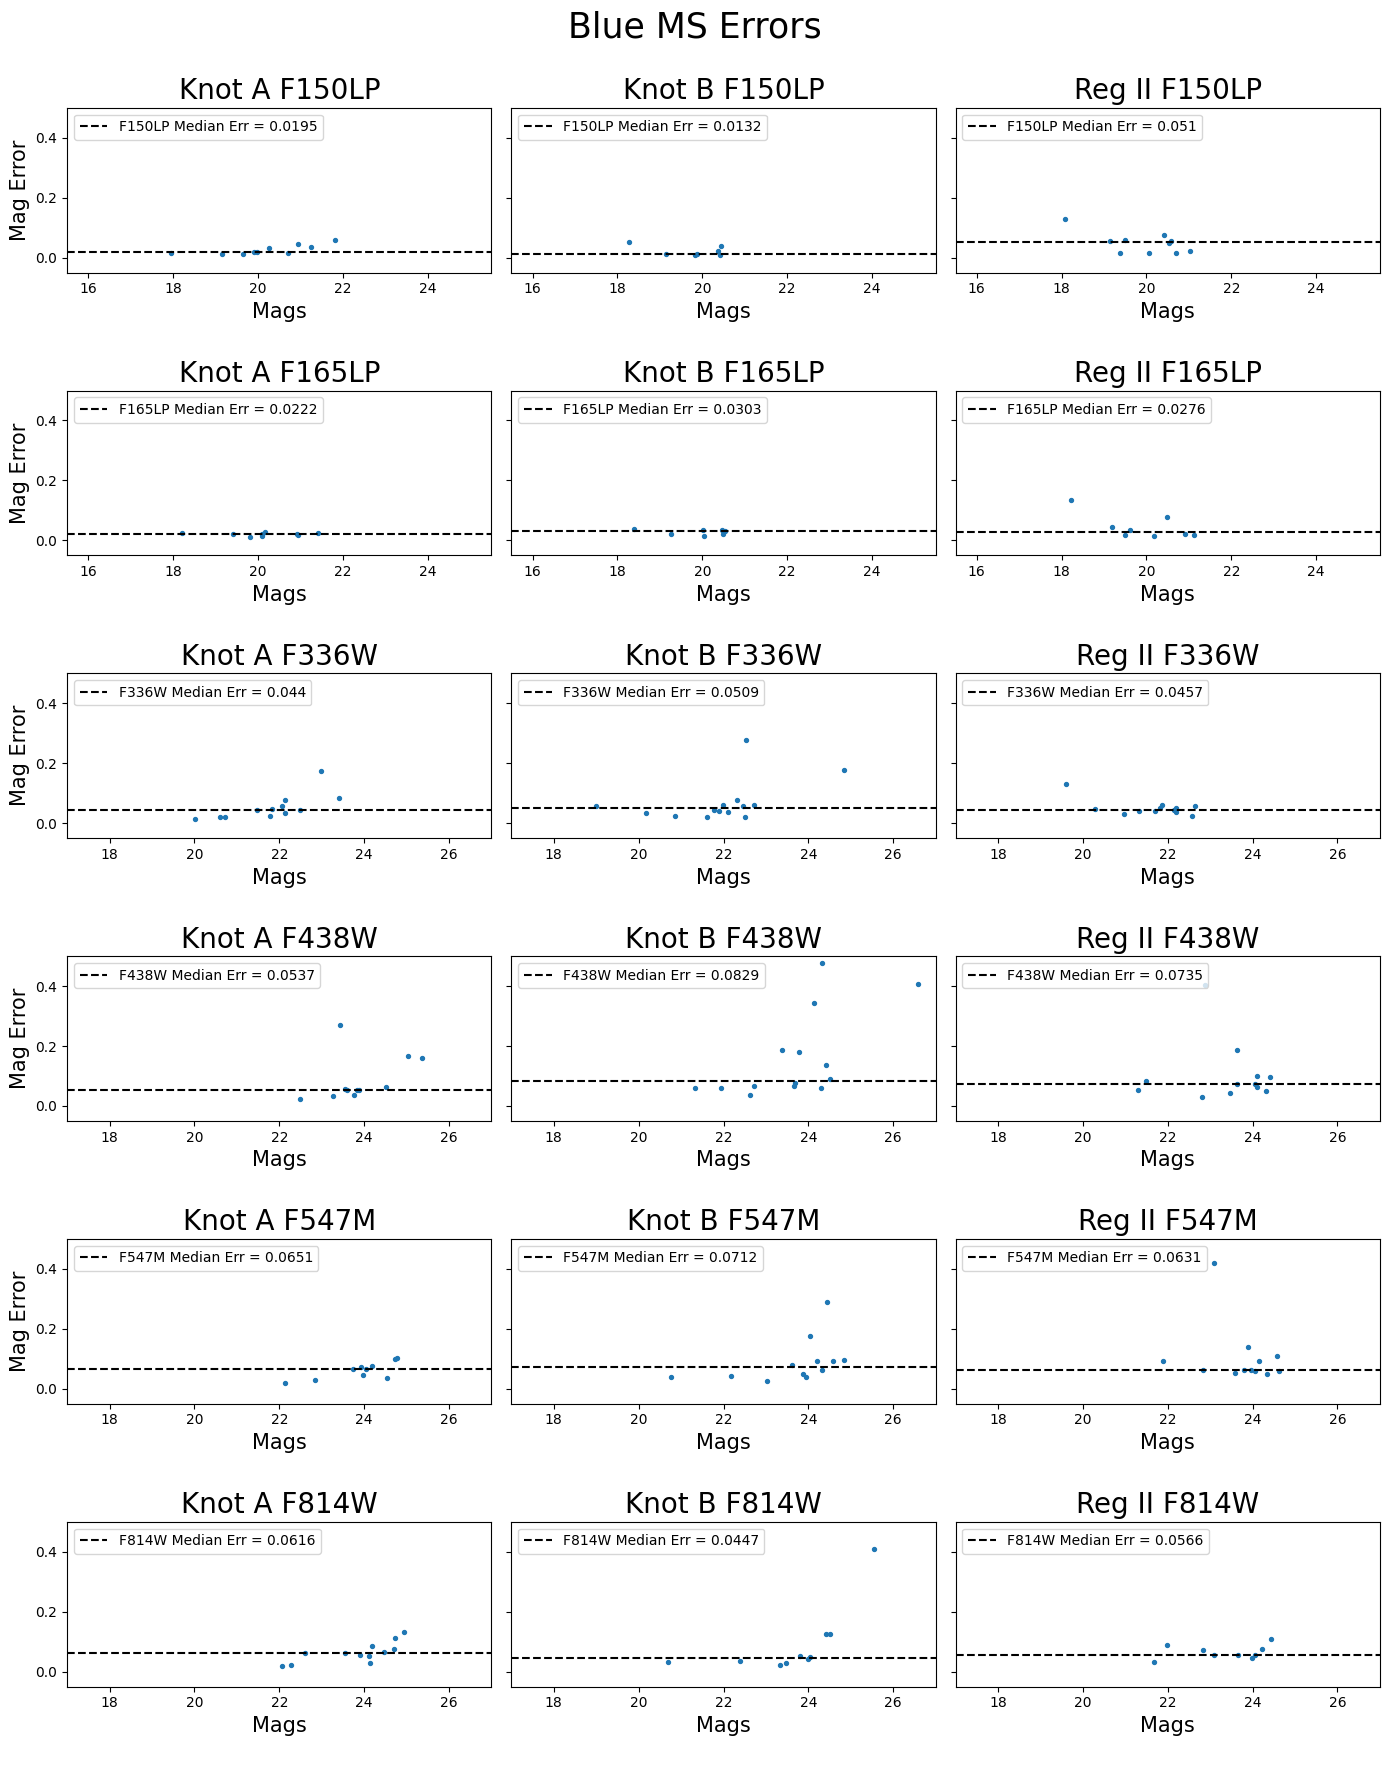

In [ ]:
show_band_errors(catalogs=[knota_blue_ms,knotb_blue_ms,regii_blue_ms],title='Blue MS Errors\n')
plt.show()

In [ ]:
knota_yr_ubright.loc[30][['x_fit_med','y_fit_med',
                       'F150LP','F165LP','F336W',
                       'F438W','F547M','F814W',
                       'distance']]#sort_values(by='x')

,30
x_fit_med,26.078745
y_fit_med,75.109533
F150LP,20.331842
F165LP,20.515171
F336W,21.931662
F438W,23.341804
F547M,24.011742
F814W,NaN
distance,56.628303


In [ ]:
knota_catalog_filtered.loc[30][['x_fit_med','y_fit_med',
                       'F150LP','F165LP','F336W',
                       'F438W','F547M','F814W',
                       'distance']]#sort_values(by='x')

,30
x_fit_med,26.078745
y_fit_med,75.109533
F150LP,20.331842
F165LP,20.515171
F336W,21.931662
F438W,23.341804
F547M,24.011742
F814W,NaN
distance,56.628303


In [ ]:
print(knota_catalog_filtered.loc[30,'F814W'])
knota_catalog_filtered.loc[30,'F814W'] = np.nan
print(knota_catalog_filtered.loc[30,'F814W'])

nan
nan


In [ ]:
print(knota_yr_ubright.loc[30,'F814W'])
knota_yr_ubright.loc[30,'F814W'] = np.nan
print(knota_yr_ubright.loc[30,'F814W'])

nan
nan


In [ ]:
knota_catalog_filtered.sort_values(by='x')[['x','x_fit_med','y',
                                            'y_fit_med',
                                            'F150LP','F165LP',
                                            'F336W',
                                            'F438W','F547M',
                                            'F814W',
                                            'distance']].head(20)

,x,x_fit_med,y,y_fit_med,F150LP,F165LP,F336W,F438W,F547M,F814W,distance
93,12.594815,NaN,144.608304,NaN,NaN,NaN,NaN,NaN,NaN,NaN,40.437181
195,15.600452,2.600452,111.385096,98.385096,19.844975,19.997358,21.634101,23.078243,23.621715,23.500520,48.971710
462,15.752790,2.752790,144.902408,131.902408,NaN,NaN,NaN,NaN,24.200353,23.940977,37.295761
185,16.343386,3.343386,80.503093,67.503093,21.867094,NaN,NaN,24.482151,NaN,NaN,72.453922
177,16.591414,3.627024,326.706488,313.691366,NaN,17.318041,19.232092,20.757716,21.219270,21.416793,187.279628
58,17.743670,4.743670,115.172739,102.172739,17.390824,17.520938,19.113617,20.630197,21.087716,21.458209,44.915089
448,17.976482,4.926821,226.206356,213.237394,NaN,NaN,NaN,NaN,NaN,23.988672,90.277043
323,18.828639,5.828639,146.771974,133.771974,NaN,NaN,22.188837,23.851311,24.408248,24.446478,34.378914
75,20.088089,7.088089,129.412603,116.412603,20.685391,NaN,22.318612,23.174016,23.761101,24.315937,35.606337
348,20.694393,7.694393,116.099856,103.099856,NaN,NaN,21.744001,23.104584,23.545408,23.187428,42.038910


In [ ]:
# def get_stellar_pop_stats_new(catalog):
#     [[rsgs,rsgs_ubright,rsgs_ufaint,rsgs_nou],
#      [yr,yr_ufaint,yr_ubright,yr_nou,yr_nou_fuv],
#      [ms,ms_ubright,ms_ufaint]] = get_star_groups(catalog, export_files = False)

#     vals = {'Total' : int(len(catalog)),

#             'MS' : len(catalog) - len(yr), #len(ms),
#             'MS, U < 23' : len(ms_ubright),

#             'All RSG': len(rsgs),
#             'RSG, U < 23' : len(rsgs_ubright),
#             'RSG, U > 23' : len(rsgs_ufaint),
#             'RSG, no U' : len(rsgs_nou),

#             'All Y/R' : len(yr),
#             'Y/R, U < 23' : len(yr_ubright),
#             'Y/R, U > 23' : len(yr_ufaint),
#             'Y/R, no U' : len(yr_nou),
#             'Y/R, no U, with FUV' : len(yr_nou_fuv),

#             'MS (%)' : round((len(catalog) - len(yr)) / len(catalog) * 100,2),
#             'MS, U < 23 (%)' : round((len(ms_ubright)) / len(catalog) * 100,2),

#             'All RSG (%)' : round(len(rsgs) / len(catalog) * 100,2),
#             'RSG, U < 23 (%)' : round(len(rsgs_ubright) / len(catalog) * 100,2),
#             'RSG, U > 23 (%)' : round(len(rsgs_ufaint) / len(catalog) * 100,2),
#             'RSG, no U (%)' : round(len(rsgs_nou) / len(catalog) * 100,2),

#             'All Y/R (%)' : round(len(yr) / len(catalog) * 100,2),
#             'Y/R, U < 23 (%)' : round(len(yr_ubright) / len(catalog) * 100,2),
#             'Y/R, U > 23 (%)' : round(len(yr_ufaint) / len(catalog) * 100,2),
#             'Y/R, no U (%)' : round(len(yr_nou) / len(catalog) * 100,2),
#             'Y/R, no U, with FUV (%)' : round(len(yr_nou_fuv) / len(catalog) * 100,2)
#            }

#     return vals

# def get_stellar_pop_stats_errs_new(catalog):
#     stats_dict = get_stellar_pop_stats_new(catalog)
#     round_dec = 1
#     errs = dict()
#     total_stars = stats_dict['Total']

#     for row, (key, val) in enumerate(stats_dict.items()):
#         if row < 10:
#             errs[key] = round(poisson(val),round_dec)
#         else:
#             errs[key] = round(poisson_adivb(val,total_stars)*100,round_dec)

#     return errs

# def get_stellar_pop_column_new(catalog,name='col'):
#     vals = get_stellar_pop_stats_new(catalog)
#     column = pd.Series(vals,name=name)
#     return column

# def get_stellar_pop_err_column_new(catalog,name='err_col'):
#     errs = get_stellar_pop_stats_errs_new(catalog)
#     column = pd.Series(errs,name=name)
#     return column

# def get_stellar_pops_witherrs_column_new(catalog,name='Region'):
#     vals_col = get_stellar_pop_column_new(catalog,name=name)
#     errs_col = get_stellar_pop_err_column_new(catalog,name=name)

#     ufloats = [ufloat(value,errs_col.iloc[ix]) for ix, value in enumerate(vals_col)]
#     uarr = UncertaintyArray(ufloats)

#     column = pd.Series(uarr,name=name,index=vals_col.index)

#     return column

# def get_all_stellar_pop_stats_witherrs_new(catalogs,names=['KnotA','KnotB','RegII'],mode='newcol'):
#     cols = []

#     if mode == 'newcol':
#         for ix, catalog in enumerate(catalogs):
#             cols.append(get_stellar_pop_column_new(catalog,name=names[ix]))
#         for ix, catalog in enumerate(catalogs):
#             cols.append(get_stellar_pop_err_column_new(catalog,name=f'{names[ix]}_Err'))

#     elif mode == 'radial':
#         for ix, catalog in enumerate(catalogs):
#             groups = [catalog.loc[catalog['distance']<50.],
#                   catalog.loc[(catalog['distance']>=50.) &
#                       (catalog['distance']<=125.)],
#                   catalog.loc[catalog['distance']>125.],
#                   catalog]
#             col_names = ['< 50 px','50 - 125 px','> 125 px','All']
#             for iy, group in enumerate(groups):
#                 cols.append(get_stellar_pops_witherrs_column_new(group,name=f'{names[ix]} {col_names[iy]}'))

#     else:
#         for ix, catalog in enumerate(catalogs):
#             cols.append(get_stellar_pops_witherrs_column_new(catalog,name=names[ix]))

#     df = pd.concat(cols, axis=1)

#     return df

In [ ]:
catalogs = [knota_catalog_filtered,knotb_catalog_filtered,regii_catalog_filtered]
stats_table = get_all_stellar_pop_stats_witherrs_new(catalogs)#,mode='radial')
display(stats_table)

/tmp/ipykernel_955/2879537286.py:18: RuntimeWarning:

invalid value encountered in scalar divide

/tmp/ipykernel_955/2879537286.py:18: RuntimeWarning:

invalid value encountered in scalar divide

/tmp/ipykernel_955/2879537286.py:18: RuntimeWarning:

invalid value encountered in scalar divide



,KnotA,KnotB,RegII,KnotA_Err,KnotB_Err,RegII_Err
Total,354.00,302.00,514.00,18.8,17.4,22.7
MS,287.00,268.00,403.00,16.9,16.4,20.1
"MS, U < 23",174.00,198.00,258.00,13.2,14.1,16.1
All RSG,6.00,2.00,23.00,2.4,1.4,4.8
"RSG, U < 23",1.00,0.00,2.00,1.0,0.0,1.4
"RSG, U > 23",3.00,0.00,5.00,1.7,0.0,2.2
"RSG, no U",2.00,2.00,16.00,1.4,1.4,4.0
All Y/R,67.00,34.00,111.00,8.2,5.8,10.5
"Y/R, U < 23",39.00,14.00,24.00,6.2,3.7,4.9
"Y/R, U > 23",9.00,6.00,35.00,3.0,2.4,5.9


In [ ]:
catalogs = [knota_catalog_filtered,knotb_catalog_filtered,regii_catalog_filtered]

factors=[[1,1,1,1],
         [1,1,1,1],
         [1,1,1,1]]

        # knota_fac = [1.047,1.522,1,1]
        # knotb_fac = [1,1.174,1,1]
        # regii_fac = [1,1.033,1,1]
        # factors = [knota_fac,knotb_fac,regii_fac]

stats_table = get_all_stellar_pop_stats_witherrs_new(catalogs,mode='radial',factors=factors)
display(stats_table)

/tmp/ipykernel_955/2879537286.py:18: RuntimeWarning:

invalid value encountered in scalar divide

/tmp/ipykernel_955/2879537286.py:18: RuntimeWarning:

invalid value encountered in scalar divide

/tmp/ipykernel_955/2879537286.py:18: RuntimeWarning:

invalid value encountered in scalar divide

/tmp/ipykernel_955/2879537286.py:18: RuntimeWarning:

invalid value encountered in scalar divide

/tmp/ipykernel_955/2879537286.py:18: RuntimeWarning:

invalid value encountered in scalar divide

/tmp/ipykernel_955/2879537286.py:18: RuntimeWarning:

invalid value encountered in scalar divide

/tmp/ipykernel_955/2879537286.py:18: RuntimeWarning:

invalid value encountered in scalar divide

/tmp/ipykernel_955/2879537286.py:18: RuntimeWarning:

invalid value encountered in scalar divide

/tmp/ipykernel_955/2879537286.py:18: RuntimeWarning:

invalid value encountered in scalar divide

/tmp/ipykernel_955/2879537286.py:18: RuntimeWarning:

invalid value encountered in scalar divide

/tmp/ipykernel_955/2

,KnotA < 50 px,KnotA 50 - 125 px,KnotA > 125 px,KnotA All,KnotB < 50 px,KnotB 50 - 125 px,KnotB > 125 px,KnotB All,RegII < 50 px,RegII 50 - 125 px,RegII > 125 px,RegII All
Total,116+/-11,109+/-10,129+/-11,354+/-19,121+/-11,137+/-12,44+/-7,302+/-17,81+/-9,139+/-12,294+/-17,514+/-23
MS,77+/-9,95+/-10,115+/-11,287+/-17,114+/-11,118+/-11,36+/-6,268+/-16,70+/-8,106+/-10,227+/-15,403+/-20
"MS, U < 23",52+/-7,72+/-8,50+/-7,174+/-13,103+/-10,84+/-9,11.0+/-3.3,198+/-14,56+/-8,70+/-8,132+/-12,258+/-16
All RSG,0.0+/-0,3.0+/-1.7,3.0+/-1.7,6.0+/-2.4,0.0+/-0,1.0+/-1.0,1.0+/-1.0,2.0+/-1.4,1.0+/-1.0,10.0+/-3.2,12.0+/-3.5,23+/-5
"RSG, U < 23",0.0+/-0,1.0+/-1.0,0.0+/-0,1.0+/-1.0,0.0+/-0,0.0+/-0,0.0+/-0,0.0+/-0,0.0+/-0,1.0+/-1.0,1.0+/-1.0,2.0+/-1.4
"RSG, U > 23",0.0+/-0,2.0+/-1.4,1.0+/-1.0,3.0+/-1.7,0.0+/-0,0.0+/-0,0.0+/-0,0.0+/-0,0.0+/-0,3.0+/-1.7,2.0+/-1.4,5.0+/-2.2
"RSG, no U",0.0+/-0,0.0+/-0,2.0+/-1.4,2.0+/-1.4,0.0+/-0,1.0+/-1.0,1.0+/-1.0,2.0+/-1.4,1.0+/-1.0,6.0+/-2.4,9.0+/-3.0,16+/-4
All Y/R,39+/-6,14+/-4,14+/-4,67+/-8,7.0+/-2.6,19+/-4,8.0+/-2.8,34+/-6,11.0+/-3.3,33+/-6,67+/-8,111+/-10
"Y/R, U < 23",31+/-6,7.0+/-2.6,1.0+/-1.0,39+/-6,4.0+/-2.0,9.0+/-3.0,1.0+/-1.0,14+/-4,6.0+/-2.4,8.0+/-2.8,10.0+/-3.2,24+/-5
"Y/R, U > 23",2.0+/-1.4,2.0+/-1.4,5.0+/-2.2,9.0+/-3.0,2.0+/-1.4,4.0+/-2.0,0.0+/-0,6.0+/-2.4,1.0+/-1.0,11.0+/-3.3,23+/-5,35+/-6


In [ ]:
catalogs = [knota_catalog_filtered,knotb_catalog_filtered,regii_catalog_filtered]
stats_table = get_all_stellar_pop_stats_witherrs_new(catalogs,mode='radial')
display(stats_table)

/tmp/ipykernel_955/2879537286.py:18: RuntimeWarning:

invalid value encountered in scalar divide

/tmp/ipykernel_955/2879537286.py:18: RuntimeWarning:

invalid value encountered in scalar divide

/tmp/ipykernel_955/2879537286.py:18: RuntimeWarning:

invalid value encountered in scalar divide

/tmp/ipykernel_955/2879537286.py:18: RuntimeWarning:

invalid value encountered in scalar divide

/tmp/ipykernel_955/2879537286.py:18: RuntimeWarning:

invalid value encountered in scalar divide

/tmp/ipykernel_955/2879537286.py:18: RuntimeWarning:

invalid value encountered in scalar divide

/tmp/ipykernel_955/2879537286.py:18: RuntimeWarning:

invalid value encountered in scalar divide

/tmp/ipykernel_955/2879537286.py:18: RuntimeWarning:

invalid value encountered in scalar divide

/tmp/ipykernel_955/2879537286.py:18: RuntimeWarning:

invalid value encountered in scalar divide

/tmp/ipykernel_955/2879537286.py:18: RuntimeWarning:

invalid value encountered in scalar divide

/tmp/ipykernel_955/2

,KnotA < 50 px,KnotA 50 - 125 px,KnotA > 125 px,KnotA All,KnotB < 50 px,KnotB 50 - 125 px,KnotB > 125 px,KnotB All,RegII < 50 px,RegII 50 - 125 px,RegII > 125 px,RegII All
Total,121+/-11,166+/-16,129+/-11,354+/-19,121+/-11,161+/-14,44+/-7,302+/-17,81+/-9,144+/-12,294+/-17,514+/-23
MS,81+/-9,145+/-15,115+/-11,287+/-17,114+/-11,139+/-13,36+/-6,268+/-16,70+/-8,109+/-11,227+/-15,403+/-20
"MS, U < 23",54+/-8,110+/-13,50+/-7,174+/-13,103+/-10,99+/-11,11.0+/-3.3,198+/-14,56+/-8,72+/-9,132+/-12,258+/-16
All RSG,0.0+/-0,4.6+/-2.6,3.0+/-1.7,6.0+/-2.4,0.0+/-0,1.2+/-1.2,1.0+/-1.0,2.0+/-1.4,1.0+/-1.0,10.3+/-3.3,12.0+/-3.5,23+/-5
"RSG, U < 23",0.0+/-0,1.5+/-1.5,0.0+/-0,1.0+/-1.0,0.0+/-0,0.0+/-0,0.0+/-0,0.0+/-0,0.0+/-0,1.0+/-1.0,1.0+/-1.0,2.0+/-1.4
"RSG, U > 23",0.0+/-0,3.0+/-2.2,1.0+/-1.0,3.0+/-1.7,0.0+/-0,0.0+/-0,0.0+/-0,0.0+/-0,0.0+/-0,3.1+/-1.8,2.0+/-1.4,5.0+/-2.2
"RSG, no U",0.0+/-0,0.0+/-0,2.0+/-1.4,2.0+/-1.4,0.0+/-0,1.2+/-1.2,1.0+/-1.0,2.0+/-1.4,1.0+/-1.0,6.2+/-2.5,9.0+/-3.0,16+/-4
All Y/R,41+/-6,21+/-6,14+/-4,67+/-8,7.0+/-2.6,22+/-5,8.0+/-2.8,34+/-6,11.0+/-3.3,34+/-6,67+/-8,111+/-10
"Y/R, U < 23",32+/-6,11+/-4,1.0+/-1.0,39+/-6,4.0+/-2.0,10.6+/-3.5,1.0+/-1.0,14+/-4,6.0+/-2.4,8.3+/-2.9,10.0+/-3.2,24+/-5
"Y/R, U > 23",2.1+/-1.5,3.0+/-2.2,5.0+/-2.2,9.0+/-3.0,2.0+/-1.4,4.7+/-2.3,0.0+/-0,6.0+/-2.4,1.0+/-1.0,11.4+/-3.4,23+/-5,35+/-6


In [ ]:
catalogs = [knota_catalog_filtered,knotb_catalog_filtered,regii_catalog_filtered]
stats_table = get_all_stellar_pop_stats_witherrs_new(catalogs,mode='radial')
display(stats_table)

/tmp/ipykernel_955/2879537286.py:18: RuntimeWarning:

invalid value encountered in scalar divide

/tmp/ipykernel_955/2879537286.py:18: RuntimeWarning:

invalid value encountered in scalar divide

/tmp/ipykernel_955/2879537286.py:18: RuntimeWarning:

invalid value encountered in scalar divide

/tmp/ipykernel_955/2879537286.py:18: RuntimeWarning:

invalid value encountered in scalar divide

/tmp/ipykernel_955/2879537286.py:18: RuntimeWarning:

invalid value encountered in scalar divide

/tmp/ipykernel_955/2879537286.py:18: RuntimeWarning:

invalid value encountered in scalar divide

/tmp/ipykernel_955/2879537286.py:18: RuntimeWarning:

invalid value encountered in scalar divide

/tmp/ipykernel_955/2879537286.py:18: RuntimeWarning:

invalid value encountered in scalar divide

/tmp/ipykernel_955/2879537286.py:18: RuntimeWarning:

invalid value encountered in scalar divide

/tmp/ipykernel_955/2879537286.py:18: RuntimeWarning:

invalid value encountered in scalar divide

/tmp/ipykernel_955/2

,KnotA < 50 px,KnotA 50 - 125 px,KnotA > 125 px,KnotA All,KnotB < 50 px,KnotB 50 - 125 px,KnotB > 125 px,KnotB All,RegII < 50 px,RegII 50 - 125 px,RegII > 125 px,RegII All
Total,121+/-11,166+/-16,129+/-11,354+/-19,121+/-11,161+/-14,44+/-7,302+/-17,81+/-9,144+/-12,294+/-17,514+/-23
MS,81+/-9,145+/-15,115+/-11,287+/-17,114+/-11,139+/-13,36+/-6,268+/-16,70+/-8,109+/-11,227+/-15,403+/-20
"MS, U < 23",54+/-8,110+/-13,50+/-7,174+/-13,103+/-10,99+/-11,11.0+/-3.3,198+/-14,56+/-8,72+/-9,132+/-12,258+/-16
All RSG,0.0+/-0,4.6+/-2.6,3.0+/-1.7,6.0+/-2.4,0.0+/-0,1.2+/-1.2,1.0+/-1.0,2.0+/-1.4,1.0+/-1.0,10.3+/-3.3,12.0+/-3.5,23+/-5
"RSG, U < 23",0.0+/-0,1.5+/-1.5,0.0+/-0,1.0+/-1.0,0.0+/-0,0.0+/-0,0.0+/-0,0.0+/-0,0.0+/-0,1.0+/-1.0,1.0+/-1.0,2.0+/-1.4
"RSG, U > 23",0.0+/-0,3.0+/-2.2,1.0+/-1.0,3.0+/-1.7,0.0+/-0,0.0+/-0,0.0+/-0,0.0+/-0,0.0+/-0,3.1+/-1.8,2.0+/-1.4,5.0+/-2.2
"RSG, no U",0.0+/-0,0.0+/-0,2.0+/-1.4,2.0+/-1.4,0.0+/-0,1.2+/-1.2,1.0+/-1.0,2.0+/-1.4,1.0+/-1.0,6.2+/-2.5,9.0+/-3.0,16+/-4
All Y/R,41+/-6,21+/-6,14+/-4,67+/-8,7.0+/-2.6,22+/-5,8.0+/-2.8,34+/-6,11.0+/-3.3,34+/-6,67+/-8,111+/-10
"Y/R, U < 23",32+/-6,11+/-4,1.0+/-1.0,39+/-6,4.0+/-2.0,10.6+/-3.5,1.0+/-1.0,14+/-4,6.0+/-2.4,8.3+/-2.9,10.0+/-3.2,24+/-5
"Y/R, U > 23",2.1+/-1.5,3.0+/-2.2,5.0+/-2.2,9.0+/-3.0,2.0+/-1.4,4.7+/-2.3,0.0+/-0,6.0+/-2.4,1.0+/-1.0,11.4+/-3.4,23+/-5,35+/-6


In [ ]:
stats_table['KnotA_Total'] = stats_table[['KnotA < 50 px', 'KnotA 50 - 125 px', 'KnotA > 125 px']].sum(axis=1)
stats_table['KnotB_Total'] = stats_table[['KnotB < 50 px', 'KnotB 50 - 125 px', 'KnotB > 125 px']].sum(axis=1)
stats_table['RegII_Total'] = stats_table[['RegII < 50 px', 'RegII 50 - 125 px', 'RegII > 125 px']].sum(axis=1)
stats_table

,KnotA < 50 px,KnotA 50 - 125 px,KnotA > 125 px,KnotA All,KnotB < 50 px,KnotB 50 - 125 px,KnotB > 125 px,KnotB All,RegII < 50 px,RegII 50 - 125 px,RegII > 125 px,RegII All,KnotA_Total,KnotB_Total,RegII_Total
Total,121+/-11,166+/-16,129+/-11,354+/-19,121+/-11,161+/-14,44+/-7,302+/-17,81+/-9,144+/-12,294+/-17,514+/-23,416+/-23,326+/-19,519+/-23
MS,81+/-9,145+/-15,115+/-11,287+/-17,114+/-11,139+/-13,36+/-6,268+/-16,70+/-8,109+/-11,227+/-15,403+/-20,340+/-20,289+/-18,406+/-20
"MS, U < 23",54+/-8,110+/-13,50+/-7,174+/-13,103+/-10,99+/-11,11.0+/-3.3,198+/-14,56+/-8,72+/-9,132+/-12,258+/-16,214+/-17,213+/-15,260+/-16
All RSG,0.0+/-0,4.6+/-2.6,3.0+/-1.7,6.0+/-2.4,0.0+/-0,1.2+/-1.2,1.0+/-1.0,2.0+/-1.4,1.0+/-1.0,10.3+/-3.3,12.0+/-3.5,23+/-5,7.6+/-3.1,2.2+/-1.6,23+/-5
"RSG, U < 23",0.0+/-0,1.5+/-1.5,0.0+/-0,1.0+/-1.0,0.0+/-0,0.0+/-0,0.0+/-0,0.0+/-0,0.0+/-0,1.0+/-1.0,1.0+/-1.0,2.0+/-1.4,1.5+/-1.5,0.0+/-0,2.0+/-1.4
"RSG, U > 23",0.0+/-0,3.0+/-2.2,1.0+/-1.0,3.0+/-1.7,0.0+/-0,0.0+/-0,0.0+/-0,0.0+/-0,0.0+/-0,3.1+/-1.8,2.0+/-1.4,5.0+/-2.2,4.0+/-2.4,0.0+/-0,5.1+/-2.3
"RSG, no U",0.0+/-0,0.0+/-0,2.0+/-1.4,2.0+/-1.4,0.0+/-0,1.2+/-1.2,1.0+/-1.0,2.0+/-1.4,1.0+/-1.0,6.2+/-2.5,9.0+/-3.0,16+/-4,2.0+/-1.4,2.2+/-1.6,16+/-4
All Y/R,41+/-6,21+/-6,14+/-4,67+/-8,7.0+/-2.6,22+/-5,8.0+/-2.8,34+/-6,11.0+/-3.3,34+/-6,67+/-8,111+/-10,76+/-9,37+/-6,112+/-11
"Y/R, U < 23",32+/-6,11+/-4,1.0+/-1.0,39+/-6,4.0+/-2.0,10.6+/-3.5,1.0+/-1.0,14+/-4,6.0+/-2.4,8.3+/-2.9,10.0+/-3.2,24+/-5,44+/-7,16+/-4,24+/-5
"Y/R, U > 23",2.1+/-1.5,3.0+/-2.2,5.0+/-2.2,9.0+/-3.0,2.0+/-1.4,4.7+/-2.3,0.0+/-0,6.0+/-2.4,1.0+/-1.0,11.4+/-3.4,23+/-5,35+/-6,10.1+/-3.5,6.7+/-2.7,35+/-6


In [ ]:
for val in stats_table['RegII All'].values:
    print(val)

514+/-23
403+/-20
258+/-16
23+/-5
2.0+/-1.4
5.0+/-2.2
16+/-4
111+/-10
24+/-5
35+/-6
52+/-7
0.0+/-0
78.4+/-1.8
4.5+/-0.4
0.39+/-0.10
0.97+/-0.20
3.11+/-0.30
21.6+/-0.9
4.7+/-0.4
6.8+/-0.5
10.1+/-0.6
0.0+/-nan


In [ ]:
stats_table[['KnotB < 50 px', 'KnotB 50 - 125 px', 'KnotB > 125 px']].sum(axis=1)

,0
Total,326+/-19
MS,289+/-18
"MS, U < 23",213+/-15
All RSG,2.2+/-1.6
"RSG, U < 23",0.0+/-0
"RSG, U > 23",0.0+/-0
"RSG, no U",2.2+/-1.6
All Y/R,37+/-6
"Y/R, U < 23",16+/-4
"Y/R, U > 23",6.7+/-2.7


In [ ]:
catalogs = [knota_catalog_filtered,knotb_catalog_filtered,regii_catalog_filtered]
get_all_stellar_pop_stats_witherrs_new(catalogs,mode='radial')

/tmp/ipykernel_955/2879537286.py:18: RuntimeWarning:

invalid value encountered in scalar divide

/tmp/ipykernel_955/2879537286.py:18: RuntimeWarning:

invalid value encountered in scalar divide

/tmp/ipykernel_955/2879537286.py:18: RuntimeWarning:

invalid value encountered in scalar divide

/tmp/ipykernel_955/2879537286.py:18: RuntimeWarning:

invalid value encountered in scalar divide

/tmp/ipykernel_955/2879537286.py:18: RuntimeWarning:

invalid value encountered in scalar divide

/tmp/ipykernel_955/2879537286.py:18: RuntimeWarning:

invalid value encountered in scalar divide

/tmp/ipykernel_955/2879537286.py:18: RuntimeWarning:

invalid value encountered in scalar divide

/tmp/ipykernel_955/2879537286.py:18: RuntimeWarning:

invalid value encountered in scalar divide

/tmp/ipykernel_955/2879537286.py:18: RuntimeWarning:

invalid value encountered in scalar divide

/tmp/ipykernel_955/2879537286.py:18: RuntimeWarning:

invalid value encountered in scalar divide

/tmp/ipykernel_955/2

,KnotA < 50 px,KnotA 50 - 125 px,KnotA > 125 px,KnotA All,KnotB < 50 px,KnotB 50 - 125 px,KnotB > 125 px,KnotB All,RegII < 50 px,RegII 50 - 125 px,RegII > 125 px,RegII All
Total,121+/-11,166+/-16,129+/-11,354+/-19,121+/-11,161+/-14,44+/-7,302+/-17,81+/-9,144+/-12,294+/-17,514+/-23
MS,81+/-9,145+/-15,115+/-11,287+/-17,114+/-11,139+/-13,36+/-6,268+/-16,70+/-8,109+/-11,227+/-15,403+/-20
"MS, U < 23",54+/-8,110+/-13,50+/-7,174+/-13,103+/-10,99+/-11,11.0+/-3.3,198+/-14,56+/-8,72+/-9,132+/-12,258+/-16
All RSG,0.0+/-0,4.6+/-2.6,3.0+/-1.7,6.0+/-2.4,0.0+/-0,1.2+/-1.2,1.0+/-1.0,2.0+/-1.4,1.0+/-1.0,10.3+/-3.3,12.0+/-3.5,23+/-5
"RSG, U < 23",0.0+/-0,1.5+/-1.5,0.0+/-0,1.0+/-1.0,0.0+/-0,0.0+/-0,0.0+/-0,0.0+/-0,0.0+/-0,1.0+/-1.0,1.0+/-1.0,2.0+/-1.4
"RSG, U > 23",0.0+/-0,3.0+/-2.2,1.0+/-1.0,3.0+/-1.7,0.0+/-0,0.0+/-0,0.0+/-0,0.0+/-0,0.0+/-0,3.1+/-1.8,2.0+/-1.4,5.0+/-2.2
"RSG, no U",0.0+/-0,0.0+/-0,2.0+/-1.4,2.0+/-1.4,0.0+/-0,1.2+/-1.2,1.0+/-1.0,2.0+/-1.4,1.0+/-1.0,6.2+/-2.5,9.0+/-3.0,16+/-4
All Y/R,41+/-6,21+/-6,14+/-4,67+/-8,7.0+/-2.6,22+/-5,8.0+/-2.8,34+/-6,11.0+/-3.3,34+/-6,67+/-8,111+/-10
"Y/R, U < 23",32+/-6,11+/-4,1.0+/-1.0,39+/-6,4.0+/-2.0,10.6+/-3.5,1.0+/-1.0,14+/-4,6.0+/-2.4,8.3+/-2.9,10.0+/-3.2,24+/-5
"Y/R, U > 23",2.1+/-1.5,3.0+/-2.2,5.0+/-2.2,9.0+/-3.0,2.0+/-1.4,4.7+/-2.3,0.0+/-0,6.0+/-2.4,1.0+/-1.0,11.4+/-3.4,23+/-5,35+/-6


# **Plotting**

In [ ]:
## Plotting functions

# Add symbols to CMD legend for stellar populations
# Surprisingly the quickest way to do it given current Plotly version

def add_symbol_legend(fig,
                      label1='MS',
                      label2='RSG',
                      label3='Y/R',
                      sym1='circle',
                      sym2='square',
                      sym3='triangle-up',
                      color1='blue',
                      color2='black',
                      color3='black',
                      **kwargs):
    # Add legend for symbols (not done automatically in Plotly when there's
    # also a color legend)

    fig.add_trace(go.Scatter(y=[None], mode='markers',
                             marker=dict(symbol=sym1,color=color1),
                             name=label1, legendgroup="group",
                             legendgrouptitle_text="",
                             ))

    fig.add_trace(go.Scatter(y=[None], mode='markers',legendgroup="group",
                             marker=dict(symbol=sym2,color=color2),
                             name=label2))

    fig.add_trace(go.Scatter(y=[None], mode='markers',legendgroup="group",
                             marker=dict(symbol=sym3,color=color3),
                             name=label3))
    # fig.add_trace(go.Scatter(y=[None], mode='markers',legendgroup="group",
    #                          marker=dict(symbol=sym4,color=color4),
    #                          name=label4))

    # fig.update_layout(legend2=dict(title=dict(text = 'Stars')),**kwargs)

    return None

# Get TLUSTY-IndoUS isochrones
def load_tlusty_isos(ages=['4','6','10','20','40','50','100']):
    if os.getcwd() != tindo_path:
        os.chdir(tindo_path)

    isos = []

    for age in ages:
        iso = pd.read_csv(f'tindo_{age}Myr_STandVega.csv')
        isos.append(iso)

    return isos

# Add isochrones to standard optical CMD set
# "dash" = dashboard, AKA the interactive CMD sets
def plot_tlusty_isos_cmd_optical_dash(fig, isos=None, ages = ['4','6','10','20','40','50','100'],
                                      colors = ['blue', 'magenta', 'green','goldenrod','purple',
                                                'orange','teal'],legend_title="T-Indo Isochrones"):

    if isos==None:
        isos = load_tlusty_isos(ages)

    for row_num in [1,2,3]:
        for ii, isochrone in enumerate(isos):
            fig.add_trace(go.Scatter(x=isochrone['U_vega']-isochrone['B_vega'], y=isochrone['B_vega'],
                                     name=f"{ages[ii]} Myr",
                                     mode='lines', legendgroup=str(ages[ii]),
                                     line=dict(width=2, color=colors[ii]),
                                     showlegend=(row_num==1)
                                     ), row=row_num, col=1)

            fig.add_trace(go.Scatter(x=isochrone['B_vega']-isochrone['V_vega'], y=isochrone['V_vega'],
                                     name=f"{ages[ii]} Myr",
                                     mode='lines', legendgroup=str(ages[ii]),
                                     line=dict(width=2, color=colors[ii]),
                                     showlegend=False
                                     ), row=row_num, col=2)

            fig.add_trace(go.Scatter(x=isochrone['V_vega']-isochrone['I_vega'], y=isochrone['I_vega'],
                                     name=f"{ages[ii]} Myr",
                                     mode='lines', legendgroup=str(ages[ii]),
                                     line=dict(width=2, color=colors[ii]),
                                     showlegend=False
                                     ), row=row_num, col=3)
    fig.update_layout(legend=dict(title=dict(text = legend_title)))

    return fig

# Add T-IndoUS isos to FUV/optical CMDs
def plot_tlusty_isos_ccd_optfuv_dash(fig, isos=None, ages = ['4','6','10','20','40','50','100'],
                                      colors = ['blue', 'magenta', 'green','goldenrod','purple',
                                                'orange','teal'],legend_title=''):#T-Indo Isochrones'):

    if isos==None:
        isos = load_tlusty_isos(ages)

    for row_num in [1,2,3]:
        for ii, isochrone in enumerate(isos):
            fig.add_trace(go.Scatter(x=isochrone['V_vega']-isochrone['I_vega'],
                                     y=isochrone['U_vega']-isochrone['B_vega'],
                                     name=f"{ages[ii]} Myr",
                                     mode='lines', legendgroup=str(ages[ii]),
                                     line=dict(width=2, color=colors[ii]),
                                     showlegend=(row_num==1)
                                     ), row=row_num, col=1)

            fig.add_trace(go.Scatter(x=isochrone['V_vega']-isochrone['I_vega'],
                                     y=isochrone['B_vega']-isochrone['V_vega'],
                                     name=f"{ages[ii]} Myr",
                                     mode='lines', legendgroup=str(ages[ii]),
                                     line=dict(width=2, color=colors[ii]),
                                     showlegend=False
                                     ), row=row_num, col=2)

            fig.add_trace(go.Scatter(x=isochrone['V_vega']-isochrone['I_vega'],
                                     y=isochrone['FUV150_vega']-isochrone['U_vega'],
                                     name=f"{ages[ii]} Myr",
                                     mode='lines', legendgroup=str(ages[ii]),
                                     line=dict(width=2, color=colors[ii]),
                                     showlegend=False
                                     ), row=row_num, col=3)
    fig.update_layout(legend=dict(title=dict(text = legend_title)))

    return fig

In [ ]:
knota_apstars

,x,y,F150LP_aper,F165LP_aper,F336W_aper,F438W_aper,F547M_aper,F814W_aper,F150LP_aper_bkg,F165LP_aper_bkg,...,F336W_mags_err,F438W_mags_err,F547M_mags_err,F814W_mags_err,F150LP,F165LP,F336W,F438W,F547M,F814W
53,133.063363,95.708158,5.383139,1.194675,28.427906,26.892647,18.534076,15.326333,1.599891,0.385730,...,0.186634,0.191450,0.226775,0.246986,18.043242,18.353878,19.485700,20.913484,21.361388,21.547830
67,42.389495,107.990986,1.481667,0.336370,0.007069,-2.546082,1.397443,-6.285537,4.406168,1.075106,...,2.775988,NaN,0.665536,NaN,19.443954,19.729959,28.496743,NaN,24.167980,NaN
71,57.763822,110.581938,0.070006,-0.017941,-4.048950,-4.973629,-2.343448,-7.641466,2.882372,0.704397,...,NaN,NaN,NaN,NaN,22.757999,NaN,NaN,NaN,NaN,NaN
78,42.323583,118.619791,1.270726,0.314388,14.916315,20.901563,14.977483,28.030307,6.480508,1.588544,...,0.249997,0.214770,0.249541,0.187845,19.610701,19.803337,20.185909,21.187121,21.592719,20.892356
109,60.000335,145.650133,0.341297,0.069234,4.847791,7.349687,3.852077,12.686256,2.210300,0.579029,...,0.406545,0.340900,0.447090,0.268668,21.038000,21.446197,21.406203,22.321895,23.067078,21.753092
193,136.690397,95.419385,4.297307,0.971666,24.424475,23.486048,16.684074,13.914264,1.599745,0.370917,...,0.200071,0.203679,0.237767,0.257870,18.287840,18.578210,19.650499,21.060543,21.475560,21.652775
245,223.307181,7.135291,0.000000,-0.022859,-0.255479,0.298279,0.961330,3.638268,0.000000,0.000000,...,NaN,1.129850,0.763332,0.457653,inf,NaN,NaN,25.801009,24.574135,23.109189
251,63.084872,31.263731,0.000184,-0.001632,-0.169217,-0.270374,0.202509,3.637489,0.135550,0.033589,...,NaN,NaN,1.270373,0.457693,29.208790,NaN,NaN,NaN,26.265207,23.109421
267,56.827101,131.098644,1.102742,0.278580,6.038957,6.660732,4.087044,8.241575,4.548003,1.095576,...,0.370681,0.355560,0.436347,0.324493,19.764646,19.934626,21.167658,22.428762,23.002792,22.221400
284,235.480225,204.383506,0.000000,0.000000,49.252176,54.175581,41.417846,35.976537,0.000000,0.000000,...,0.144632,0.138314,0.156816,0.167418,inf,inf,18.888999,20.153058,20.488347,20.621377


---------------------------

In [ ]:
print("Isochrone folder:", tindo_path)
print(os.listdir(tindo_path))

Isochrone folder: /content/drive/MyDrive/★ Research/Unresolved Binaries/Data/Mrk71_Data/isocs_TlustyIndoUS_2024_Nov_03
['cb2019_z002_chab_hrs_indous_ssp.065.iso_AB_ST_mags', 'cb2019_z002_chab_hrs_indous_ssp.090.iso_AB_ST_mags', 'cb2019_z002_chab_hrs_indous_ssp.136.iso_AB_ST_mags', 'cb2019_z002_chab_hrs_indous_ssp.079.iso_AB_ST_mags', 'cb2019_z002_chab_hrs_indous_ssp.133.iso_AB_ST_mags', 'cb2019_z002_chab_hrs_indous_ssp.132.iso_AB_ST_mags', 'cb2019_z002_chab_hrs_indous_ssp.125.iso_AB_ST_mags', 'cb2019_z002_chab_hrs_indous_ssp.129.iso_AB_ST_mags', 'cb2019_z002_chab_hrs_indous_ssp.117.iso_AB_ST_mags', 'cb2019_z002_chab_hrs_indous_ssp.134.iso_AB_ST_mags', 'cb2019_z002_chab_hrs_indous_ssp.135.iso_AB_ST_mags', 'cb2019_z002_chab_hrs_indous_ssp.105.iso_AB_ST_mags']


In [ ]:
file_path = os.path.join(
    tindo_path,
    'cb2019_z002_chab_hrs_indous_ssp.065.iso_AB_ST_mags'
)

In [ ]:
print(os.listdir(tindo_path))

['cb2019_z002_chab_hrs_indous_ssp.065.iso_AB_ST_mags', 'cb2019_z002_chab_hrs_indous_ssp.090.iso_AB_ST_mags', 'cb2019_z002_chab_hrs_indous_ssp.136.iso_AB_ST_mags', 'cb2019_z002_chab_hrs_indous_ssp.079.iso_AB_ST_mags', 'cb2019_z002_chab_hrs_indous_ssp.133.iso_AB_ST_mags', 'cb2019_z002_chab_hrs_indous_ssp.132.iso_AB_ST_mags', 'cb2019_z002_chab_hrs_indous_ssp.125.iso_AB_ST_mags', 'cb2019_z002_chab_hrs_indous_ssp.129.iso_AB_ST_mags', 'cb2019_z002_chab_hrs_indous_ssp.117.iso_AB_ST_mags', 'cb2019_z002_chab_hrs_indous_ssp.134.iso_AB_ST_mags', 'cb2019_z002_chab_hrs_indous_ssp.135.iso_AB_ST_mags', 'cb2019_z002_chab_hrs_indous_ssp.105.iso_AB_ST_mags', 'TlustyIndo_4Myr_VegaMags.csv', 'TlustyIndo_40Myr_VegaMags.csv', 'TlustyIndo_6Myr_VegaMags.csv', 'TlustyIndo_10Myr_VegaMags.csv', 'TlustyIndo_20Myr_VegaMags.csv']


In [ ]:
ages = ['4','6','10','20','40']

isos = [
    pd.read_csv(
        os.path.join(tindo_path, f'TlustyIndo_{age}Myr_VegaMags.csv')
    )
    for age in ages
]

In [ ]:
with open(file_path) as file:
    for number, line in enumerate(file, start=1):
        print(f"{number}: {line.rstrip()}")
        if number >= 80:
            break

1: #                                                     Mon Nov  4 19:49:43 2024
2: #          I------------------------------------------------------------------------------------------------------------------------I
3: #          I                                                                                                                        I
4: #          I      BC_GALAXEV  ---  MODEL PARAMETERS:   Generic file name for this model = cb2019_z002_chab_hrs_indous_ssp           I
5: #          I                                                                                                                        I
6: #          I      TRACKS: Padova 2013 + Marigo 2013, X=0.746, Y=0.252, Z=0.002 - MB PAGB                                            I
7: #          I                                                                                                                        I
8: #          I      S.F.R.: SSP = Zero Length Burst at t = 0                                   

----------------------------------

In [ ]:
# All Reg Optical CMDs

## 3 x 3 grid of CMDs, 3 combinations for each of the 3 subregions
## Both full catalog ("unfiltered") and selected main sample ("filtered")
## Main sample plotted in color, unfilitered/full catalog plotted in gray

regions = ['Knot A','Knot B','Reg II']*2
plotcatalogs = [knota_catalog,knotb_catalog,regii_catalog,
                knota_catalog_filtered,knotb_catalog_filtered,regii_catalog_filtered]


fig = make_subplots(rows=3, cols=3,
                    subplot_titles=('',f'{regions[0]}','',
                                    '',f'{regions[1]}','',
                                    '',f'{regions[2]}',''),
                    horizontal_spacing=0.1,vertical_spacing=0.1
                   )


# plot_bpass = True
# bpass_age = 8.0
# plot_title = f"{region} with BPASS {round(10**bpass_age /10**6,0)} Myr" # Tlusty-Indo" # BaSeL"#


## T-Indo isochrones

#C OMMENT OUT FOR NOw
# fig = plot_tlusty_isos_cmd_optical_dash(fig, ages=['4','6','10','20','100'],legend_title='')
fig = plot_tlusty_isos_cmd_optical_dash(
    fig,
    isos=isos,
    ages=ages,
    colors=['blue','magenta','green','goldenrod','purple'],
    legend_title=''
)

for ix, plotcatalog in enumerate(plotcatalogs):
    region_name = regions[ix]
    row_num = ix + 1

    # Make text box that shows up when you hover over a star
    if ix > 2:
        hover_text = [
            f"""Label: {plotcatalog.loc[i, 'Label']}
            <br>Star Index: {i}
            <br>X: {round(plotcatalog.loc[i, 'x_fit_med'],1)}
            <br>Y: {round(plotcatalog.loc[i, 'y_fit_med'],1)}
            <br>Distance: {round(plotcatalog.loc[i, 'distance'],1)}"""
            for i in plotcatalog.index
        ]

    else:
        hover_text = [
            f"""Label: {plotcatalog.loc[i, 'Label']}
            <br>Star Index: {i}
            <br>X: {round(plotcatalog.loc[i, 'x'],1)}
            <br>Y: {round(plotcatalog.loc[i, 'y'],1)}
            <br>Distance: {round(plotcatalog.loc[i, 'distance'],1)}"""
            for i in plotcatalog.index
        ]

    # Set which column controls the color, size, symbol, and border of points
    color_setting = plotcatalog['color']
    size_setting = plotcatalog['size']
    symbol_setting = plotcatalog['marker']
    border_color = 'white' #plotcatalog['bordercolor']

    # Put params in a dict
    marker_dict = dict(symbol=symbol_setting,
                   line=dict(width=1,color=border_color),
                   size=size_setting,
                   color=color_setting,
                   # colorscale=colorscale_setting,
                   # colorbar=cbar_setting
                  )

    # Plot points
    fig.add_trace(
        go.Scattergl(x=plotcatalog['F336W']-plotcatalog['F438W'],
                     y=plotcatalog['F438W'],
                     showlegend=False,mode='markers',
                   marker=marker_dict,
                   text=hover_text),
        row=(ix%3+1), col=1
    )

    fig.add_trace(
        go.Scattergl(x=plotcatalog['F438W']-plotcatalog['F547M'],
                     y=plotcatalog['F547M'],
                     showlegend=False,mode='markers',
                   marker=marker_dict,
                   text=hover_text),
        row=(ix%3+1), col=2
    )


    fig.add_trace(
        go.Scattergl(x=plotcatalog['F547M'] - plotcatalog['F814W'],
                     y=plotcatalog['F814W'],
                     showlegend=False, mode='markers',
                   marker=marker_dict,
                   text=hover_text),
        row=(ix%3+1), col=3
    )

# Add legend
add_symbol_legend(fig)

# Set axis titles
x_labels = ['F336W - F438W','F438W - F547M','F547M - F814W']
y_labels = ['F438W','F547M','F814W']

# Set x and y axis ranges
xrange1 = [-3.0, 3.05]
xrange2 = [-2.25, 2.5]
xrange3 = [-1.5,3.25]

yrange1 = [26.75, 15.75]
yrange2 = yrange1 #[-1.75, 2.75]
yrange3 = yrange1#[-3., 2.]

for col in [1,2,3]:
    for row in [1,2,3]:
        fig.update_xaxes(title_text=x_labels[(col-1)], row=row, col=col)
        fig.update_xaxes(range=xrange1, row=row, col=1)
        fig.update_xaxes(range=xrange2, row=row, col=2)
        fig.update_xaxes(range=xrange3, row=row, col=3)
        fig.update_yaxes(range=yrange1, row=row, col=1)
        fig.update_yaxes(range=yrange2, row=row, col=2)
        fig.update_yaxes(range=yrange3, row=row, col=3)
        fig.update_yaxes(title_text=y_labels[(col-1)], row=row, col=col)

# Make background white and axes black (Plotly default is blue)
axis_dict = dict(showgrid=False,zeroline=True,linecolor='black', linewidth=3.)

fig.update_layout(plot_bgcolor='white',
                  xaxis1=axis_dict,
                  xaxis2=axis_dict,
                  xaxis3=axis_dict,
                  xaxis4=axis_dict,
                  xaxis5=axis_dict,
                  xaxis6=axis_dict,
                  xaxis7=axis_dict,
                  xaxis8=axis_dict,
                  xaxis9=axis_dict,
                  yaxis1=axis_dict,
                  yaxis2=axis_dict,
                  yaxis3=axis_dict,
                  yaxis4=axis_dict,
                  yaxis5=axis_dict,
                  yaxis6=axis_dict,
                  yaxis7=axis_dict,
                  yaxis8=axis_dict,
                  yaxis9=axis_dict
                 )

# Adjust legend marker sizing
fig.update_layout(legend= {'itemsizing': 'constant'})

# Set dimensions, font size, and legend parameters
fig.update_layout(font_size=20, height=1600, width=1350,
                 legend=dict(orientation="v",yanchor="top",y=0.99,xanchor="right",x=1.,xref='container'))
fig.update_annotations(font_size=30,font=dict(weight="bold"))
fig.show()#renderer='browser')

if os.getcwd() != final_path:
    os.chdir(final_path)

fig.write_html(
    os.path.join(final_path, "AllReg_Opt_CMD.html")
)

In [ ]:
# Knot A Optical CMDs
# regions = ['Knot A','Knot B','Reg II']*2
# plotcatalogs = [knota_catalog,knotb_catalog,regii_catalog,
#                 knota_catalog_filtered,knotb_catalog_filtered,regii_catalog_filtered]


radial_catalog = knota_catalog
radial_catalog2 = knota_catalog_filtered
regions = ['Knot A (<50 px)','Knot A (50-125 px)','Knot A (>125 px)'] * 2


plotcatalogs1 = [radial_catalog.loc[radial_catalog['distance']<50.],
                radial_catalog.loc[(radial_catalog['distance']>50.) &
                    (radial_catalog['distance']<125.)],
                radial_catalog.loc[radial_catalog['distance']>125.]]

plotcatalogs2 = [radial_catalog2.loc[radial_catalog2['distance']<50.],
                radial_catalog2.loc[(radial_catalog2['distance']>50.) &
                    (radial_catalog2['distance']<125.)],
                radial_catalog2.loc[radial_catalog2['distance']>125.]]

plotcatalogs = plotcatalogs1 + plotcatalogs2

fig = make_subplots(rows=3, cols=3,
                    subplot_titles=('',f'{regions[0]}','',
                                    '',f'{regions[1]}','',
                                    '',f'{regions[2]}',''),
                    horizontal_spacing=0.1,vertical_spacing=0.1
                   )


# plot_bpass = True
# bpass_age = 8.0
# plot_title = f"{region} with BPASS {round(10**bpass_age /10**6,0)} Myr" # Tlusty-Indo" # BaSeL"#


## T Indo or Basel##
#!!!!fig = plot_tlusty_isos_cmd_optical_dash(fig, ages=['4','6','10','20','100'],legend_title='')

fig = plot_tlusty_isos_cmd_optical_dash(
    fig,
    isos=isos,
    ages=ages,
    colors=['blue','magenta','green','goldenrod','purple'],
    legend_title=''
)

for ix, plotcatalog in enumerate(plotcatalogs):
    region_name = regions[ix]
    row_num = ix + 1

    if ix > 2:
        hover_text = [
            f"""Label: {plotcatalog.loc[i, 'Label']}
            <br>Star Index: {i}
            <br>X: {round(plotcatalog.loc[i, 'x_fit_med'],1)}
            <br>Y: {round(plotcatalog.loc[i, 'y_fit_med'],1)}
            <br>Distance: {round(plotcatalog.loc[i, 'distance'],1)}"""
            for i in plotcatalog.index
        ]

    else:
        hover_text = [
            f"""Label: {plotcatalog.loc[i, 'Label']}
            <br>Star Index: {i}
            <br>X: {round(plotcatalog.loc[i, 'x'],1)}
            <br>Y: {round(plotcatalog.loc[i, 'y'],1)}
            <br>Distance: {round(plotcatalog.loc[i, 'distance'],1)}"""
            for i in plotcatalog.index
        ]

    color_setting = plotcatalog['color']
    size_setting = plotcatalog['size']
    symbol_setting = plotcatalog['marker']
    border_color = 'white' #plotcatalog['bordercolor']

    marker_dict = dict(symbol=symbol_setting,
                   line=dict(width=1,color=border_color),
                   size=size_setting,
                   color=color_setting,
                   # colorscale=colorscale_setting,
                   # colorbar=cbar_setting
                  )

    # Optical
    fig.add_trace(
        go.Scattergl(x=plotcatalog['F336W']-plotcatalog['F438W'],
                     y=plotcatalog['F438W'],
                     showlegend=False,mode='markers',
                   marker=marker_dict,
                   text=hover_text),
        row=(ix%3+1), col=1
    )

    fig.add_trace(
        go.Scattergl(x=plotcatalog['F438W']-plotcatalog['F547M'],
                     y=plotcatalog['F547M'],
                     showlegend=False,mode='markers',
                   marker=marker_dict,
                   text=hover_text),
        row=(ix%3+1), col=2
    )


    fig.add_trace(
        go.Scattergl(x=plotcatalog['F547M'] - plotcatalog['F814W'],
                     y=plotcatalog['F814W'],
                     showlegend=False, mode='markers',
                   marker=marker_dict,
                   text=hover_text),
        row=(ix%3+1), col=3
    )

add_symbol_legend(fig)

x_labels = ['F336W - F438W','F438W - F547M','F547M - F814W']
y_labels = ['F438W','F547M','F814W']

xrange1 = [-3.0, 3.05]
xrange2 = [-2.25, 2.5]
xrange3 = [-1.5,3.25]

yrange1 = [26.75, 15.75]
yrange2 = yrange1 #[-1.75, 2.75]
yrange3 = yrange1#[-3., 2.]

for col in [1,2,3]:
    for row in [1,2,3]:
        fig.update_xaxes(title_text=x_labels[(col-1)], row=row, col=col)
        fig.update_xaxes(range=xrange1, row=row, col=1)
        fig.update_xaxes(range=xrange2, row=row, col=2)
        fig.update_xaxes(range=xrange3, row=row, col=3)
        fig.update_yaxes(range=yrange1, row=row, col=1)
        fig.update_yaxes(range=yrange2, row=row, col=2)
        fig.update_yaxes(range=yrange3, row=row, col=3)
        fig.update_yaxes(title_text=y_labels[(col-1)], row=row, col=col)

axis_dict = dict(showgrid=False,zeroline=True,linecolor='black', linewidth=3.)

fig.update_layout(plot_bgcolor='white',
                  xaxis1=axis_dict,
                  xaxis2=axis_dict,
                  xaxis3=axis_dict,
                  xaxis4=axis_dict,
                  xaxis5=axis_dict,
                  xaxis6=axis_dict,
                  xaxis7=axis_dict,
                  xaxis8=axis_dict,
                  xaxis9=axis_dict,
                  yaxis1=axis_dict,
                  yaxis2=axis_dict,
                  yaxis3=axis_dict,
                  yaxis4=axis_dict,
                  yaxis5=axis_dict,
                  yaxis6=axis_dict,
                  yaxis7=axis_dict,
                  yaxis8=axis_dict,
                  yaxis9=axis_dict
                 )
fig.update_layout(legend= {'itemsizing': 'constant'})
fig.update_layout(font_size=20, height=1600, width=1350,
                 legend=dict(orientation="v",yanchor="top",y=0.99,xanchor="right",x=1.,xref='container'))
fig.update_annotations(font_size=30,font=dict(weight="bold"))
fig.show()#renderer='browser')

if os.getcwd() != final_path:
    os.chdir(final_path)

# fig.write_html("KnotA_Opt_CMD.html")

In [ ]:
# Knot B Optical CMDs

radial_catalog = knotb_catalog
radial_catalog2 = knotb_catalog_filtered
regions = ['Knot B (<50 px)','Knot B (50-125 px)','Knot B (>125 px)'] * 2

plotcatalogs1 = [radial_catalog.loc[radial_catalog['distance']<50.],
                radial_catalog.loc[(radial_catalog['distance']>50.) &
                    (radial_catalog['distance']<125.)],
                radial_catalog.loc[radial_catalog['distance']>125.]]

plotcatalogs2 = [radial_catalog2.loc[radial_catalog2['distance']<50.],
                radial_catalog2.loc[(radial_catalog2['distance']>50.) &
                    (radial_catalog2['distance']<125.)],
                radial_catalog2.loc[radial_catalog2['distance']>125.]]

plotcatalogs = plotcatalogs1 + plotcatalogs2

fig = make_subplots(rows=3, cols=3,
                    subplot_titles=('',f'{regions[0]}','',
                                    '',f'{regions[1]}','',
                                    '',f'{regions[2]}',''),
                    horizontal_spacing=0.1,vertical_spacing=0.1
                   )


# plot_bpass = True
# bpass_age = 8.0
# plot_title = f"{region} with BPASS {round(10**bpass_age /10**6,0)} Myr" # Tlusty-Indo" # BaSeL"#


## T Indo or Basel##
#!! fig = plot_tlusty_isos_cmd_optical_dash(fig, ages=['4','6','10','20','100'],legend_title='')

for ix, plotcatalog in enumerate(plotcatalogs):
    region_name = regions[ix]
    row_num = ix + 1

    # hover_text = [
    #     f"""Label: {plotcatalog.loc[i, 'Label']}
    #     <br>Star Index: {i}
    #     <br>X: {round(plotcatalog.loc[i, 'x'],3)}
    #     <br>Y: {round(plotcatalog.loc[i, 'y'],3)}
    #     <br>Distance: {round(plotcatalog.loc[i, 'distance'],3)}"""
    #     for i in plotcatalog.index
    # ]

    color_setting = plotcatalog['color']
    size_setting = plotcatalog['size']
    symbol_setting = plotcatalog['marker']
    border_color = 'white' #plotcatalog['bordercolor']

    marker_dict = dict(symbol=symbol_setting,
                   line=dict(width=1,color=border_color),
                   size=size_setting,
                   color=color_setting,
                   # colorscale=colorscale_setting,
                   # colorbar=cbar_setting
                  )

    # Optical
    fig.add_trace(
        go.Scattergl(x=plotcatalog['F336W']-plotcatalog['F438W'],
                     y=plotcatalog['F438W'],
                     showlegend=False,mode='markers',
                   marker=marker_dict,
                   text=hover_text),
        row=(ix%3+1), col=1
    )

    fig.add_trace(
        go.Scattergl(x=plotcatalog['F438W']-plotcatalog['F547M'],
                     y=plotcatalog['F547M'],
                     showlegend=False,mode='markers',
                   marker=marker_dict,
                   text=hover_text),
        row=(ix%3+1), col=2
    )


    fig.add_trace(
        go.Scattergl(x=plotcatalog['F547M'] - plotcatalog['F814W'],
                     y=plotcatalog['F814W'],
                     showlegend=False, mode='markers',
                   marker=marker_dict,
                   text=hover_text),
        row=(ix%3+1), col=3
    )

add_symbol_legend(fig)

x_labels = ['F336W - F438W','F438W - F547M','F547M - F814W']
y_labels = ['F438W','F547M','F814W']

xrange1 = [-3.0, 3.05]
xrange2 = [-2.25, 2.5]
xrange3 = [-1.5,3.25]

yrange1 = [26.75, 15.75]
yrange2 = yrange1 #[-1.75, 2.75]
yrange3 = yrange1#[-3., 2.]

for col in [1,2,3]:
    for row in [1,2,3]:
        fig.update_xaxes(title_text=x_labels[(col-1)], row=row, col=col)
        fig.update_xaxes(range=xrange1, row=row, col=1)
        fig.update_xaxes(range=xrange2, row=row, col=2)
        fig.update_xaxes(range=xrange3, row=row, col=3)
        fig.update_yaxes(range=yrange1, row=row, col=1)
        fig.update_yaxes(range=yrange2, row=row, col=2)
        fig.update_yaxes(range=yrange3, row=row, col=3)
        fig.update_yaxes(title_text=y_labels[(col-1)], row=row, col=col)

axis_dict = dict(showgrid=False,zeroline=True,linecolor='black', linewidth=3.)

fig.update_layout(plot_bgcolor='white',
                  xaxis1=axis_dict,
                  xaxis2=axis_dict,
                  xaxis3=axis_dict,
                  xaxis4=axis_dict,
                  xaxis5=axis_dict,
                  xaxis6=axis_dict,
                  xaxis7=axis_dict,
                  xaxis8=axis_dict,
                  xaxis9=axis_dict,
                  yaxis1=axis_dict,
                  yaxis2=axis_dict,
                  yaxis3=axis_dict,
                  yaxis4=axis_dict,
                  yaxis5=axis_dict,
                  yaxis6=axis_dict,
                  yaxis7=axis_dict,
                  yaxis8=axis_dict,
                  yaxis9=axis_dict
                 )
fig.update_layout(legend= {'itemsizing': 'constant'})
fig.update_layout(font_size=20, height=1600, width=1350,
                 legend=dict(orientation="v",yanchor="top",y=0.99,xanchor="right",x=1.,xref='container'))
fig.update_annotations(font_size=30,font=dict(weight="bold"))
fig.show()#renderer='browser\

if os.getcwd() != final_path:
    os.chdir(final_path)

# fig.write_html("KnotB_Opt_CMD.html")

In [ ]:
# Reg II Optical CMDs

radial_catalog = regii_catalog
radial_catalog2 = regii_catalog_filtered
regions = ['Reg II (<50 px)','Reg II (50-125 px)','Reg II (>125 px)'] * 2


plotcatalogs1 = [radial_catalog.loc[radial_catalog['distance']<50.],
                radial_catalog.loc[(radial_catalog['distance']>50.) &
                    (radial_catalog['distance']<125.)],
                radial_catalog.loc[radial_catalog['distance']>125.]]

plotcatalogs2 = [radial_catalog2.loc[radial_catalog2['distance']<50.],
                radial_catalog2.loc[(radial_catalog2['distance']>50.) &
                    (radial_catalog2['distance']<125.)],
                radial_catalog2.loc[radial_catalog2['distance']>125.]]

plotcatalogs = plotcatalogs1 + plotcatalogs2

fig = make_subplots(rows=3, cols=3,
                    subplot_titles=('',f'{regions[0]}','',
                                    '',f'{regions[1]}','',
                                    '',f'{regions[2]}',''),
                    horizontal_spacing=0.1,vertical_spacing=0.1
                   )


# plot_bpass = True
# bpass_age = 8.0
# plot_title = f"{region} with BPASS {round(10**bpass_age /10**6,0)} Myr" # Tlusty-Indo" # BaSeL"#


## T Indo or Basel##
#!!!!fig = plot_tlusty_isos_cmd_optical_dash(fig, ages=['4','6','10','20','100'],legend_title='')

for ix, plotcatalog in enumerate(plotcatalogs):
    region_name = regions[ix]
    row_num = ix + 1

    if ix > 2:
        hover_text = [
            f"""Label: {plotcatalog.loc[i, 'Label']}
            <br>Star Index: {i}
            <br>X: {round(plotcatalog.loc[i, 'x_fit_med'],1)}
            <br>Y: {round(plotcatalog.loc[i, 'y_fit_med'],1)}
            <br>Distance: {round(plotcatalog.loc[i, 'distance'],1)}"""
            for i in plotcatalog.index
        ]

    else:
        hover_text = [
            f"""Label: {plotcatalog.loc[i, 'Label']}
            <br>Star Index: {i}
            <br>X: {round(plotcatalog.loc[i, 'x'],1)}
            <br>Y: {round(plotcatalog.loc[i, 'y'],1)}
            <br>Distance: {round(plotcatalog.loc[i, 'distance'],1)}"""
            for i in plotcatalog.index
        ]
    color_setting = plotcatalog['color']
    size_setting = plotcatalog['size']
    symbol_setting = plotcatalog['marker']
    border_color = 'white' #plotcatalog['bordercolor']

    marker_dict = dict(symbol=symbol_setting,
                   line=dict(width=1,color=border_color),
                   size=size_setting,
                   color=color_setting,
                   # colorscale=colorscale_setting,
                   # colorbar=cbar_setting
                  )

    # Optical
    fig.add_trace(
        go.Scattergl(x=plotcatalog['F336W']-plotcatalog['F438W'],
                     y=plotcatalog['F438W'],
                     showlegend=False,mode='markers',
                   marker=marker_dict,
                   text=hover_text),
        row=(ix%3+1), col=1
    )

    fig.add_trace(
        go.Scattergl(x=plotcatalog['F438W']-plotcatalog['F547M'],
                     y=plotcatalog['F547M'],
                     showlegend=False,mode='markers',
                   marker=marker_dict,
                   text=hover_text),
        row=(ix%3+1), col=2
    )


    fig.add_trace(
        go.Scattergl(x=plotcatalog['F547M'] - plotcatalog['F814W'],
                     y=plotcatalog['F814W'],
                     showlegend=False, mode='markers',
                   marker=marker_dict,
                   text=hover_text),
        row=(ix%3+1), col=3
    )

add_symbol_legend(fig)

x_labels = ['F336W - F438W','F438W - F547M','F547M - F814W']
y_labels = ['F438W','F547M','F814W']

xrange1 = [-3.0, 3.05]
xrange2 = [-2.25, 2.5]
xrange3 = [-1.5,3.25]

yrange1 = [26.75, 15.75]
yrange2 = yrange1 #[-1.75, 2.75]
yrange3 = yrange1#[-3., 2.]

for col in [1,2,3]:
    for row in [1,2,3]:
        fig.update_xaxes(title_text=x_labels[(col-1)], row=row, col=col)
        fig.update_xaxes(range=xrange1, row=row, col=1)
        fig.update_xaxes(range=xrange2, row=row, col=2)
        fig.update_xaxes(range=xrange3, row=row, col=3)
        fig.update_yaxes(range=yrange1, row=row, col=1)
        fig.update_yaxes(range=yrange2, row=row, col=2)
        fig.update_yaxes(range=yrange3, row=row, col=3)
        fig.update_yaxes(title_text=y_labels[(col-1)], row=row, col=col)

axis_dict = dict(showgrid=False,zeroline=True,linecolor='black', linewidth=3.)

fig.update_layout(plot_bgcolor='white',
                  xaxis1=axis_dict,
                  xaxis2=axis_dict,
                  xaxis3=axis_dict,
                  xaxis4=axis_dict,
                  xaxis5=axis_dict,
                  xaxis6=axis_dict,
                  xaxis7=axis_dict,
                  xaxis8=axis_dict,
                  xaxis9=axis_dict,
                  yaxis1=axis_dict,
                  yaxis2=axis_dict,
                  yaxis3=axis_dict,
                  yaxis4=axis_dict,
                  yaxis5=axis_dict,
                  yaxis6=axis_dict,
                  yaxis7=axis_dict,
                  yaxis8=axis_dict,
                  yaxis9=axis_dict
                 )
fig.update_layout(legend= {'itemsizing': 'constant'})
fig.update_layout(font_size=20, height=1600, width=1350,
                 legend=dict(orientation="v",yanchor="top",y=0.99,xanchor="right",x=1.,xref='container'))
fig.update_annotations(font_size=30,font=dict(weight="bold"))
fig.show()#renderer='browser')

if os.getcwd() != final_path:
    os.chdir(final_path)

# fig.write_html("RegII_Opt_CMD.html")

In [ ]:
with pd.option_context("display.max_rows", knota_catalog_filtered.loc[53].shape[0]):
    display(knota_catalog_filtered.loc[53])

In [ ]:
#SOPHIA'S PATH
#final_path = '/home/stroshynski/Documents/FANG/Mrk71/Final'

In [ ]:
final_path = '/content/drive/MyDrive/★ Research/Unresolved Binaries/Outputs/CMDs'

In [ ]:
# All Reg Optical C-CDs
regions = ['Knot A','Knot B','Reg II']*2
plotcatalogs = [knota_catalog,knotb_catalog,regii_catalog,
                knota_catalog_filtered,knotb_catalog_filtered,regii_catalog_filtered]


fig = make_subplots(rows=3, cols=3,
                    subplot_titles=('',f'{regions[0]}','',
                                    '',f'{regions[1]}','',
                                    '',f'{regions[2]}',''),
                    horizontal_spacing=0.1,vertical_spacing=0.12
                   )

#fig = plot_tlusty_isos_ccd_optfuv_dash(fig)#, ages=['4','6','10','20','40','50'])

for ix, plotcatalog in enumerate(plotcatalogs):
    region_name = regions[ix]
    row_num = ix + 1

    if ix > 2:
        hover_text = [
            f"""Label: {plotcatalog.loc[i, 'Label']}
            <br>Star Index: {i}
            <br>X: {round(plotcatalog.loc[i, 'x_fit_med'],1)}
            <br>Y: {round(plotcatalog.loc[i, 'y_fit_med'],1)}
            <br>Distance: {round(plotcatalog.loc[i, 'distance'],1)}"""
            for i in plotcatalog.index
        ]

    else:
        hover_text = [
            f"""Label: {plotcatalog.loc[i, 'Label']}
            <br>Star Index: {i}
            <br>X: {round(plotcatalog.loc[i, 'x'],1)}
            <br>Y: {round(plotcatalog.loc[i, 'y'],1)}
            <br>Distance: {round(plotcatalog.loc[i, 'distance'],1)}"""
            for i in plotcatalog.index
        ]

    color_setting = plotcatalog['color']
    size_setting = plotcatalog['size']
    symbol_setting = plotcatalog['marker']
    border_color = 'white' #plotcatalog['bordercolor']

    marker_dict = dict(symbol=symbol_setting,
                   line=dict(width=1,color=border_color),
                   size=size_setting,
                   color=color_setting,
                   # colorscale=colorscale_setting,
                   # colorbar=cbar_setting
                  )

        # Plot stars
    fig.add_trace(
        go.Scattergl(x=plotcatalog['F547M']-plotcatalog['F814W'],
                     y=plotcatalog['F336W']- plotcatalog['F438W'],
                     showlegend=False,mode='markers',
                     marker=marker_dict,
                     text=hover_text),
        row=(ix%3+1), col=1
    )

    fig.add_trace(
        go.Scattergl(x=plotcatalog['F547M']-plotcatalog['F814W'],
                     y=plotcatalog['F438W']- plotcatalog['F547M'],
                     showlegend=False,mode='markers',
                       marker=marker_dict,
                       text=hover_text),
            row=(ix%3+1), col=2
    )


    fig.add_trace(
            go.Scattergl(x=plotcatalog['F547M'] - plotcatalog['F814W'],
                         y=plotcatalog['F150LP']- plotcatalog['F336W'],
                         showlegend=False, mode='markers',
                         marker=marker_dict,
                         text=hover_text),
            row=(ix%3+1), col=3
        )

add_symbol_legend(fig)

x_labels = ['F547M - F814W','F547M - F814W','F547M - F814W']
y_labels = ['F336W - F438W','F438W - F547M','F150LP - F336W']

yrange1 = [-2.25, 2.75]
yrange2 = [-1.5, 2.6]
yrange3 = [-3.75,4.5]

xrange1 = [-1.5, 3.5]
xrange2 = [-1.55, 4.1]
xrange3 = [-2., 2.5]

for col in [1,2,3]:
    for row in [1,2,3]:
        fig.update_yaxes(title_text=y_labels[(col-1)], row=row, col=col)
        fig.update_yaxes(range=yrange1, row=row, col=1)
        fig.update_yaxes(range=yrange2, row=row, col=2)
        fig.update_yaxes(range=yrange3, row=row, col=3)

        fig.update_xaxes(title_text=x_labels[(col-1)], row=row, col=col)
        fig.update_xaxes(range=xrange1, row=row, col=1)
        fig.update_xaxes(range=xrange2, row=row, col=2)
        fig.update_xaxes(range=xrange3, row=row, col=3)

axis_dict = dict(showgrid=False,zeroline=True,linecolor='black', linewidth=3.)

fig.update_layout(plot_bgcolor='white',
                      xaxis1=axis_dict,
                      xaxis2=axis_dict,
                      xaxis3=axis_dict,
                      xaxis4=axis_dict,
                      xaxis5=axis_dict,
                      xaxis6=axis_dict,
                      xaxis7=axis_dict,
                      xaxis8=axis_dict,
                      xaxis9=axis_dict,
                      yaxis1=axis_dict,
                      yaxis2=axis_dict,
                      yaxis3=axis_dict,
                      yaxis4=axis_dict,
                      yaxis5=axis_dict,
                      yaxis6=axis_dict,
                      yaxis7=axis_dict,
                      yaxis8=axis_dict,
                      yaxis9=axis_dict
                     )

fig.update_layout(font_size=20, height=1250, width=1450,
                     legend=dict(orientation="v",yanchor="top",y=0.99,xanchor="right",x=1.,xref='container'))
fig.update_annotations(font_size=30,font=dict(weight="bold"))

fig.update_layout(legend= {'itemsizing': 'constant'})

if os.getcwd() != final_path:
    os.chdir(final_path)

# fig.write_html("AllReg_CCD.html")

In [ ]:
# Knot A C-CDs
# regions = ['Knot A','Knot B','Reg II']*2
# plotcatalogs = [knota_catalog,knotb_catalog,regii_catalog,
#                 knota_catalog_filtered,knotb_catalog_filtered,regii_catalog_filtered]


radial_catalog = knota_catalog
radial_catalog2 = knota_catalog_filtered
regions = ['Knot A (<50 px)','Knot A (50-125 px)','Knot A (>125 px)'] * 2

plotcatalogs1 = [radial_catalog.loc[radial_catalog['distance']<50.],
                radial_catalog.loc[(radial_catalog['distance']>50.) &
                    (radial_catalog['distance']<125.)],
                radial_catalog.loc[radial_catalog['distance']>125.]]

plotcatalogs2 = [radial_catalog2.loc[radial_catalog2['distance']<50.],
                radial_catalog2.loc[(radial_catalog2['distance']>50.) &
                    (radial_catalog2['distance']<125.)],
                radial_catalog2.loc[radial_catalog2['distance']>125.]]

plotcatalogs = plotcatalogs1 + plotcatalogs2

fig = make_subplots(rows=3, cols=3,
                    subplot_titles=('',f'{regions[0]}','',
                                    '',f'{regions[1]}','',
                                    '',f'{regions[2]}',''),
                    horizontal_spacing=0.1,vertical_spacing=0.12
                   )

#fig = plot_tlusty_isos_ccd_optfuv_dash(fig)#, ages=['4','6','10','20','40','50'])

for ix, plotcatalog in enumerate(plotcatalogs):
    region_name = regions[ix]
    row_num = ix + 1

    if ix > 2:
        hover_text = [
            f"""Label: {plotcatalog.loc[i, 'Label']}
            <br>Star Index: {i}
            <br>X: {round(plotcatalog.loc[i, 'x_fit_med'],1)}
            <br>Y: {round(plotcatalog.loc[i, 'y_fit_med'],1)}
            <br>Distance: {round(plotcatalog.loc[i, 'distance'],1)}"""
            for i in plotcatalog.index
        ]

    else:
        hover_text = [
            f"""Label: {plotcatalog.loc[i, 'Label']}
            <br>Star Index: {i}
            <br>X: {round(plotcatalog.loc[i, 'x'],1)}
            <br>Y: {round(plotcatalog.loc[i, 'y'],1)}
            <br>Distance: {round(plotcatalog.loc[i, 'distance'],1)}"""
            for i in plotcatalog.index
        ]

    color_setting = plotcatalog['color']
    size_setting = plotcatalog['size']
    symbol_setting = plotcatalog['marker']
    border_color = 'white' #plotcatalog['bordercolor']

    marker_dict = dict(symbol=symbol_setting,
                   line=dict(width=1,color=border_color),
                   size=size_setting,
                   color=color_setting,
                   # colorscale=colorscale_setting,
                   # colorbar=cbar_setting
                  )

        # Plot stars
    fig.add_trace(
        go.Scattergl(x=plotcatalog['F547M']-plotcatalog['F814W'],
                     y=plotcatalog['F336W']- plotcatalog['F438W'],
                     showlegend=False,mode='markers',
                     marker=marker_dict,
                     text=hover_text),
        row=(ix%3+1), col=1
    )

    fig.add_trace(
        go.Scattergl(x=plotcatalog['F547M']-plotcatalog['F814W'],
                     y=plotcatalog['F438W']- plotcatalog['F547M'],
                     showlegend=False,mode='markers',
                       marker=marker_dict,
                       text=hover_text),
            row=(ix%3+1), col=2
    )


    fig.add_trace(
            go.Scattergl(x=plotcatalog['F547M'] - plotcatalog['F814W'],
                         y=plotcatalog['F150LP']- plotcatalog['F336W'],
                         showlegend=False, mode='markers',
                         marker=marker_dict,
                         text=hover_text),
            row=(ix%3+1), col=3
        )

add_symbol_legend(fig)

x_labels = ['F547M - F814W','F547M - F814W','F547M - F814W']
y_labels = ['F336W - F438W','F438W - F547M','F150LP - F336W']

yrange1 = [-2.25, 2.75]
yrange2 = [-1.5, 2.6]
yrange3 = [-3.75,4.5]

xrange1 = [-1.5, 3.5]
xrange2 = [-1.55, 4.1]
xrange3 = [-2., 2.5]

for col in [1,2,3]:
    for row in [1,2,3]:
        fig.update_yaxes(title_text=y_labels[(col-1)], row=row, col=col)
        fig.update_yaxes(range=yrange1, row=row, col=1)
        fig.update_yaxes(range=yrange2, row=row, col=2)
        fig.update_yaxes(range=yrange3, row=row, col=3)

        fig.update_xaxes(title_text=x_labels[(col-1)], row=row, col=col)
        fig.update_xaxes(range=xrange1, row=row, col=1)
        fig.update_xaxes(range=xrange2, row=row, col=2)
        fig.update_xaxes(range=xrange3, row=row, col=3)

axis_dict = dict(showgrid=False,zeroline=True,linecolor='black', linewidth=3.)

fig.update_layout(plot_bgcolor='white',
                      xaxis1=axis_dict,
                      xaxis2=axis_dict,
                      xaxis3=axis_dict,
                      xaxis4=axis_dict,
                      xaxis5=axis_dict,
                      xaxis6=axis_dict,
                      xaxis7=axis_dict,
                      xaxis8=axis_dict,
                      xaxis9=axis_dict,
                      yaxis1=axis_dict,
                      yaxis2=axis_dict,
                      yaxis3=axis_dict,
                      yaxis4=axis_dict,
                      yaxis5=axis_dict,
                      yaxis6=axis_dict,
                      yaxis7=axis_dict,
                      yaxis8=axis_dict,
                      yaxis9=axis_dict
                     )

fig.update_layout(font_size=20, height=1250, width=1450,
                     legend=dict(orientation="v",yanchor="top",y=0.99,xanchor="right",x=1.,xref='container'))
fig.update_annotations(font_size=30,font=dict(weight="bold"))

fig.update_layout(legend= {'itemsizing': 'constant'})

if os.getcwd() != final_path:
    os.chdir(final_path)

# fig.write_html("KnotA_CCD.html")

fig.show()

In [ ]:
# Knot B C-CDs
# regions = ['Knot A','Knot B','Reg II']*2
# plotcatalogs = [knota_catalog,knotb_catalog,regii_catalog,
#                 knota_catalog_filtered,knotb_catalog_filtered,regii_catalog_filtered]


# radial_catalog = knota_catalog
# radial_catalog2 = knota_catalog_filtered
# regions = ['Knot A (<50 px)','Knot A (50-125 px)','Knot A (>125 px)'] * 2

radial_catalog = knotb_catalog
radial_catalog2 = knotb_catalog_filtered
regions = ['Knot B (<50 px)','Knot B (50-125 px)','Knot B (>125 px)'] * 2


plotcatalogs1 = [radial_catalog.loc[radial_catalog['distance']<50.],
                radial_catalog.loc[(radial_catalog['distance']>50.) &
                    (radial_catalog['distance']<125.)],
                radial_catalog.loc[radial_catalog['distance']>125.]]

plotcatalogs2 = [radial_catalog2.loc[radial_catalog2['distance']<50.],
                radial_catalog2.loc[(radial_catalog2['distance']>50.) &
                    (radial_catalog2['distance']<125.)],
                radial_catalog2.loc[radial_catalog2['distance']>125.]]

plotcatalogs = plotcatalogs1 + plotcatalogs2

fig = make_subplots(rows=3, cols=3,
                    subplot_titles=('',f'{regions[0]}','',
                                    '',f'{regions[1]}','',
                                    '',f'{regions[2]}',''),
                    horizontal_spacing=0.1,vertical_spacing=0.12
                   )

# fig = plot_tlusty_isos_ccd_optfuv_dash(fig)#, ages=['4','6','10','20','40','50'])

for ix, plotcatalog in enumerate(plotcatalogs):
    region_name = regions[ix]
    row_num = ix + 1

    if ix > 2:
        hover_text = [
            f"""Label: {plotcatalog.loc[i, 'Label']}
            <br>Star Index: {i}
            <br>X: {round(plotcatalog.loc[i, 'x_fit_med'],1)}
            <br>Y: {round(plotcatalog.loc[i, 'y_fit_med'],1)}
            <br>Distance: {round(plotcatalog.loc[i, 'distance'],1)}"""
            for i in plotcatalog.index
        ]

    else:
        hover_text = [
            f"""Label: {plotcatalog.loc[i, 'Label']}
            <br>Star Index: {i}
            <br>X: {round(plotcatalog.loc[i, 'x'],1)}
            <br>Y: {round(plotcatalog.loc[i, 'y'],1)}
            <br>Distance: {round(plotcatalog.loc[i, 'distance'],1)}"""
            for i in plotcatalog.index
        ]

    color_setting = plotcatalog['color']
    size_setting = plotcatalog['size']
    symbol_setting = plotcatalog['marker']
    border_color = 'white' #plotcatalog['bordercolor']

    marker_dict = dict(symbol=symbol_setting,
                   line=dict(width=1,color=border_color),
                   size=size_setting,
                   color=color_setting,
                   # colorscale=colorscale_setting,
                   # colorbar=cbar_setting
                  )

        # Plot stars
    fig.add_trace(
        go.Scattergl(x=plotcatalog['F547M']-plotcatalog['F814W'],
                     y=plotcatalog['F336W']- plotcatalog['F438W'],
                     showlegend=False,mode='markers',
                     marker=marker_dict,
                     text=hover_text),
        row=(ix%3+1), col=1
    )

    fig.add_trace(
        go.Scattergl(x=plotcatalog['F547M']-plotcatalog['F814W'],
                     y=plotcatalog['F438W']- plotcatalog['F547M'],
                     showlegend=False,mode='markers',
                       marker=marker_dict,
                       text=hover_text),
            row=(ix%3+1), col=2
    )


    fig.add_trace(
            go.Scattergl(x=plotcatalog['F547M'] - plotcatalog['F814W'],
                         y=plotcatalog['F150LP']- plotcatalog['F336W'],
                         showlegend=False, mode='markers',
                         marker=marker_dict,
                         text=hover_text),
            row=(ix%3+1), col=3
        )

add_symbol_legend(fig)

x_labels = ['F547M - F814W','F547M - F814W','F547M - F814W']
y_labels = ['F336W - F438W','F438W - F547M','F150LP - F336W']

yrange1 = [-2.25, 2.75]
yrange2 = [-1.5, 2.6]
yrange3 = [-3.75,4.5]

xrange1 = [-1.5, 3.5]
xrange2 = [-1.55, 4.1]
xrange3 = [-2., 2.5]

for col in [1,2,3]:
    for row in [1,2,3]:
        fig.update_yaxes(title_text=y_labels[(col-1)], row=row, col=col)
        fig.update_yaxes(range=yrange1, row=row, col=1)
        fig.update_yaxes(range=yrange2, row=row, col=2)
        fig.update_yaxes(range=yrange3, row=row, col=3)

        fig.update_xaxes(title_text=x_labels[(col-1)], row=row, col=col)
        fig.update_xaxes(range=xrange1, row=row, col=1)
        fig.update_xaxes(range=xrange2, row=row, col=2)
        fig.update_xaxes(range=xrange3, row=row, col=3)

axis_dict = dict(showgrid=False,zeroline=True,linecolor='black', linewidth=3.)

fig.update_layout(plot_bgcolor='white',
                      xaxis1=axis_dict,
                      xaxis2=axis_dict,
                      xaxis3=axis_dict,
                      xaxis4=axis_dict,
                      xaxis5=axis_dict,
                      xaxis6=axis_dict,
                      xaxis7=axis_dict,
                      xaxis8=axis_dict,
                      xaxis9=axis_dict,
                      yaxis1=axis_dict,
                      yaxis2=axis_dict,
                      yaxis3=axis_dict,
                      yaxis4=axis_dict,
                      yaxis5=axis_dict,
                      yaxis6=axis_dict,
                      yaxis7=axis_dict,
                      yaxis8=axis_dict,
                      yaxis9=axis_dict
                     )

fig.update_layout(font_size=20, height=1250, width=1450,
                     legend=dict(orientation="v",yanchor="top",y=0.99,xanchor="right",x=1.,xref='container'))
fig.update_annotations(font_size=30,font=dict(weight="bold"))

fig.update_layout(legend= {'itemsizing': 'constant'})

if os.getcwd() != final_path:
    os.chdir(final_path)

# fig.write_html("KnotB_CCD.html")

In [ ]:
# Reg II C-CDs

radial_catalog = regii_catalog
radial_catalog2 = regii_catalog_filtered
regions = ['Reg II (<50 px)','Reg II (50-125 px)','Reg II (>125 px)'] * 2


plotcatalogs1 = [radial_catalog.loc[radial_catalog['distance']<50.],
                radial_catalog.loc[(radial_catalog['distance']>50.) &
                    (radial_catalog['distance']<125.)],
                radial_catalog.loc[radial_catalog['distance']>125.]]

plotcatalogs2 = [radial_catalog2.loc[radial_catalog2['distance']<50.],
                radial_catalog2.loc[(radial_catalog2['distance']>50.) &
                    (radial_catalog2['distance']<125.)],
                radial_catalog2.loc[radial_catalog2['distance']>125.]]

plotcatalogs = plotcatalogs1 + plotcatalogs2

fig = make_subplots(rows=3, cols=3,
                    subplot_titles=('',f'{regions[0]}','',
                                    '',f'{regions[1]}','',
                                    '',f'{regions[2]}',''),
                    horizontal_spacing=0.1,vertical_spacing=0.12
                   )

#fig = plot_tlusty_isos_ccd_optfuv_dash(fig)#, ages=['4','6','10','20','40','50'])

for ix, plotcatalog in enumerate(plotcatalogs):
    region_name = regions[ix]
    row_num = ix + 1

    if ix > 2:
        hover_text = [
            f"""Label: {plotcatalog.loc[i, 'Label']}
            <br>Star Index: {i}
            <br>X: {round(plotcatalog.loc[i, 'x_fit_med'],1)}
            <br>Y: {round(plotcatalog.loc[i, 'y_fit_med'],1)}
            <br>Distance: {round(plotcatalog.loc[i, 'distance'],1)}"""
            for i in plotcatalog.index
        ]

    else:
        hover_text = [
            f"""Label: {plotcatalog.loc[i, 'Label']}
            <br>Star Index: {i}
            <br>X: {round(plotcatalog.loc[i, 'x'],1)}
            <br>Y: {round(plotcatalog.loc[i, 'y'],1)}
            <br>Distance: {round(plotcatalog.loc[i, 'distance'],1)}"""
            for i in plotcatalog.index
        ]

    color_setting = plotcatalog['color']
    size_setting = plotcatalog['size']
    symbol_setting = plotcatalog['marker']
    border_color = 'white' #plotcatalog['bordercolor']

    marker_dict = dict(symbol=symbol_setting,
                   line=dict(width=1,color=border_color),
                   size=size_setting,
                   color=color_setting,
                   # colorscale=colorscale_setting,
                   # colorbar=cbar_setting
                  )

        # Plot stars
    fig.add_trace(
        go.Scattergl(x=plotcatalog['F547M']-plotcatalog['F814W'],
                     y=plotcatalog['F336W']- plotcatalog['F438W'],
                     showlegend=False,mode='markers',
                     marker=marker_dict,
                     text=hover_text),
        row=(ix%3+1), col=1
    )

    fig.add_trace(
        go.Scattergl(x=plotcatalog['F547M']-plotcatalog['F814W'],
                     y=plotcatalog['F438W']- plotcatalog['F547M'],
                     showlegend=False,mode='markers',
                       marker=marker_dict,
                       text=hover_text),
            row=(ix%3+1), col=2
    )


    fig.add_trace(
            go.Scattergl(x=plotcatalog['F547M'] - plotcatalog['F814W'],
                         y=plotcatalog['F150LP']- plotcatalog['F336W'],
                         showlegend=False, mode='markers',
                         marker=marker_dict,
                         text=hover_text),
            row=(ix%3+1), col=3
        )

add_symbol_legend(fig)

x_labels = ['F547M - F814W','F547M - F814W','F547M - F814W']
y_labels = ['F336W - F438W','F438W - F547M','F150LP - F336W']

yrange1 = [-2.25, 2.75]
yrange2 = [-1.5, 2.6]
yrange3 = [-3.75,4.5]

xrange1 = [-1.5, 3.5]
xrange2 = [-1.55, 4.1]
xrange3 = [-2., 2.5]

for col in [1,2,3]:
    for row in [1,2,3]:
        fig.update_yaxes(title_text=y_labels[(col-1)], row=row, col=col)
        fig.update_yaxes(range=yrange1, row=row, col=1)
        fig.update_yaxes(range=yrange2, row=row, col=2)
        fig.update_yaxes(range=yrange3, row=row, col=3)

        fig.update_xaxes(title_text=x_labels[(col-1)], row=row, col=col)
        fig.update_xaxes(range=xrange1, row=row, col=1)
        fig.update_xaxes(range=xrange2, row=row, col=2)
        fig.update_xaxes(range=xrange3, row=row, col=3)

axis_dict = dict(showgrid=False,zeroline=True,linecolor='black', linewidth=3.)

fig.update_layout(plot_bgcolor='white',
                      xaxis1=axis_dict,
                      xaxis2=axis_dict,
                      xaxis3=axis_dict,
                      xaxis4=axis_dict,
                      xaxis5=axis_dict,
                      xaxis6=axis_dict,
                      xaxis7=axis_dict,
                      xaxis8=axis_dict,
                      xaxis9=axis_dict,
                      yaxis1=axis_dict,
                      yaxis2=axis_dict,
                      yaxis3=axis_dict,
                      yaxis4=axis_dict,
                      yaxis5=axis_dict,
                      yaxis6=axis_dict,
                      yaxis7=axis_dict,
                      yaxis8=axis_dict,
                      yaxis9=axis_dict
                     )

fig.update_layout(font_size=20, height=1250, width=1450,
                     legend=dict(orientation="v",yanchor="top",y=0.99,xanchor="right",x=1.,xref='container'))
fig.update_annotations(font_size=30,font=dict(weight="bold"))

fig.update_layout(legend= {'itemsizing': 'constant'})

if os.getcwd() != final_path:
    os.chdir(final_path)

# fig.write_html("RegII_CCD.html")
fig.show()

In [ ]:
## Isochrone plotting functions
def plot_tlusty_isos_cmd_fuv_dash(fig, isos=None, ages = ['4','6','10','20','40','50','100'],
                                      colors = ['blue', 'magenta', 'green','goldenrod','purple',
                                                'orange','teal']):
    if isos==None:
        isos = load_tlusty_isos(ages)

    for row_num in [1,2,3]:
        for ii, isochrone in enumerate(isos):
            fig.add_trace(go.Scatter(x=isochrone['FUV150_vega']-isochrone['FUV165_vega'],
                                     y=isochrone['FUV165_vega'],
                                     name=f"{ages[ii]} Myr",
                                     mode='lines', legendgroup=str(ages[ii]),
                                     line=dict(width=2, color=colors[ii]),
                                     showlegend=(row_num==1)
                                     ), row=row_num, col=1)

            fig.add_trace(go.Scatter(x=isochrone['FUV150_vega']-isochrone['U_vega'],
                                     y=isochrone['U_vega'],
                                     name=f"{ages[ii]} Myr",
                                     mode='lines', legendgroup=str(ages[ii]),
                                     line=dict(width=2, color=colors[ii]),
                                     showlegend=False
                                     ), row=row_num, col=2)

            fig.add_trace(go.Scatter(x=isochrone['FUV165_vega']-isochrone['U_vega'],
                                     y=isochrone['U_vega'],
                                     name=f"{ages[ii]} Myr",
                                     mode='lines', legendgroup=str(ages[ii]),
                                     line=dict(width=2, color=colors[ii]),
                                     showlegend=False
                                     ), row=row_num, col=3)
    fig.update_layout(legend=dict(title=dict(text = "")))

    return fig

def plot_tlusty_isos_cmd_fuvopt_dash(fig, ages = ['4','6','10','20','40','50','100'],
                                      colors = ['blue', 'magenta', 'green','goldenrod','purple',
                                                'orange','teal']):
    isos = load_tlusty_isos(ages)

    for row_num in [1,2,3]:
        for ii, isochrone in enumerate(isos):
            fig.add_trace(go.Scatter(x=isochrone['FUV150_vega']-isochrone['U_vega'],
                                     y=isochrone['FUV150_vega'],
                                     name=f"{ages[ii]} Myr",
                                     mode='lines', legendgroup=str(ages[ii]),
                                     line=dict(width=2, color=colors[ii]),
                                     showlegend=(row_num==1)
                                     ), row=row_num, col=1)

            fig.add_trace(go.Scatter(x=isochrone['FUV150_vega']-isochrone['U_vega'],
                                     y=isochrone['V_vega'],
                                     name=f"{ages[ii]} Myr",
                                     mode='lines', legendgroup=str(ages[ii]),
                                     line=dict(width=2, color=colors[ii]),
                                     showlegend=False
                                     ), row=row_num, col=2)

            fig.add_trace(go.Scatter(x=isochrone['FUV150_vega']-isochrone['B_vega'],
                                     y=isochrone['I_vega'],
                                     name=f"{ages[ii]} Myr",
                                     mode='lines', legendgroup=str(ages[ii]),
                                     line=dict(width=2, color=colors[ii]),
                                     showlegend=False
                                     ), row=row_num, col=3)
    fig.update_layout(legend=dict(title=dict(text = "")))

    return fig


In [ ]:
# All Reg FUV-Opt CMDs
regions = ['Knot A','Knot B','Reg II']*2
plotcatalogs = [knota_catalog,knotb_catalog,regii_catalog,
                knota_catalog_filtered,knotb_catalog_filtered,regii_catalog_filtered]


fig = make_subplots(rows=3, cols=3,
                    subplot_titles=('',f'{regions[0]}','',
                                    '',f'{regions[1]}','',
                                    '',f'{regions[2]}',''),
                    horizontal_spacing=0.1,vertical_spacing=0.1
                   )

#fig = plot_tlusty_isos_cmd_fuvopt_dash(fig)#, ages=['4','6','10','20','40','50'])

for ix, plotcatalog in enumerate(plotcatalogs):
    region_name = regions[ix]
    row_num = ix + 1

    if ix > 2:
        hover_text = [
            f"""Label: {plotcatalog.loc[i, 'Label']}
            <br>Star Index: {i}
            <br>X: {round(plotcatalog.loc[i, 'x_fit_med'],1)}
            <br>Y: {round(plotcatalog.loc[i, 'y_fit_med'],1)}
            <br>Distance: {round(plotcatalog.loc[i, 'distance'],1)}"""
            for i in plotcatalog.index
        ]

    else:
        hover_text = [
            f"""Label: {plotcatalog.loc[i, 'Label']}
            <br>Star Index: {i}
            <br>X: {round(plotcatalog.loc[i, 'x'],1)}
            <br>Y: {round(plotcatalog.loc[i, 'y'],1)}
            <br>Distance: {round(plotcatalog.loc[i, 'distance'],1)}"""
            for i in plotcatalog.index
        ]

    color_setting = plotcatalog['color']
    size_setting = plotcatalog['size']
    symbol_setting = plotcatalog['marker']
    border_color = 'white' #plotcatalog['bordercolor']

    marker_dict = dict(symbol=symbol_setting,
                   line=dict(width=1,color=border_color),
                   size=size_setting,
                   color=color_setting,
                   # colorscale=colorscale_setting,
                   # colorbar=cbar_setting
                  )

        # Plot stars
    fig.add_trace(
        go.Scattergl(x=plotcatalog['F150LP']-plotcatalog['F336W'],
                     y=plotcatalog['F150LP'],
                     showlegend=False,mode='markers',
                     marker=marker_dict,
                     text=hover_text),
        row=(ix%3+1), col=1
    )

    fig.add_trace(
        go.Scattergl(x=plotcatalog['F150LP']-plotcatalog['F336W'],
                     y=plotcatalog['F547M'],
                     showlegend=False,mode='markers',
                       marker=marker_dict,
                       text=hover_text),
            row=(ix%3+1), col=2
    )


    fig.add_trace(
            go.Scattergl(x=plotcatalog['F150LP'] - plotcatalog['F438W'],
                         y=plotcatalog['F814W'],
                         showlegend=False, mode='markers',
                         marker=marker_dict,
                         text=hover_text),
            row=(ix%3+1), col=3
        )

add_symbol_legend(fig)

x_labels = ['F150LP - F336W','F150LP - F336W','F150LP - F438W']
y_labels = ['F150LP','F547M','F814W']

xrange1 = [-2.75, 2.75]
xrange2 = [-2.75,2.75]
xrange3 = [-4.25,3.25]

yrange1 = [26.75, 15.75]
yrange2 = yrange1 #[-1.75, 2.75]
yrange3 = yrange1#[-3., 2.]

for col in [1,2,3]:
    for row in [1,2,3]:
        fig.update_yaxes(title_text=y_labels[(col-1)], row=row, col=col)
        fig.update_yaxes(range=yrange1, row=row, col=1)
        fig.update_yaxes(range=yrange2, row=row, col=2)
        fig.update_yaxes(range=yrange3, row=row, col=3)

        fig.update_xaxes(title_text=x_labels[(col-1)], row=row, col=col)
        fig.update_xaxes(range=xrange1, row=row, col=1)
        fig.update_xaxes(range=xrange2, row=row, col=2)
        fig.update_xaxes(range=xrange3, row=row, col=3)

axis_dict = dict(showgrid=False,zeroline=True,linecolor='black', linewidth=3.)

fig.update_layout(plot_bgcolor='white',
                      xaxis1=axis_dict,
                      xaxis2=axis_dict,
                      xaxis3=axis_dict,
                      xaxis4=axis_dict,
                      xaxis5=axis_dict,
                      xaxis6=axis_dict,
                      xaxis7=axis_dict,
                      xaxis8=axis_dict,
                      xaxis9=axis_dict,
                      yaxis1=axis_dict,
                      yaxis2=axis_dict,
                      yaxis3=axis_dict,
                      yaxis4=axis_dict,
                      yaxis5=axis_dict,
                      yaxis6=axis_dict,
                      yaxis7=axis_dict,
                      yaxis8=axis_dict,
                      yaxis9=axis_dict
                     )

fig.update_layout(font_size=20, height=1600, width=1350,
                     legend=dict(orientation="v",yanchor="top",y=0.99,xanchor="right",x=1.,xref='container'))
fig.update_annotations(font_size=30,font=dict(weight="bold"))

fig.update_layout(legend= {'itemsizing': 'constant'})


if os.getcwd() != final_path:
    os.chdir(final_path)

# fig.write_html("AllReg_FUVOpt_CMD_OlderData.html")
fig.write_html("AllReg_FUVOpt_CMD.html")

fig.show()

In [ ]:
# Knot A FUV-Opt CMDs
radial_catalog = knota_catalog
radial_catalog2 = knota_catalog_filtered
regions = ['Knot A (<50 px)','Knot A (50-125 px)','Knot A (>125 px)'] * 2

plotcatalogs1 = [radial_catalog.loc[radial_catalog['distance']<50.],
                radial_catalog.loc[(radial_catalog['distance']>50.) &
                    (radial_catalog['distance']<125.)],
                radial_catalog.loc[radial_catalog['distance']>125.]]

plotcatalogs2 = [radial_catalog2.loc[radial_catalog2['distance']<50.],
                radial_catalog2.loc[(radial_catalog2['distance']>50.) &
                    (radial_catalog2['distance']<125.)],
                radial_catalog2.loc[radial_catalog2['distance']>125.]]

plotcatalogs = plotcatalogs1 + plotcatalogs2
fig = make_subplots(rows=3, cols=3,
                    subplot_titles=('',f'{regions[0]}','',
                                    '',f'{regions[1]}','',
                                    '',f'{regions[2]}',''),
                    horizontal_spacing=0.1,vertical_spacing=0.1
                   )

#fig = plot_tlusty_isos_cmd_fuvopt_dash(fig)#, ages=['4','6','10','20','40','50'])

for ix, plotcatalog in enumerate(plotcatalogs):
    region_name = regions[ix]
    row_num = ix + 1

    if ix > 2:
        hover_text = [
            f"""Label: {plotcatalog.loc[i, 'Label']}
            <br>Star Index: {i}
            <br>X: {round(plotcatalog.loc[i, 'x_fit_med'],1)}
            <br>Y: {round(plotcatalog.loc[i, 'y_fit_med'],1)}
            <br>Distance: {round(plotcatalog.loc[i, 'distance'],1)}"""
            for i in plotcatalog.index
        ]

    else:
        hover_text = [
            f"""Label: {plotcatalog.loc[i, 'Label']}
            <br>Star Index: {i}
            <br>X: {round(plotcatalog.loc[i, 'x'],1)}
            <br>Y: {round(plotcatalog.loc[i, 'y'],1)}
            <br>Distance: {round(plotcatalog.loc[i, 'distance'],1)}"""
            for i in plotcatalog.index
        ]

    color_setting = plotcatalog['color']
    size_setting = plotcatalog['size']
    symbol_setting = plotcatalog['marker']
    border_color = 'white' #plotcatalog['bordercolor']

    marker_dict = dict(symbol=symbol_setting,
                   line=dict(width=1,color=border_color),
                   size=size_setting,
                   color=color_setting,
                   # colorscale=colorscale_setting,
                   # colorbar=cbar_setting
                  )

        # Plot stars
    fig.add_trace(
        go.Scattergl(x=plotcatalog['F150LP']-plotcatalog['F336W'],
                     y=plotcatalog['F150LP'],
                     showlegend=False,mode='markers',
                     marker=marker_dict,
                     text=hover_text),
        row=(ix%3+1), col=1
    )

    fig.add_trace(
        go.Scattergl(x=plotcatalog['F150LP']-plotcatalog['F336W'],
                     y=plotcatalog['F547M'],
                     showlegend=False,mode='markers',
                       marker=marker_dict,
                       text=hover_text),
            row=(ix%3+1), col=2
    )


    fig.add_trace(
            go.Scattergl(x=plotcatalog['F150LP'] - plotcatalog['F438W'],
                         y=plotcatalog['F814W'],
                         showlegend=False, mode='markers',
                         marker=marker_dict,
                         text=hover_text),
            row=(ix%3+1), col=3
        )

add_symbol_legend(fig)

x_labels = ['F150LP - F336W','F150LP - F336W','F150LP - F438W']
y_labels = ['F150LP','F547M','F814W']

xrange1 = [-2.75, 2.75]
xrange2 = [-2.75,2.75]
xrange3 = [-4.25,3.25]

yrange1 = [26.75, 15.75]
yrange2 = yrange1 #[-1.75, 2.75
yrange3 = yrange1#[-3., 2.]

for col in [1,2,3]:
    for row in [1,2,3]:
        fig.update_yaxes(title_text=y_labels[(col-1)], row=row, col=col)
        fig.update_yaxes(range=yrange1, row=row, col=1)
        fig.update_yaxes(range=yrange2, row=row, col=2)
        fig.update_yaxes(range=yrange3, row=row, col=3)

        fig.update_xaxes(title_text=x_labels[(col-1)], row=row, col=col)
        fig.update_xaxes(range=xrange1, row=row, col=1)
        fig.update_xaxes(range=xrange2, row=row, col=2)
        fig.update_xaxes(range=xrange3, row=row, col=3)

axis_dict = dict(showgrid=False,zeroline=True,linecolor='black', linewidth=3.)

fig.update_layout(plot_bgcolor='white',
                      xaxis1=axis_dict,
                      xaxis2=axis_dict,
                      xaxis3=axis_dict,
                      xaxis4=axis_dict,
                      xaxis5=axis_dict,
                      xaxis6=axis_dict,
                      xaxis7=axis_dict,
                      xaxis8=axis_dict,
                      xaxis9=axis_dict,
                      yaxis1=axis_dict,
                      yaxis2=axis_dict,
                      yaxis3=axis_dict,
                      yaxis4=axis_dict,
                      yaxis5=axis_dict,
                      yaxis6=axis_dict,
                      yaxis7=axis_dict,
                      yaxis8=axis_dict,
                      yaxis9=axis_dict
                     )

fig.update_layout(font_size=20, height=1600, width=1350,
                     legend=dict(orientation="v",yanchor="top",y=0.99,xanchor="right",x=1.,xref='container'))
fig.update_annotations(font_size=30,font=dict(weight="bold"))

fig.update_layout(legend= {'itemsizing': 'constant'})


if os.getcwd() != final_path:
    os.chdir(final_path)

# fig.write_html("KnotA_FUVOpt_CMD.html")
fig.show()

In [ ]:
# Knot B FUV-Opt CMDs

radial_catalog = knotb_catalog
radial_catalog2 = knotb_catalog_filtered
regions = ['Knot B (<50 px)','Knot B (50-125 px)','Knot B (>125 px)'] * 2

# radial_catalog = regii_catalog
# radial_catalog2 = regii_catalog_filtered
# regions = ['Reg II (<50 px)','Reg II (50-125 px)','Reg II (>125 px)'] * 2


plotcatalogs1 = [radial_catalog.loc[radial_catalog['distance']<50.],
                radial_catalog.loc[(radial_catalog['distance']>50.) &
                    (radial_catalog['distance']<125.)],
                radial_catalog.loc[radial_catalog['distance']>125.]]

plotcatalogs2 = [radial_catalog2.loc[radial_catalog2['distance']<50.],
                radial_catalog2.loc[(radial_catalog2['distance']>50.) &
                    (radial_catalog2['distance']<125.)],
                radial_catalog2.loc[radial_catalog2['distance']>125.]]

plotcatalogs = plotcatalogs1 + plotcatalogs2
fig = make_subplots(rows=3, cols=3,
                    subplot_titles=('',f'{regions[0]}','',
                                    '',f'{regions[1]}','',
                                    '',f'{regions[2]}',''),
                    horizontal_spacing=0.1,vertical_spacing=0.1
                   )

#fig = plot_tlusty_isos_cmd_fuvopt_dash(fig)#, ages=['4','6','10','20','40','50'])

for ix, plotcatalog in enumerate(plotcatalogs):
    region_name = regions[ix]
    row_num = ix + 1

    if ix > 2:
        hover_text = [
            f"""Label: {plotcatalog.loc[i, 'Label']}
            <br>Star Index: {i}
            <br>X: {round(plotcatalog.loc[i, 'x_fit_med'],1)}
            <br>Y: {round(plotcatalog.loc[i, 'y_fit_med'],1)}
            <br>Distance: {round(plotcatalog.loc[i, 'distance'],1)}"""
            for i in plotcatalog.index
        ]

    else:
        hover_text = [
            f"""Label: {plotcatalog.loc[i, 'Label']}
            <br>Star Index: {i}
            <br>X: {round(plotcatalog.loc[i, 'x'],1)}
            <br>Y: {round(plotcatalog.loc[i, 'y'],1)}
            <br>Distance: {round(plotcatalog.loc[i, 'distance'],1)}"""
            for i in plotcatalog.index
        ]

    color_setting = plotcatalog['color']
    size_setting = plotcatalog['size']
    symbol_setting = plotcatalog['marker']
    border_color = 'white' #plotcatalog['bordercolor']

    marker_dict = dict(symbol=symbol_setting,
                   line=dict(width=1,color=border_color),
                   size=size_setting,
                   color=color_setting,
                   # colorscale=colorscale_setting,
                   # colorbar=cbar_setting
                  )

        # Plot stars
    fig.add_trace(
        go.Scattergl(x=plotcatalog['F150LP']-plotcatalog['F336W'],
                     y=plotcatalog['F150LP'],
                     showlegend=False,mode='markers',
                     marker=marker_dict,
                     text=hover_text),
        row=(ix%3+1), col=1
    )

    fig.add_trace(
        go.Scattergl(x=plotcatalog['F150LP']-plotcatalog['F336W'],
                     y=plotcatalog['F547M'],
                     showlegend=False,mode='markers',
                       marker=marker_dict,
                       text=hover_text),
            row=(ix%3+1), col=2
    )


    fig.add_trace(
            go.Scattergl(x=plotcatalog['F150LP'] - plotcatalog['F438W'],
                         y=plotcatalog['F814W'],
                         showlegend=False, mode='markers',
                         marker=marker_dict,
                         text=hover_text),
            row=(ix%3+1), col=3
        )

add_symbol_legend(fig)

x_labels = ['F150LP - F336W','F150LP - F336W','F150LP - F438W']
y_labels = ['F150LP','F547M','F814W']

xrange1 = [-2.75, 2.75]
xrange2 = [-2.75,2.75]
xrange3 = [-4.25,3.25]

yrange1 = [26.75, 15.75]
yrange2 = yrange1 #[-1.75, 2.75
yrange3 = yrange1#[-3., 2.]

for col in [1,2,3]:
    for row in [1,2,3]:
        fig.update_yaxes(title_text=y_labels[(col-1)], row=row, col=col)
        fig.update_yaxes(range=yrange1, row=row, col=1)
        fig.update_yaxes(range=yrange2, row=row, col=2)
        fig.update_yaxes(range=yrange3, row=row, col=3)

        fig.update_xaxes(title_text=x_labels[(col-1)], row=row, col=col)
        fig.update_xaxes(range=xrange1, row=row, col=1)
        fig.update_xaxes(range=xrange2, row=row, col=2)
        fig.update_xaxes(range=xrange3, row=row, col=3)

axis_dict = dict(showgrid=False,zeroline=True,linecolor='black', linewidth=3.)

fig.update_layout(plot_bgcolor='white',
                      xaxis1=axis_dict,
                      xaxis2=axis_dict,
                      xaxis3=axis_dict,
                      xaxis4=axis_dict,
                      xaxis5=axis_dict,
                      xaxis6=axis_dict,
                      xaxis7=axis_dict,
                      xaxis8=axis_dict,
                      xaxis9=axis_dict,
                      yaxis1=axis_dict,
                      yaxis2=axis_dict,
                      yaxis3=axis_dict,
                      yaxis4=axis_dict,
                      yaxis5=axis_dict,
                      yaxis6=axis_dict,
                      yaxis7=axis_dict,
                      yaxis8=axis_dict,
                      yaxis9=axis_dict
                     )

fig.update_layout(font_size=20, height=1600, width=1350,
                     legend=dict(orientation="v",yanchor="top",y=0.99,xanchor="right",x=1.,xref='container'))
fig.update_annotations(font_size=30,font=dict(weight="bold"))

fig.update_layout(legend= {'itemsizing': 'constant'})


if os.getcwd() != final_path:
    os.chdir(final_path)

# fig.write_html("KnotB_FUVOpt_CMD.html")
fig.show()

In [ ]:
# Reg II FUV-Opt CMDs

radial_catalog = regii_catalog
radial_catalog2 = regii_catalog_filtered
regions = ['Reg II (<50 px)','Reg II (50-125 px)','Reg II (>125 px)'] * 2


plotcatalogs1 = [radial_catalog.loc[radial_catalog['distance']<50.],
                radial_catalog.loc[(radial_catalog['distance']>50.) &
                    (radial_catalog['distance']<125.)],
                radial_catalog.loc[radial_catalog['distance']>125.]]

plotcatalogs2 = [radial_catalog2.loc[radial_catalog2['distance']<50.],
                radial_catalog2.loc[(radial_catalog2['distance']>50.) &
                    (radial_catalog2['distance']<125.)],
                radial_catalog2.loc[radial_catalog2['distance']>125.]]

plotcatalogs = plotcatalogs1 + plotcatalogs2
fig = make_subplots(rows=3, cols=3,
                    subplot_titles=('',f'{regions[0]}','',
                                    '',f'{regions[1]}','',
                                    '',f'{regions[2]}',''),
                    horizontal_spacing=0.1,vertical_spacing=0.1
                   )

#fig = plot_tlusty_isos_cmd_fuvopt_dash(fig)#, ages=['4','6','10','20','40','50'])

for ix, plotcatalog in enumerate(plotcatalogs):
    region_name = regions[ix]
    row_num = ix + 1

    if ix > 2:
        hover_text = [
            f"""Label: {plotcatalog.loc[i, 'Label']}
            <br>Star Index: {i}
            <br>X: {round(plotcatalog.loc[i, 'x_fit_med'],1)}
            <br>Y: {round(plotcatalog.loc[i, 'y_fit_med'],1)}
            <br>Distance: {round(plotcatalog.loc[i, 'distance'],1)}"""
            for i in plotcatalog.index
        ]

    else:
        hover_text = [
            f"""Label: {plotcatalog.loc[i, 'Label']}
            <br>Star Index: {i}
            <br>X: {round(plotcatalog.loc[i, 'x'],1)}
            <br>Y: {round(plotcatalog.loc[i, 'y'],1)}
            <br>Distance: {round(plotcatalog.loc[i, 'distance'],1)}"""
            for i in plotcatalog.index
        ]

    color_setting = plotcatalog['color']
    size_setting = plotcatalog['size']
    symbol_setting = plotcatalog['marker']
    border_color = 'white' #plotcatalog['bordercolor']

    marker_dict = dict(symbol=symbol_setting,
                   line=dict(width=1,color=border_color),
                   size=size_setting,
                   color=color_setting,
                   # colorscale=colorscale_setting,
                   # colorbar=cbar_setting
                  )

        # Plot stars
    fig.add_trace(
        go.Scattergl(x=plotcatalog['F150LP']-plotcatalog['F336W'],
                     y=plotcatalog['F150LP'],
                     showlegend=False,mode='markers',
                     marker=marker_dict,
                     text=hover_text),
        row=(ix%3+1), col=1
    )

    fig.add_trace(
        go.Scattergl(x=plotcatalog['F150LP']-plotcatalog['F336W'],
                     y=plotcatalog['F547M'],
                     showlegend=False,mode='markers',
                       marker=marker_dict,
                       text=hover_text),
            row=(ix%3+1), col=2
    )


    fig.add_trace(
            go.Scattergl(x=plotcatalog['F150LP'] - plotcatalog['F438W'],
                         y=plotcatalog['F814W'],
                         showlegend=False, mode='markers',
                         marker=marker_dict,
                         text=hover_text),
            row=(ix%3+1), col=3
        )

add_symbol_legend(fig)

x_labels = ['F150LP - F336W','F150LP - F336W','F150LP - F438W']
y_labels = ['F150LP','F547M','F814W']

xrange1 = [-2.75, 2.75]
xrange2 = [-2.75,2.75]
xrange3 = [-4.25,3.25]

yrange1 = [26.75, 15.75]
yrange2 = yrange1 #[-1.75, 2.75
yrange3 = yrange1#[-3., 2.]

for col in [1,2,3]:
    for row in [1,2,3]:
        fig.update_yaxes(title_text=y_labels[(col-1)], row=row, col=col)
        fig.update_yaxes(range=yrange1, row=row, col=1)
        fig.update_yaxes(range=yrange2, row=row, col=2)
        fig.update_yaxes(range=yrange3, row=row, col=3)

        fig.update_xaxes(title_text=x_labels[(col-1)], row=row, col=col)
        fig.update_xaxes(range=xrange1, row=row, col=1)
        fig.update_xaxes(range=xrange2, row=row, col=2)
        fig.update_xaxes(range=xrange3, row=row, col=3)

axis_dict = dict(showgrid=False,zeroline=True,linecolor='black', linewidth=3.)

fig.update_layout(plot_bgcolor='white',
                      xaxis1=axis_dict,
                      xaxis2=axis_dict,
                      xaxis3=axis_dict,
                      xaxis4=axis_dict,
                      xaxis5=axis_dict,
                      xaxis6=axis_dict,
                      xaxis7=axis_dict,
                      xaxis8=axis_dict,
                      xaxis9=axis_dict,
                      yaxis1=axis_dict,
                      yaxis2=axis_dict,
                      yaxis3=axis_dict,
                      yaxis4=axis_dict,
                      yaxis5=axis_dict,
                      yaxis6=axis_dict,
                      yaxis7=axis_dict,
                      yaxis8=axis_dict,
                      yaxis9=axis_dict
                     )

fig.update_layout(font_size=20, height=1600, width=1350,
                     legend=dict(orientation="v",yanchor="top",y=0.99,xanchor="right",x=1.,xref='container'))
fig.update_annotations(font_size=30,font=dict(weight="bold"))

fig.update_layout(legend= {'itemsizing': 'constant'})


if os.getcwd() != final_path:
    os.chdir(final_path)

# fig.write_html("RegII_FUVOpt_CMD.html")
fig.show()

In [ ]:
# All Reg FUV CMDs
regions = ['Knot A','Knot B','Reg II']*2
plotcatalogs = [knota_catalog,knotb_catalog,regii_catalog,
                knota_catalog_filtered,knotb_catalog_filtered,regii_catalog_filtered]


fig = make_subplots(rows=3, cols=3,
                    subplot_titles=('',f'{regions[0]}','',
                                    '',f'{regions[1]}','',
                                    '',f'{regions[2]}',''),
                    horizontal_spacing=0.1,vertical_spacing=0.1
                   )

#fig = plot_tlusty_isos_cmd_fuv_dash(fig)#, ages=['4','6','10','20','40','50'])

for ix, plotcatalog in enumerate(plotcatalogs):
    region_name = regions[ix]
    row_num = ix + 1

    if ix > 2:
        hover_text = [
            f"""Label: {plotcatalog.loc[i, 'Label']}
            <br>Star Index: {i}
            <br>X: {round(plotcatalog.loc[i, 'x_fit_med'],1)}
            <br>Y: {round(plotcatalog.loc[i, 'y_fit_med'],1)}
            <br>Distance: {round(plotcatalog.loc[i, 'distance'],1)}"""
            for i in plotcatalog.index
        ]

    else:
        hover_text = [
            f"""Label: {plotcatalog.loc[i, 'Label']}
            <br>Star Index: {i}
            <br>X: {round(plotcatalog.loc[i, 'x'],1)}
            <br>Y: {round(plotcatalog.loc[i, 'y'],1)}
            <br>Distance: {round(plotcatalog.loc[i, 'distance'],1)}"""
            for i in plotcatalog.index
        ]

    color_setting = plotcatalog['color']
    size_setting = plotcatalog['size']
    symbol_setting = plotcatalog['marker']
    border_color = 'white' #plotcatalog['bordercolor']

    marker_dict = dict(symbol=symbol_setting,
                   line=dict(width=1,color=border_color),
                   size=size_setting,
                   color=color_setting,
                   # colorscale=colorscale_setting,
                   # colorbar=cbar_setting
                  )

        # Plot stars
    fig.add_trace(
        go.Scattergl(x=plotcatalog['F150LP']-plotcatalog['F165LP'],
                     y=plotcatalog['F165LP'],
                     showlegend=False,mode='markers',
                     marker=marker_dict,
                     text=hover_text),
        row=(ix%3+1), col=1
    )

    fig.add_trace(
        go.Scattergl(x=plotcatalog['F150LP']-plotcatalog['F336W'],
                     y=plotcatalog['F336W'],
                     showlegend=False,mode='markers',
                       marker=marker_dict,
                       text=hover_text),
            row=(ix%3+1), col=2
    )


    fig.add_trace(
            go.Scattergl(x=plotcatalog['F165LP'] - plotcatalog['F336W'],
                         y=plotcatalog['F336W'],
                         showlegend=False, mode='markers',
                         marker=marker_dict,
                         text=hover_text),
            row=(ix%3+1), col=3
        )

add_symbol_legend(fig)

x_labels = ['F150LP - F165LP','F150LP - F336W','F165LP - F336W']
y_labels = ['F150LP','F336W','F336W']

xrange1 = [-0.65, 0.5]
xrange2 = [-3.5, 1.5]
xrange3 = [-3.25,1.25]

yrange1 = [26.75, 15.75]
yrange2 = yrange1 #[-1.75, 2.75]
yrange3 = yrange1#[-3., 2.]

for col in [1,2,3]:
    for row in [1,2,3]:
        fig.update_yaxes(title_text=y_labels[(col-1)], row=row, col=col)
        fig.update_yaxes(range=yrange1, row=row, col=1)
        fig.update_yaxes(range=yrange2, row=row, col=2)
        fig.update_yaxes(range=yrange3, row=row, col=3)

        fig.update_xaxes(title_text=x_labels[(col-1)], row=row, col=col)
        fig.update_xaxes(range=xrange1, row=row, col=1)
        fig.update_xaxes(range=xrange2, row=row, col=2)
        fig.update_xaxes(range=xrange3, row=row, col=3)

axis_dict = dict(showgrid=False,zeroline=True,linecolor='black', linewidth=3.)

fig.update_layout(plot_bgcolor='white',
                      xaxis1=axis_dict,
                      xaxis2=axis_dict,
                      xaxis3=axis_dict,
                      xaxis4=axis_dict,
                      xaxis5=axis_dict,
                      xaxis6=axis_dict,
                      xaxis7=axis_dict,
                      xaxis8=axis_dict,
                      xaxis9=axis_dict,
                      yaxis1=axis_dict,
                      yaxis2=axis_dict,
                      yaxis3=axis_dict,
                      yaxis4=axis_dict,
                      yaxis5=axis_dict,
                      yaxis6=axis_dict,
                      yaxis7=axis_dict,
                      yaxis8=axis_dict,
                      yaxis9=axis_dict
                     )

fig.update_layout(font_size=20, height=1600, width=1350,
                     legend=dict(orientation="v",yanchor="top",y=0.99,xanchor="right",x=1.,xref='container'))
fig.update_annotations(font_size=30,font=dict(weight="bold"))

fig.update_layout(legend= {'itemsizing': 'constant'})


if os.getcwd() != final_path:
    os.chdir(final_path)

# fig.write_html("AllReg_FUV_CMD.html")
fig.show()

In [ ]:
# Knot A FUV CMDs
radial_catalog = knota_catalog
radial_catalog2 = knota_catalog_filtered
regions = ['Knot A (<50 px)','Knot A (50-125 px)','Knot A (>125 px)'] * 2

# radial_catalog = knotb_catalog
# radial_catalog2 = knotb_catalog_filtered
# regions = ['Knot B (<50 px)','Knot B (50-125 px)','Knot B (>125 px)'] * 2

# radial_catalog = regii_catalog
# radial_catalog2 = regii_catalog_filtered
# regions = ['Reg II (<50 px)','Reg II (50-125 px)','Reg II (>125 px)'] * 2


plotcatalogs1 = [radial_catalog.loc[radial_catalog['distance']<50.],
                radial_catalog.loc[(radial_catalog['distance']>50.) &
                    (radial_catalog['distance']<125.)],
                radial_catalog.loc[radial_catalog['distance']>125.]]

plotcatalogs2 = [radial_catalog2.loc[radial_catalog2['distance']<50.],
                radial_catalog2.loc[(radial_catalog2['distance']>50.) &
                    (radial_catalog2['distance']<125.)],
                radial_catalog2.loc[radial_catalog2['distance']>125.]]

plotcatalogs = plotcatalogs1 + plotcatalogs2

fig = make_subplots(rows=3, cols=3,
                    subplot_titles=('',f'{regions[0]}','',
                                    '',f'{regions[1]}','',
                                    '',f'{regions[2]}',''),
                    horizontal_spacing=0.1,vertical_spacing=0.1
                   )

#fig = plot_tlusty_isos_cmd_fuv_dash(fig)#, ages=['4','6','10','20','40','50'])

for ix, plotcatalog in enumerate(plotcatalogs):
    region_name = regions[ix]
    row_num = ix + 1

    if ix > 2:
        hover_text = [
            f"""Label: {plotcatalog.loc[i, 'Label']}
            <br>Star Index: {i}
            <br>X: {round(plotcatalog.loc[i, 'x_fit_med'],1)}
            <br>Y: {round(plotcatalog.loc[i, 'y_fit_med'],1)}
            <br>Distance: {round(plotcatalog.loc[i, 'distance'],1)}"""
            for i in plotcatalog.index
        ]

    else:
        hover_text = [
            f"""Label: {plotcatalog.loc[i, 'Label']}
            <br>Star Index: {i}
            <br>X: {round(plotcatalog.loc[i, 'x'],1)}
            <br>Y: {round(plotcatalog.loc[i, 'y'],1)}
            <br>Distance: {round(plotcatalog.loc[i, 'distance'],1)}"""
            for i in plotcatalog.index
        ]
    color_setting = plotcatalog['color']
    size_setting = plotcatalog['size']
    symbol_setting = plotcatalog['marker']
    border_color = 'white' #plotcatalog['bordercolor']

    marker_dict = dict(symbol=symbol_setting,
                   line=dict(width=1,color=border_color),
                   size=size_setting,
                   color=color_setting,
                   # colorscale=colorscale_setting,
                   # colorbar=cbar_setting
                  )

        # Plot stars
    fig.add_trace(
        go.Scattergl(x=plotcatalog['F150LP']-plotcatalog['F165LP'],
                     y=plotcatalog['F165LP'],
                     showlegend=False,mode='markers',
                     marker=marker_dict,
                     text=hover_text),
        row=(ix%3+1), col=1
    )

    fig.add_trace(
        go.Scattergl(x=plotcatalog['F150LP']-plotcatalog['F336W'],
                     y=plotcatalog['F336W'],
                     showlegend=False,mode='markers',
                       marker=marker_dict,
                       text=hover_text),
            row=(ix%3+1), col=2
    )


    fig.add_trace(
            go.Scattergl(x=plotcatalog['F165LP'] - plotcatalog['F336W'],
                         y=plotcatalog['F336W'],
                         showlegend=False, mode='markers',
                         marker=marker_dict,
                         text=hover_text),
            row=(ix%3+1), col=3
        )

add_symbol_legend(fig)

x_labels = ['F150LP - F165LP','F150LP - F336W','F165LP - F336W']
y_labels = ['F165LP','F336W','F336W']

xrange1 = [-0.65, 0.5]
xrange2 = [-3.5, 1.5]
xrange3 = [-3.25,1.25]

yrange1 = [26.75, 15.75]
yrange2 = yrange1 #[-1.75, 2.75]
yrange3 = yrange1#[-3., 2.]

for col in [1,2,3]:
    for row in [1,2,3]:
        fig.update_yaxes(title_text=y_labels[(col-1)], row=row, col=col)
        fig.update_yaxes(range=yrange1, row=row, col=1)
        fig.update_yaxes(range=yrange2, row=row, col=2)
        fig.update_yaxes(range=yrange3, row=row, col=3)

        fig.update_xaxes(title_text=x_labels[(col-1)], row=row, col=col)
        fig.update_xaxes(range=xrange1, row=row, col=1)
        fig.update_xaxes(range=xrange2, row=row, col=2)
        fig.update_xaxes(range=xrange3, row=row, col=3)

axis_dict = dict(showgrid=False,zeroline=True,linecolor='black', linewidth=3.)

fig.update_layout(plot_bgcolor='white',
                      xaxis1=axis_dict,
                      xaxis2=axis_dict,
                      xaxis3=axis_dict,
                      xaxis4=axis_dict,
                      xaxis5=axis_dict,
                      xaxis6=axis_dict,
                      xaxis7=axis_dict,
                      xaxis8=axis_dict,
                      xaxis9=axis_dict,
                      yaxis1=axis_dict,
                      yaxis2=axis_dict,
                      yaxis3=axis_dict,
                      yaxis4=axis_dict,
                      yaxis5=axis_dict,
                      yaxis6=axis_dict,
                      yaxis7=axis_dict,
                      yaxis8=axis_dict,
                      yaxis9=axis_dict
                     )

fig.update_layout(font_size=20, height=1600, width=1350,
                     legend=dict(orientation="v",yanchor="top",y=0.99,xanchor="right",x=1.,xref='container'))
fig.update_annotations(font_size=30,font=dict(weight="bold"))

fig.update_layout(legend= {'itemsizing': 'constant'})

if os.getcwd() != final_path:
    os.chdir(final_path)

# fig.write_html("KnotA_FUV_CMD.html")

fig.show()

In [ ]:
# Knot B FUV CMDs
radial_catalog = knotb_catalog
radial_catalog2 = knotb_catalog_filtered
regions = ['Knot B (<50 px)','Knot B (50-125 px)','Knot B (>125 px)'] * 2

plotcatalogs1 = [radial_catalog.loc[radial_catalog['distance']<50.],
                radial_catalog.loc[(radial_catalog['distance']>50.) &
                    (radial_catalog['distance']<125.)],
                radial_catalog.loc[radial_catalog['distance']>125.]]

plotcatalogs2 = [radial_catalog2.loc[radial_catalog2['distance']<50.],
                radial_catalog2.loc[(radial_catalog2['distance']>50.) &
                    (radial_catalog2['distance']<125.)],
                radial_catalog2.loc[radial_catalog2['distance']>125.]]

plotcatalogs = plotcatalogs1 + plotcatalogs2

fig = make_subplots(rows=3, cols=3,
                    subplot_titles=('',f'{regions[0]}','',
                                    '',f'{regions[1]}','',
                                    '',f'{regions[2]}',''),
                    horizontal_spacing=0.1,vertical_spacing=0.1
                   )

#fig = plot_tlusty_isos_cmd_fuv_dash(fig)#, ages=['4','6','10','20','40','50'])

for ix, plotcatalog in enumerate(plotcatalogs):
    region_name = regions[ix]
    row_num = ix + 1

    if ix > 2:
        hover_text = [
            f"""Label: {plotcatalog.loc[i, 'Label']}
            <br>Star Index: {i}
            <br>X: {round(plotcatalog.loc[i, 'x_fit_med'],1)}
            <br>Y: {round(plotcatalog.loc[i, 'y_fit_med'],1)}
            <br>Distance: {round(plotcatalog.loc[i, 'distance'],1)}"""
            for i in plotcatalog.index
        ]

    else:
        hover_text = [
            f"""Label: {plotcatalog.loc[i, 'Label']}
            <br>Star Index: {i}
            <br>X: {round(plotcatalog.loc[i, 'x'],1)}
            <br>Y: {round(plotcatalog.loc[i, 'y'],1)}
            <br>Distance: {round(plotcatalog.loc[i, 'distance'],1)}"""
            for i in plotcatalog.index
        ]

    color_setting = plotcatalog['color']
    size_setting = plotcatalog['size']
    symbol_setting = plotcatalog['marker']
    border_color = 'white' #plotcatalog['bordercolor']

    marker_dict = dict(symbol=symbol_setting,
                   line=dict(width=1,color=border_color),
                   size=size_setting,
                   color=color_setting,
                   # colorscale=colorscale_setting,
                   # colorbar=cbar_setting
                  )

        # Plot stars
    fig.add_trace(
        go.Scattergl(x=plotcatalog['F150LP']-plotcatalog['F165LP'],
                     y=plotcatalog['F165LP'],
                     showlegend=False,mode='markers',
                     marker=marker_dict,
                     text=hover_text),
        row=(ix%3+1), col=1
    )

    fig.add_trace(
        go.Scattergl(x=plotcatalog['F150LP']-plotcatalog['F336W'],
                     y=plotcatalog['F336W'],
                     showlegend=False,mode='markers',
                       marker=marker_dict,
                       text=hover_text),
            row=(ix%3+1), col=2
    )


    fig.add_trace(
            go.Scattergl(x=plotcatalog['F165LP'] - plotcatalog['F336W'],
                         y=plotcatalog['F336W'],
                         showlegend=False, mode='markers',
                         marker=marker_dict,
                         text=hover_text),
            row=(ix%3+1), col=3
        )

add_symbol_legend(fig)

x_labels = ['F150LP - F165LP','F150LP - F336W','F165LP - F336W']
y_labels = ['F165LP','F336W','F336W']

xrange1 = [-0.65, 0.5]
xrange2 = [-3.5, 1.5]
xrange3 = [-3.25,1.25]

yrange1 = [26.75, 15.75]
yrange2 = yrange1 #[-1.75, 2.75]
yrange3 = yrange1#[-3., 2.]

for col in [1,2,3]:
    for row in [1,2,3]:
        fig.update_yaxes(title_text=y_labels[(col-1)], row=row, col=col)
        fig.update_yaxes(range=yrange1, row=row, col=1)
        fig.update_yaxes(range=yrange2, row=row, col=2)
        fig.update_yaxes(range=yrange3, row=row, col=3)

        fig.update_xaxes(title_text=x_labels[(col-1)], row=row, col=col)
        fig.update_xaxes(range=xrange1, row=row, col=1)
        fig.update_xaxes(range=xrange2, row=row, col=2)
        fig.update_xaxes(range=xrange3, row=row, col=3)

axis_dict = dict(showgrid=False,zeroline=True,linecolor='black', linewidth=3.)

fig.update_layout(plot_bgcolor='white',
                      xaxis1=axis_dict,
                      xaxis2=axis_dict,
                      xaxis3=axis_dict,
                      xaxis4=axis_dict,
                      xaxis5=axis_dict,
                      xaxis6=axis_dict,
                      xaxis7=axis_dict,
                      xaxis8=axis_dict,
                      xaxis9=axis_dict,
                      yaxis1=axis_dict,
                      yaxis2=axis_dict,
                      yaxis3=axis_dict,
                      yaxis4=axis_dict,
                      yaxis5=axis_dict,
                      yaxis6=axis_dict,
                      yaxis7=axis_dict,
                      yaxis8=axis_dict,
                      yaxis9=axis_dict
                     )

fig.update_layout(font_size=20, height=1600, width=1350,
                     legend=dict(orientation="v",yanchor="top",y=0.99,xanchor="right",x=1.,xref='container'))
fig.update_annotations(font_size=30,font=dict(weight="bold"))

fig.update_layout(legend= {'itemsizing': 'constant'})

if os.getcwd() != final_path:
    os.chdir(final_path)

fig.show()
# fig.write_html("KnotB_FUV_CMD.html")

In [ ]:
# Reg II FUV CMDs

radial_catalog = regii_catalog
radial_catalog2 = regii_catalog_filtered
regions = ['Reg II (<50 px)','Reg II (50-125 px)','Reg II (>125 px)'] * 2

plotcatalogs1 = [radial_catalog.loc[radial_catalog['distance']<50.],
                radial_catalog.loc[(radial_catalog['distance']>50.) &
                    (radial_catalog['distance']<125.)],
                radial_catalog.loc[radial_catalog['distance']>125.]]

plotcatalogs2 = [radial_catalog2.loc[radial_catalog2['distance']<50.],
                radial_catalog2.loc[(radial_catalog2['distance']>50.) &
                    (radial_catalog2['distance']<125.)],
                radial_catalog2.loc[radial_catalog2['distance']>125.]]

plotcatalogs = plotcatalogs1 + plotcatalogs2

fig = make_subplots(rows=3, cols=3,
                    subplot_titles=('',f'{regions[0]}','',
                                    '',f'{regions[1]}','',
                                    '',f'{regions[2]}',''),
                    horizontal_spacing=0.1,vertical_spacing=0.1
                   )

#fig = plot_tlusty_isos_cmd_fuv_dash(fig)#, ages=['4','6','10','20','40','50'])

for ix, plotcatalog in enumerate(plotcatalogs):
    region_name = regions[ix]
    row_num = ix + 1

    if ix > 2:
        hover_text = [
            f"""Label: {plotcatalog.loc[i, 'Label']}
            <br>Star Index: {i}
            <br>X: {round(plotcatalog.loc[i, 'x_fit_med'],1)}
            <br>Y: {round(plotcatalog.loc[i, 'y_fit_med'],1)}
            <br>Distance: {round(plotcatalog.loc[i, 'distance'],1)}"""
            for i in plotcatalog.index
        ]

    else:
        hover_text = [
            f"""Label: {plotcatalog.loc[i, 'Label']}
            <br>Star Index: {i}
            <br>X: {round(plotcatalog.loc[i, 'x'],1)}
            <br>Y: {round(plotcatalog.loc[i, 'y'],1)}
            <br>Distance: {round(plotcatalog.loc[i, 'distance'],1)}"""
            for i in plotcatalog.index
        ]


    color_setting = plotcatalog['color']
    size_setting = plotcatalog['size']
    symbol_setting = plotcatalog['marker']
    border_color = 'white' #plotcatalog['bordercolor']

    marker_dict = dict(symbol=symbol_setting,
                   line=dict(width=1,color=border_color),
                   size=size_setting,
                   color=color_setting,
                   # colorscale=colorscale_setting,
                   # colorbar=cbar_setting
                  )

        # Plot stars
    fig.add_trace(
        go.Scattergl(x=plotcatalog['F150LP']-plotcatalog['F165LP'],
                     y=plotcatalog['F165LP'],
                     showlegend=False,mode='markers',
                     marker=marker_dict,
                     text=hover_text),
        row=(ix%3+1), col=1
    )

    fig.add_trace(
        go.Scattergl(x=plotcatalog['F150LP']-plotcatalog['F336W'],
                     y=plotcatalog['F336W'],
                     showlegend=False,mode='markers',
                       marker=marker_dict,
                       text=hover_text),
            row=(ix%3+1), col=2
    )


    fig.add_trace(
            go.Scattergl(x=plotcatalog['F165LP'] - plotcatalog['F336W'],
                         y=plotcatalog['F336W'],
                         showlegend=False, mode='markers',
                         marker=marker_dict,
                         text=hover_text),
            row=(ix%3+1), col=3
        )

add_symbol_legend(fig)

x_labels = ['F150LP - F165LP','F150LP - F336W','F165LP - F336W']
y_labels = ['F165LP','F336W','F336W']

xrange1 = [-0.65, 0.5]
xrange2 = [-3.5, 1.5]
xrange3 = [-3.25,1.25]

yrange1 = [26.75, 15.75]
yrange2 = yrange1 #[-1.75, 2.75]
yrange3 = yrange1#[-3., 2.]

for col in [1,2,3]:
    for row in [1,2,3]:
        fig.update_yaxes(title_text=y_labels[(col-1)], row=row, col=col)
        fig.update_yaxes(range=yrange1, row=row, col=1)
        fig.update_yaxes(range=yrange2, row=row, col=2)
        fig.update_yaxes(range=yrange3, row=row, col=3)

        fig.update_xaxes(title_text=x_labels[(col-1)], row=row, col=col)
        fig.update_xaxes(range=xrange1, row=row, col=1)
        fig.update_xaxes(range=xrange2, row=row, col=2)
        fig.update_xaxes(range=xrange3, row=row, col=3)

axis_dict = dict(showgrid=False,zeroline=True,linecolor='black', linewidth=3.)

fig.update_layout(plot_bgcolor='white',
                      xaxis1=axis_dict,
                      xaxis2=axis_dict,
                      xaxis3=axis_dict,
                      xaxis4=axis_dict,
                      xaxis5=axis_dict,
                      xaxis6=axis_dict,
                      xaxis7=axis_dict,
                      xaxis8=axis_dict,
                      xaxis9=axis_dict,
                      yaxis1=axis_dict,
                      yaxis2=axis_dict,
                      yaxis3=axis_dict,
                      yaxis4=axis_dict,
                      yaxis5=axis_dict,
                      yaxis6=axis_dict,
                      yaxis7=axis_dict,
                      yaxis8=axis_dict,
                      yaxis9=axis_dict
                     )

fig.update_layout(font_size=20, height=1600, width=1350,
                     legend=dict(orientation="v",yanchor="top",y=0.99,xanchor="right",x=1.,xref='container'))
fig.update_annotations(font_size=30,font=dict(weight="bold"))

fig.update_layout(legend= {'itemsizing': 'constant'})

if os.getcwd() != final_path:
    os.chdir(final_path)

# fig.write_html("RegII_FUV_CMD.html")

fig.show()

In [ ]:
if os.getcwd() != final_path:
    os.chdir(final_path)

# knota_catalog.to_csv('knota_catalog.csv')
# knotb_catalog.to_csv('knotb_catalog.csv')
# regii_catalog.to_csv('regii_catalog.csv')
# knota_catalog_filtered.to_csv('knota_catalog_filtered.csv')
# knotb_catalog_filtered.to_csv('knotb_catalog_filtered.csv')
# regii_catalog_filtered.to_csv('regii_catalog_filtered.csv')

# **Miscellaneous**

In [ ]:
regii_catalog_filtered.loc[540,'F336W'] = regii_apstars.loc[540,'F336W']
regii_catalog_filtered.loc[540,'Label'] = 'RSG, U < 23'
regii_catalog_filtered.loc[540,'color'] = 'magenta'

In [ ]:
regii_catalog_filtered.loc[540]

,540
x,127.105337
y,244.948672
F150LP_id,NaN
F150LP_group_id,NaN
F150LP_group_size,NaN
...,...
Group,RSG
color,magenta
Label,"RSG, U < 23"
marker,square


In [ ]:
with pd.option_context("display.max_rows", regii_catalog_filtered.loc[422].shape[0]):
    display(regii_catalog_filtered.loc[422])

,422
x,342.626958
y,44.236832
F150LP_id,NaN
F150LP_group_id,NaN
F150LP_group_size,NaN
F150LP_iter_detected,NaN
F150LP_local_bkg,NaN
F150LP_x_init,NaN
F150LP_y_init,NaN
F150LP_flux_init,NaN


In [ ]:
regii_apstars

,x,y,F150LP_aper,F165LP_aper,F336W_aper,F438W_aper,F547M_aper,F814W_aper,F150LP_aper_bkg,F165LP_aper_bkg,...,F336W_mags_err,F438W_mags_err,F547M_mags_err,F814W_mags_err,F150LP,F165LP,F336W,F438W,F547M,F814W
18,220.851701,55.894354,0.331365,0.075466,1.891080,2.494423,2.088151,3.723843,0.171236,0.045792,...,0.593347,0.532573,0.571014,0.453328,21.070063,21.352620,22.428287,23.495142,23.731911,23.083947
186,114.010571,228.121688,0.709099,0.170010,11.440569,12.273477,32.210057,171.322983,0.253452,0.062116,...,0.281218,0.272630,0.176202,0.079934,20.244064,20.470816,20.473943,21.765148,20.761337,18.926886
422,327.626958,29.236832,-0.000392,0.001885,0.056404,0.565991,0.544780,2.038614,0.038778,0.008685,...,1.792221,0.918024,0.929906,0.576364,NaN,25.358658,26.241787,25.105544,25.190763,23.738088
452,45.870031,90.120532,0.000000,0.000000,0.219025,-0.234730,1.434449,8.117952,0.000000,0.000000,...,1.241199,NaN,0.659057,0.326619,inf,inf,24.768828,NaN,24.139603,22.237809
540,112.105337,229.948672,0.676223,0.159423,11.152374,11.895560,31.253995,160.250116,0.243096,0.060378,...,0.284394,0.276423,0.178668,0.082549,20.295606,20.540622,20.501644,21.799105,20.794052,18.999429


In [ ]:
regii_catalog_filtered.loc[422,'F165LP'] = np.nan

In [ ]:
with pd.option_context("display.max_rows", regii_catalog_filtered.loc[65].shape[0]):
    display(regii_catalog_filtered.loc[88])

,88
x,207.628796
y,151.043199
F150LP_id,89.0
F150LP_group_id,89.0
F150LP_group_size,1.0
F150LP_iter_detected,1.0
F150LP_local_bkg,0.00629
F150LP_x_init,192.856066
F150LP_y_init,136.05708
F150LP_flux_init,0.922206


In [ ]:
regii_catalog_filtered.loc[88,'F336W'] = np.nan

In [ ]:
knota_apstars

,x,y,F150LP_aper,F165LP_aper,F336W_aper,F438W_aper,F547M_aper,F814W_aper,F150LP_aper_bkg,F165LP_aper_bkg,...,F336W_mags_err,F438W_mags_err,F547M_mags_err,F814W_mags_err,F150LP,F165LP,F336W,F438W,F547M,F814W
53,133.063363,95.708158,5.383139,1.194675,28.427906,26.892647,18.534076,15.326333,1.599891,0.385730,...,0.186634,0.191450,0.226775,0.246986,18.043242,18.353878,19.485700,20.913484,21.361388,21.547830
67,42.389495,107.990986,1.481667,0.336370,0.007069,-2.546082,1.397443,-6.285537,4.406168,1.075106,...,2.775988,NaN,0.665536,NaN,19.443954,19.729959,28.496743,NaN,24.167980,NaN
71,57.763822,110.581938,0.070006,-0.017941,-4.048950,-4.973629,-2.343448,-7.641466,2.882372,0.704397,...,NaN,NaN,NaN,NaN,22.757999,NaN,NaN,NaN,NaN,NaN
78,42.323583,118.619791,1.270726,0.314388,14.916315,20.901563,14.977483,28.030307,6.480508,1.588544,...,0.249997,0.214770,0.249541,0.187845,19.610701,19.803337,20.185909,21.187121,21.592719,20.892356
109,60.000335,145.650133,0.341297,0.069234,4.847791,7.349687,3.852077,12.686256,2.210300,0.579029,...,0.406545,0.340900,0.447090,0.268668,21.038000,21.446197,21.406203,22.321895,23.067078,21.753092
193,136.690397,95.419385,4.297307,0.971666,24.424475,23.486048,16.684074,13.914264,1.599745,0.370917,...,0.200071,0.203679,0.237767,0.257870,18.287840,18.578210,19.650499,21.060543,21.475560,21.652775
245,223.307181,7.135291,0.000000,-0.022859,-0.255479,0.298279,0.961330,3.638268,0.000000,0.000000,...,NaN,1.129850,0.763332,0.457653,inf,NaN,NaN,25.801009,24.574135,23.109189
251,63.084872,31.263731,0.000184,-0.001632,-0.169217,-0.270374,0.202509,3.637489,0.135550,0.033589,...,NaN,NaN,1.270373,0.457693,29.208790,NaN,NaN,NaN,26.265207,23.109421
267,56.827101,131.098644,1.102742,0.278580,6.038957,6.660732,4.087044,8.241575,4.548003,1.095576,...,0.370681,0.355560,0.436347,0.324493,19.764646,19.934626,21.167658,22.428762,23.002792,22.221400
284,235.480225,204.383506,0.000000,0.000000,49.252176,54.175581,41.417846,35.976537,0.000000,0.000000,...,0.144632,0.138314,0.156816,0.167418,inf,inf,18.888999,20.153058,20.488347,20.621377


In [ ]:
with pd.option_context("display.max_rows", knota_catalog_filtered.loc[53].shape[0]):
    display(knota_catalog_filtered.loc[53])

,53
x,148.063363
y,110.708158
F150LP_id,54.0
F150LP_group_id,53.0
F150LP_group_size,1.0
F150LP_iter_detected,1.0
F150LP_local_bkg,0.013487
F150LP_x_init,133.118844
F150LP_y_init,95.669253
F150LP_flux_init,6.970503


In [ ]:
with pd.option_context("display.max_rows", knota_catalog.loc[53].shape[0]):
    display(knota_catalog.loc[53])

,53
x,134.063363
y,96.708158
F150LP_id,54.0
F150LP_group_id,53.0
F150LP_group_size,1.0
F150LP_iter_detected,1.0
F150LP_local_bkg,0.013487
F150LP_x_init,133.118844
F150LP_y_init,95.669253
F150LP_flux_init,6.970503


In [ ]:
knota_catalog_filtered.loc[53,'F438W'] = knota_apstars.loc[53,'F438W']
knota_catalog_filtered.loc[53,'F547M'] = knota_apstars.loc[53,'F547M']

knota_catalog_filtered.loc[53,'Group'] = 'MS'
knota_catalog_filtered.loc[53,'Label'] = 'MS'
knota_catalog_filtered.loc[53,'color'] = 'blue'
knota_catalog_filtered.loc[53,'marker'] = 'circle'
knota_catalog_filtered.loc[53,'size'] = 7.

In [ ]:
with pd.option_context("display.max_rows", knota_catalog_filtered.loc[53].shape[0]):
    display(knota_catalog_filtered.loc[53])

,53
x,148.063363
y,110.708158
F150LP_id,54.0
F150LP_group_id,53.0
F150LP_group_size,1.0
F150LP_iter_detected,1.0
F150LP_local_bkg,0.013487
F150LP_x_init,133.118844
F150LP_y_init,95.669253
F150LP_flux_init,6.970503


In [ ]:
with pd.option_context("display.max_rows", knota_catalog_filtered.loc[53].shape[0]):
    display(knota_catalog_filtered.loc[50])

,50
x,100.675542
y,107.835709
F150LP_id,51.0
F150LP_group_id,50.0
F150LP_group_size,1.0
F150LP_iter_detected,1.0
F150LP_local_bkg,0.019254
F150LP_x_init,85.73622
F150LP_y_init,93.040883
F150LP_flux_init,2.220527


In [ ]:
os.chdir(allreg_photom_path)

knota_apstars1 = pd.read_csv('knota_apphot_withmags_errs_catalog_vega.csv',index_col = 0)
knotb_apstars1 = pd.read_csv('knotb_apphot_withmags_errs_catalog_vega.csv',index_col = 0)
regii_apstars1 = pd.read_csv('regii_apphot_withmags_errs_catalog_vega.csv',index_col = 0)

In [ ]:
knota_apstars1

,x,y,F150LP_aper,F165LP_aper,F336W_aper,F438W_aper,F547M_aper,F814W_aper,F150LP_aper_bkg,F165LP_aper_bkg,...,F336W_apermags,F438W_apermags,F547M_apermags,F814W_apermags,F150LP_apermags_err,F165LP_apermags_err,F336W_apermags_err,F438W_apermags_err,F547M_apermags_err,F814W_apermags_err
53,133.063363,95.708158,5.383139,1.194675,28.427906,26.892647,18.534076,15.326333,1.599891,0.385730,...,19.873039,21.211966,21.578876,21.668209,0.389103,0.705367,0.186634,0.191450,0.226775,0.246986
67,42.389495,107.990986,1.481667,0.336370,0.007069,-2.546082,1.397443,-6.285537,4.406168,1.075106,...,28.884082,NaN,24.385468,NaN,0.651092,1.088103,2.775988,NaN,0.665536,NaN
71,57.763822,110.581938,0.070006,-0.017941,-4.048950,-4.973629,-2.343448,-7.641466,2.882372,0.704397,...,NaN,NaN,NaN,NaN,1.698455,NaN,NaN,NaN,NaN,NaN
78,42.323583,118.619791,1.270726,0.314388,14.916315,20.901563,14.977483,28.030307,6.480508,1.588544,...,20.573248,21.485603,21.810206,21.012735,0.689489,1.111468,0.249997,0.214770,0.249541,0.187845
109,60.000335,145.650133,0.341297,0.069234,4.847791,7.349687,3.852077,12.686256,2.210300,0.579029,...,21.793542,22.620378,23.284566,21.873471,1.083114,1.703212,0.406545,0.340900,0.447090,0.268668
193,136.690397,95.419385,4.297307,0.971666,24.424475,23.486048,16.684074,13.914264,1.599745,0.370917,...,20.037838,21.359025,21.693048,21.773154,0.427409,0.760405,0.200071,0.203679,0.237767,0.257870
245,223.307181,7.135291,0.000000,-0.022859,-0.255479,0.298279,0.961330,3.638268,0.000000,0.000000,...,NaN,26.099492,24.791622,23.229568,NaN,NaN,NaN,1.129850,0.763332,0.457653
251,63.084872,31.263731,0.000184,-0.001632,-0.169217,-0.270374,0.202509,3.637489,0.135550,0.033589,...,NaN,NaN,26.482695,23.229800,4.683608,NaN,NaN,NaN,1.270373,0.457693
267,56.827101,131.098644,1.102742,0.278580,6.038957,6.660732,4.087044,8.241575,4.548003,1.095576,...,21.554997,22.727245,23.220280,22.341779,0.726353,1.153983,0.370681,0.355560,0.436347,0.324493
284,235.480225,204.383506,0.000000,0.000000,49.252176,54.175581,41.417846,35.976537,0.000000,0.000000,...,19.276338,20.451541,20.705835,20.741756,NaN,NaN,0.144632,0.138314,0.156816,0.167418
